# ACL Project Milestone 1

In [193]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# Imports


In [194]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834"])
pd.set_option("display.max_columns", 50)

DATA_DIR = "dataset/"
MISSING = r"\N"   # the placeholder this dataset uses for missing values

## 1. Data Cleaning & Auditing

### 1.1 Dataset Loading and Initial EDA

A first look at the data **before any cleaning**. We load every table twice:

- `raw`: exactly as in the files (`\N` stays as text). Used to count the problems.
- `data`: the same files, but with `\N` read as a missing value. Used to explore.

The CSV files themselves are never changed.

In [195]:
table_names = ["circuits", "constructors", "drivers", "seasons", "races", "status", "results",
               "qualifying", "sprint_results", "driver_standings", "constructor_standings",
               "constructor_results", "lap_times", "pit_stops"]

raw = {}
data = {}
for name in table_names:
    raw[name] = pd.read_csv(DATA_DIR + name + ".csv")
    data[name] = pd.read_csv(DATA_DIR + name + ".csv", na_values=MISSING)

pd.DataFrame({
    "rows": {name: len(df) for name, df in raw.items()},
    "columns": {name: df.shape[1] for name, df in raw.items()},
})

,rows,columns
circuits,77,9
constructors,212,5
drivers,861,9
seasons,75,2
races,1125,18
status,139,2
results,26759,18
qualifying,10494,9
sprint_results,360,16
driver_standings,34863,7


#### 1.1.1 First rows of the main tables

In [196]:
for name in ["results", "races", "qualifying"]:
    print(name)
    display(raw[name].head(3))

results


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1


races


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


qualifying


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


- `results` is the main table: one row per driver per race. The target comes from `positionOrder`.
- `races` adds the year and circuit; `qualifying` adds the qualifying position and lap times (`q1`, `q2`, `q3`).
- `\N` is already visible in the first rows, and dates and lap times are stored as text.

#### 1.1.2 Hidden missing values (`\N`) and wrong data types

Missing values pandas finds in raw results: 0
\N values actually in raw results: 122887


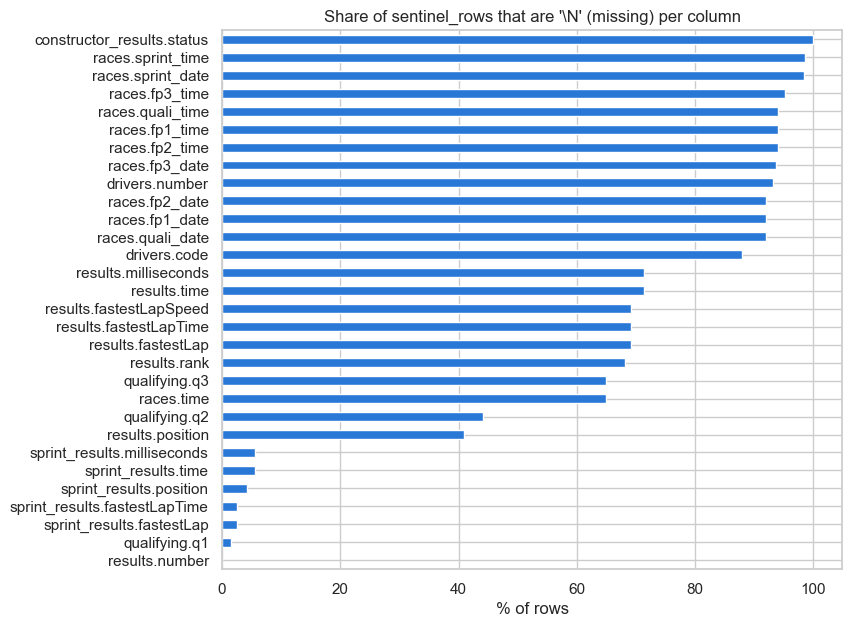

In [197]:
sentinel_rows = []
for name, df in raw.items():
    for col in df.columns:
        count = (df[col].astype(str) == MISSING).sum()
        if count > 0:
            sentinel_rows.append({"column": name + "." + col, "count": count, "percent": 100 * count / len(df)})
missing = pd.DataFrame(sentinel_rows).sort_values("percent")

print("Missing values pandas finds in raw results:", raw["results"].isna().sum().sum())
print(r"\N values actually in raw results:", missing.loc[missing["column"].str.startswith("results."), "count"].sum())

missing.plot.barh(x="column", y="percent", figsize=(8, 7), legend=False)
plt.title(r"Share of sentinel_rows that are '\N' (missing) per column")
plt.xlabel("% of rows")
plt.ylabel("")
plt.show()

In [198]:
# One '\N' is enough to turn a whole numeric column into text
pd.DataFrame({"raw dtype": raw["results"].dtypes, r"dtype with \N as missing": data["results"].dtypes})

,raw dtype,dtype with \N as missing
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,object,float64
grid,int64,int64
position,object,float64
positionText,object,object
positionOrder,int64,int64
points,float64,float64


- pandas finds **0** missing values in raw `results`, but there are **122,887** `\N` values. The missing data is hidden.
- Because of `\N`, numeric columns like `position`, `milliseconds`, and `rank` are read as text. Reading `\N` as
  missing fixes this.
- Many columns are mostly empty (e.g. `constructor_results.status` 100%, practice-session dates in `races` over 90%).
- Dates (`races.date`, `drivers.dob`) and lap times (`q1`–`q3`, e.g. `"1:26.572"`) are still text.

**Next (1.2):** convert dates to dates and lap times to seconds, and drop the mostly-empty columns.

#### 1.1.3 Data coverage over time

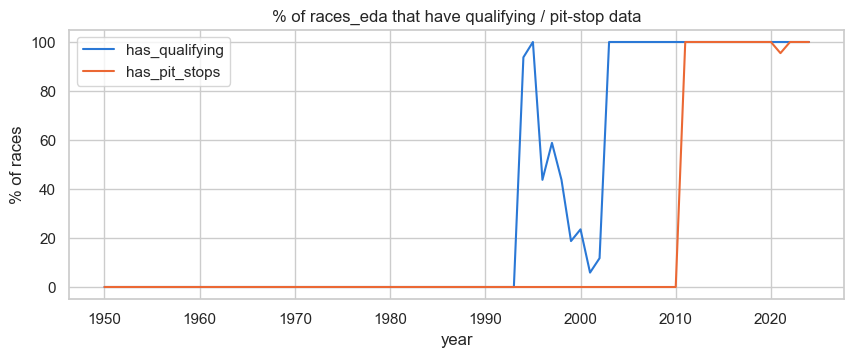

year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
has_qualifying,94.0,100.0,44.0,59.0,44.0,19.0,24.0,6.0,12.0,100.0,100.0


In [199]:
races_eda = data["races"].copy()
races_eda["has_qualifying"] = races_eda["raceId"].isin(data["qualifying"]["raceId"])
races_eda["has_pit_stops"] = races_eda["raceId"].isin(data["pit_stops"]["raceId"])
coverage = races_eda.groupby("year")[["has_qualifying", "has_pit_stops"]].mean() * 100

coverage.plot(figsize=(10, 3.5))
plt.title("% of races_eda that have qualifying / pit-stop data")
plt.ylabel("% of races")
plt.show()

coverage.loc[1994:2004, ["has_qualifying"]].T.round(0)

- Qualifying data starts in **1994**, but between 1996 and 2002 only part of the races have it. It is complete from **2003**.
- Pit-stop data only exists from 2011.
- Since qualifying is one of our most important pre-race inputs, we will most likely model the seasons
  **2003–2024**. This is also a limitation to mention in the report.

#### 1.1.4 Duplicate rows: is (raceId, driverId) unique?

In [200]:
results_eda = data["results"].merge(races_eda[["raceId", "year"]], on="raceId")

duplicates = results_eda[results_eda.duplicated(["raceId", "driverId"], keep=False)]
print("Duplicated rows:", len(duplicates))
print("Driver-race pairs affected:", duplicates.groupby(["raceId", "driverId"]).ngroups)
print("Years:", duplicates["year"].min(), "to", duplicates["year"].max())

duplicates.sort_values(["raceId", "driverId"])[
    ["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "points"]].head(6)

Duplicated rows: 176
Driver-race pairs affected: 85
Years: 1950 to 1978


,raceId,year,driverId,constructorId,grid,positionOrder,points
13188,540,1978,229,54,0,26,0.0
13191,540,1978,229,57,0,29,0.0
17362,717,1964,373,172,1,7,0.0
24298,717,1964,373,172,1,12,0.0
17740,733,1962,465,172,0,22,0.0
17743,733,1962,465,97,0,25,0.0


- 85 driver-race pairs appear more than once (176 rows), all between 1950 and 1978.
- These are **shared drives**: in early F1 drivers could swap cars during a race, so one driver gets two result rows.
- **Next (1.4):** choose a rule for which row to keep, so each driver appears once per race.

#### 1.1.5 The target: podium finishes

Podium rate: 12.7%


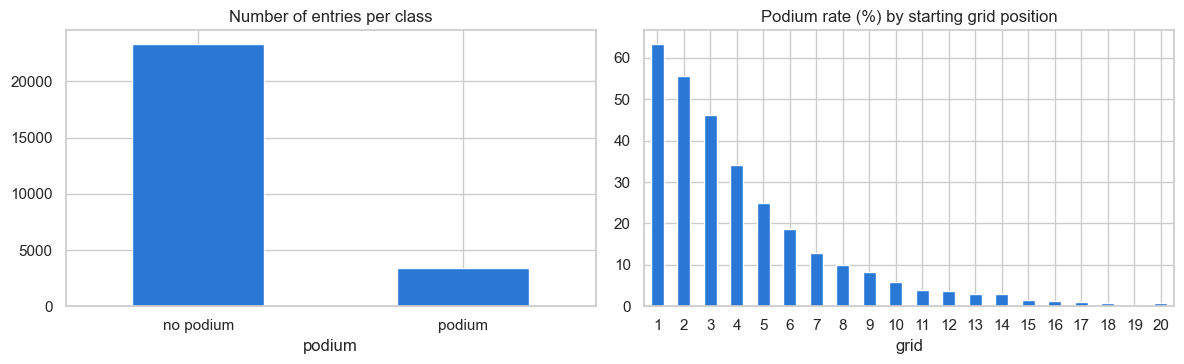

In [201]:
results_eda["podium"] = results_eda["positionOrder"] <= 3
print(f"Podium rate: {results_eda['podium'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
results_eda["podium"].map({True: "podium", False: "no podium"}).value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Number of entries per class")

podium_by_grid = results_eda[results_eda["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100
podium_by_grid.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Podium rate (%) by starting grid position")
plt.tight_layout()
plt.show()

- Only **12.7%** of entries are podiums, so the classes are imbalanced. Accuracy would be misleading, which is
  why we will use PR-AUC and F1.
- The starting position matters a lot: starting from pole gives a 63% podium rate, P3 gives 46%, and past P10 it is
  below 5%. Grid and qualifying position will be our core features.

#### 1.1.6 Race outcomes and special values

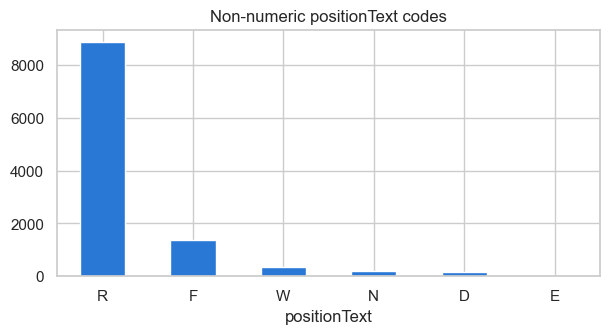

Entries with grid = 0: 1638
Podiums from grid = 0: 0
Grid differs from qualifying position: 23%


In [202]:
codes = results_eda.loc[~results_eda["positionText"].str.isnumeric(), "positionText"].value_counts()
codes.plot.bar(figsize=(7, 3.2), rot=0)
plt.title("Non-numeric positionText codes")
plt.show()

print("Entries with grid = 0:", (results_eda["grid"] == 0).sum())
print("Podiums from grid = 0:", results_eda.loc[results_eda["grid"] == 0, "podium"].sum())

quali_eda = data["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
grid_vs_quali = results_eda.merge(quali_eda, on=["raceId", "driverId"])
grid_vs_quali = grid_vs_quali[grid_vs_quali["grid"] > 0]
print(f"Grid differs from qualifying position: {(grid_vs_quali['grid'] != grid_vs_quali['quali_position']).mean():.0%}")

- `positionText` is not always a number: **R** = retired, **F** = failed to qualify, **W** = withdrawn,
  **N** = not classified, **D** = disqualified, **E** = excluded.
- **F** and **W** drivers never started the race, which is already known before the race, so they will be removed
  from the modelling table.
- `grid = 0` is not a real position (a non-qualifier, or a pit-lane start in modern races) and nobody ever reached
  the podium from it. It is a code, not a missing value, so it is kept and handled when we build features.
- The grid differs from the qualifying position for **23%** of entries (mostly penalties), so both are kept as
  separate features.

#### 1.1.7 Summary

| Finding | What we will do |
|---|---|
| `\N` hides missing values and turns numbers into text | Read `\N` as missing; convert dates and lap times (1.2) |
| Mostly-empty columns (practice dates, `constructor_results.status`) | Drop them (1.2) |
| 85 duplicated driver-race pairs (shared drives, 1950–1978) | Keep one row per driver per race (1.4) |
| Qualifying data complete only from 2003 | Model seasons 2003–2024; note it as a limitation |
| Only 12.7% podiums | Use PR-AUC / F1 and handle class imbalance (4) |
| Grid position strongly predicts podiums; grid ≠ qualifying position | Use both as features (3) |
| F/W entries never started; `grid = 0` is a special value | Remove F/W; keep `grid = 0` as a code (pit-lane start / did not qualify) |

### 1.2 Sentinel Handling and Semantic Typing

We clean **copies** of the tables (`clean`). `raw` stays exactly as loaded, and the CSV files are never changed.

Steps: (1) replace the `\N` placeholder with a real missing value, (2) drop columns we will not use,
(3) turn number-like text into numbers, (4) parse dates, (5) convert lap and pit-stop times to seconds,
(6) blank impossible lap times,
(7) standardise category spellings, (8) fix impossible or contradictory values, (9) check the result.

**`grid = 0` is not a missing value.** It is a code meaning the driver did not start from a grid slot: a pit-lane
start, or a driver who did not qualify. It is kept unchanged here and handled when we build features (section 3).

#### 1.2.1 Replace `\N` with a real missing value

In [ ]:
clean = {name: df.copy() for name, df in raw.items()}

for df in clean.values():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col].dtype):
            df[col] = df[col].str.strip().replace(MISSING, np.nan)   # strip also fixes values like "Argentinian "

remaining = sum((df[col].astype(str) == MISSING).sum() for df in clean.values() for col in df.columns)
assert remaining == 0
print(r"\N values left in any table:", remaining)

#### 1.2.2 Drop columns we will not use

In [ ]:
drop_plan = pd.DataFrame([
    ("all tables", "url", "Wikipedia link, no analytical value"),
    ("races", "fp1/fp2/fp3, quali, sprint date + time", "over 90% missing (only recent seasons); sessions not used"),
    ("races", "time", "65% missing; start time of day is not needed"),
    ("drivers", "number", "93% missing; permanent car number is just a label"),
    ("results, sprint_results", "time", "mixed format (winner's total time vs. '+gap'); same info is in milliseconds"),
    ("constructor_results", "status", "99.9% missing"),
], columns=["table", "column(s)", "reason"])

session_cols = [f"{s}_{p}" for s in ["fp1", "fp2", "fp3", "quali", "sprint"] for p in ["date", "time"]]
to_drop = {
    "races": ["url", "time"] + session_cols,
    "drivers": ["url", "number"],
    "circuits": ["url"], "constructors": ["url"], "seasons": ["url"],
    "results": ["time"], "sprint_results": ["time"],
    "constructor_results": ["status"],
}
for name, cols in to_drop.items():
    clean[name] = clean[name].drop(columns=cols)

drop_plan

,table,column(s),reason
0,all tables,url,"Wikipedia link, no analytical value"
1,races,"fp1/fp2/fp3, quali, sprint date + time",over 90% missing (only recent seasons); sessio...
2,races,time,65% missing; start time of day is not needed
3,drivers,number,93% missing; permanent car number is just a label
4,"results, sprint_results",time,mixed format (winner's total time vs. '+gap');...
5,constructor_results,status,99.9% missing


#### 1.2.3 Turn number-like text into numbers

In [ ]:
# A text column becomes numeric only if every non-missing value is a number
converted = []
for name, df in clean.items():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col].dtype):
            as_number = pd.to_numeric(df[col], errors="coerce")
            if as_number.notna().sum() == df[col].notna().sum():
                df[col] = as_number
                converted.append(f"{name}.{col}")

print("Converted to numbers:", converted)

Converted to numbers: ['results.number', 'results.position', 'results.milliseconds', 'results.fastestLap', 'results.rank', 'results.fastestLapSpeed', 'sprint_results.position', 'sprint_results.milliseconds', 'sprint_results.fastestLap']


#### 1.2.4 Parse dates

In [ ]:
clean["races"]["date"] = pd.to_datetime(clean["races"]["date"], format="%Y-%m-%d")
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"], format="%Y-%m-%d")

clean["races"]["date"].agg(["min", "max"])

min   1950-05-13
max   2024-12-08
Name: date, dtype: datetime64[ns]

#### 1.2.5 Convert lap and pit-stop times to seconds

In [ ]:
def to_seconds(value):
    """'1:26.572' -> 86.572, '1:34:50.616' -> 5690.616, '26.898' -> 26.898. Missing stays missing."""
    if pd.isna(value):
        return np.nan
    seconds = 0.0
    for part in str(value).split(":"):
        seconds = seconds * 60 + float(part)
    return seconds


for col in ["q1", "q2", "q3"]:
    clean["qualifying"][col] = clean["qualifying"][col].map(to_seconds)
clean["results"]["fastestLapTime"] = clean["results"]["fastestLapTime"].map(to_seconds)
clean["sprint_results"]["fastestLapTime"] = clean["sprint_results"]["fastestLapTime"].map(to_seconds)
clean["lap_times"]["time"] = clean["lap_times"]["time"].map(to_seconds)
clean["pit_stops"]["duration"] = clean["pit_stops"]["duration"].map(to_seconds)

# Check the parser: these two tables also store the same time in milliseconds
for table, col in [("lap_times", "time"), ("pit_stops", "duration")]:
    df = clean[table]
    match = np.isclose(df[col], df["milliseconds"] / 1000, atol=0.001).mean()
    print(f"{table}.{col}: parsed seconds == milliseconds / 1000 for {match:.2%} of rows")

clean["qualifying"][["q1", "q2", "q3"]].head(3)

lap_times.time: parsed seconds == milliseconds / 1000 for 100.00% of rows
pit_stops.duration: parsed seconds == milliseconds / 1000 for 100.00% of rows


,q1,q2,q3
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079


#### 1.2.6 Blank impossible lap times

**Why:** the post-cleaning EDA (1.5.3) revealed one Q1 time of `16:42.640` (1,002.6 s) in the 1995 Japanese Grand
Prix, while the fastest Q1 time of that session was about 1:38 and the median about 1:41. A qualifying lap ten times
slower than everyone else's is not physically possible, so it is a **recording error**.

**Rule:** a qualifying time more than **twice the median of the same session** (same race, same Q1/Q2/Q3) is a
recording error and becomes **missing**. Only the value is blanked; the row (driver, team, qualifying position) is
kept. The rule covers all three sessions, so any similar error would also be caught.

**Why we do not guess the true time:** an obvious typo correction such as `1:42.640` would be faster than the drivers
who qualified 17th–23rd, but this driver qualified **24th (last)** and started last on the grid, so his real time
was slower than 1:48.289. The data cannot tell us the exact value, so a missing value is the honest choice.

In [ ]:
quali_clean = clean["qualifying"]
fixed = []
for col in ["q1", "q2", "q3"]:
    session_median = quali_clean.groupby("raceId")[col].transform("median")
    impossible = quali_clean[col] > 2 * session_median
    for i in quali_clean.index[impossible]:
        fixed.append({"raceId": quali_clean.at[i, "raceId"], "driverId": quali_clean.at[i, "driverId"], "session": col,
                      "raw value": raw["qualifying"].at[i, col], "seconds": quali_clean.at[i, col],
                      "session median (s)": round(session_median[i], 1)})
    quali_clean.loc[impossible, col] = np.nan

print("Impossible qualifying times set to missing:", len(fixed))
pd.DataFrame(fixed).merge(clean["races"][["raceId", "year", "name"]], on="raceId")

Impossible qualifying times set to missing: 1


,raceId,driverId,session,raw value,seconds,session median (s),year,name
0,255,87,q1,16:42.640,1002.64,101.5,1995,Japanese Grand Prix


#### 1.2.7 Standardise category spellings

The same value must always be written the same way, otherwise a filter or a join silently misses rows (e.g. a
country filter on `"USA"` would miss the circuit stored as `"United States"`). We check every text category column
of every table in two ways:
1. **Automatically:** values that become identical once case, spaces, and accents are ignored.
2. **By reading the distinct values:** synonyms such as "USA" / "United States" do not look alike as text, so no
   automatic rule can find them.

In [ ]:
import re
import unicodedata


def simplify(text):
    """Lower-case, remove accents, spaces, and punctuation: 'São Paulo ' -> 'saopaulo'."""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", text.lower())


category_columns = {"circuits": ["country", "location", "name"], "drivers": ["nationality"],
                    "constructors": ["nationality", "name"], "status": ["status"], "races": ["name"]}
near_duplicates = []
for table, cols in category_columns.items():
    for col in cols:
        values = pd.Series(clean[table][col].dropna().unique())
        for spellings in values.groupby(values.map(simplify)).agg(list):
            if len(spellings) > 1:
                near_duplicates.append({"column": f"{table}.{col}", "spellings": spellings})
print("1) Values that differ only in case, spaces, or accents:", len(near_duplicates))

print("2) Distinct values, read by eye:")
print("   circuits.country:", sorted(clean["circuits"]["country"].unique()))
print("   drivers.nationality:", sorted(clean["drivers"]["nationality"].unique()))

1) Values that differ only in case, spaces, or accents: 0
2) Distinct values, read by eye:
   circuits.country: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']
   drivers.nationality: ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spani

In [ ]:
spelling_fixes = pd.DataFrame([
    ("circuits", "country", "United States", "USA",
     "same country; 'USA' is used by 11 of the 12 circuits in the United States"),
    ("drivers", "nationality", "Argentinian", "Argentine",
     "same nationality; 'Argentine' is used by 24 of the 25 Argentine drivers"),
], columns=["table", "column", "old value", "new value", "reason"])

rows_changed = []
for _, fix in spelling_fixes.iterrows():
    df = clean[fix["table"]]
    old = df[fix["column"]] == fix["old value"]
    rows_changed.append(old.sum())
    df.loc[old, fix["column"]] = fix["new value"]
    assert not (df[fix["column"]] == fix["old value"]).any()
spelling_fixes["rows changed"] = rows_changed
spelling_fixes

,table,column,old value,new value,reason,rows changed
0,circuits,country,United States,USA,same country; 'USA' is used by 11 of the 12 ci...,1
1,drivers,nationality,Argentinian,Argentine,same nationality; 'Argentine' is used by 24 of...,1


- **Automatic check:** no value differs from another only by case, spaces, or accents (the one stray space,
  `"Argentinian "`, was already removed in 1.2.1).
- **Reading the values** found two synonyms, now fixed: the Las Vegas Strip circuit was the only one stored as
  "United States" instead of "USA", and one driver (2024) was "Argentinian" instead of "Argentine".
- **Checked and deliberately kept:** "East German" vs. "German" (two different countries at the time), dual
  nationalities such as "American-Italian" (real values), team renames such as Toro Rosso → AlphaTauri (kept as
  separate team ids, see 1.2.8 f), and the 139 status texts (all distinct).

#### 1.2.8 Fix impossible or contradictory values

We checked every table with plausibility rules (values that cannot happen in a race) and consistency rules
(two columns or two tables that must agree). Each rule that found a **real error** is fixed below; the reason is in
the comment. Values we cannot reconstruct are set to **missing** rather than guessed.

In [ ]:
results_clean = clean["results"]

# (a) A classified driver (numeric positionText, e.g. "11") must have a finishing position
classified_no_position = results_clean["position"].isna() & results_clean["positionText"].str.isnumeric()
fix_a = classified_no_position.sum()
results_clean.loc[classified_no_position, "position"] = results_clean.loc[classified_no_position, "positionText"].astype(float)

# (b) milliseconds is the total race time; an average lap under 40 s is impossible (no F1 lap is that fast),
#     so these values are not race times (they are gaps to a disqualified driver) -> missing
impossible_race_time = (results_clean["milliseconds"] / results_clean["laps"]) < 40_000
fix_b = impossible_race_time.sum()
results_clean.loc[impossible_race_time, "milliseconds"] = np.nan

# (c) The fastest lap cannot happen after the driver's last lap -> the fastest-lap record is wrong -> missing
fastest_after_last_lap = results_clean["fastestLap"] > results_clean["laps"]
fix_c = fastest_after_last_lap.sum()
results_clean.loc[fastest_after_last_lap, ["fastestLap", "rank", "fastestLapTime", "fastestLapSpeed"]] = np.nan

# (d) A driver cannot make their 51st stop on lap 2: stop and lap were swapped -> swap them back
pits = clean["pit_stops"]
stop_after_lap = pits["stop"] > pits["lap"]
fix_d = stop_after_lap.sum()
pits.loc[stop_after_lap, ["stop", "lap"]] = pits.loc[stop_after_lap, ["lap", "stop"]].values

# (e) A team cannot have a points row in a race where it had no car. These rows use an old or wrong team id
#     (the cars raced under another id, see the note below) -> remove
team_result = clean["constructor_results"]
has_car = (team_result.set_index(["raceId", "constructorId"]).index
           .isin(clean["results"].set_index(["raceId", "constructorId"]).index))
removed_e = team_result[~has_car]
fix_e = len(removed_e)
clean["constructor_results"] = team_result[has_car].reset_index(drop=True)

# (f) A driver's team in qualifying must be the team they raced for. In 2015 qualifying still used Marussia's
#     old id while results used Manor Marussia's id -> take the team from results
race_team = clean["results"][["raceId", "driverId", "constructorId"]]
quali_team = clean["qualifying"].merge(race_team, on=["raceId", "driverId"], how="left", suffixes=("", "_race"))
team_differs = (quali_team["constructorId_race"].notna()
                & (quali_team["constructorId"] != quali_team["constructorId_race"])).values
fix_f = team_differs.sum()
team_fixed_races = clean["qualifying"].loc[team_differs, "raceId"]
clean["qualifying"].loc[team_differs, "constructorId"] = quali_team.loc[team_differs, "constructorId_race"].values

pd.DataFrame({
    "rule": ["(a) classified but no finishing position", "(b) race time faster than any possible lap",
             "(c) fastest lap after the driver's last lap", "(d) pit stop number larger than the lap number",
             "(e) team points in a race without a car of that team",
             "(f) qualifying team differs from the race team"],
    "table": ["results", "results", "results", "pit_stops", "constructor_results", "qualifying"],
    "rows fixed": [fix_a, fix_b, fix_c, fix_d, fix_e, fix_f],
    "fix": ["position = positionText", "milliseconds -> missing", "fastest-lap fields -> missing",
            "swap stop and lap", "row removed", "team id from results"],
})

,rule,table,rows fixed,fix
0,(a) classified but no finishing position,results,2,position = positionText
1,(b) race time faster than any possible lap,results,18,milliseconds -> missing
2,(c) fastest lap after the driver's last lap,results,12,fastest-lap fields -> missing
3,(d) pit stop number larger than the lap number,pit_stops,7,swap stop and lap
4,(e) team points in a race without a car of tha...,constructor_results,7,row removed
5,(f) qualifying team differs from the race team,qualifying,10,team id from results


In [ ]:
# Which races the errors were in
race_label = clean["races"]["year"].astype(str) + " " + clean["races"]["name"]
race_label.index = clean["races"]["raceId"]
affected = {
    "(a)": results_clean.loc[classified_no_position, "raceId"],
    "(b)": results_clean.loc[impossible_race_time, "raceId"],
    "(c)": results_clean.loc[fastest_after_last_lap, "raceId"],
    "(d)": pits.loc[stop_after_lap, "raceId"],
    "(e)": removed_e["raceId"],
    "(f)": team_fixed_races,
}
for rule, ids in affected.items():
    print(rule, ", ".join(race_label[ids.unique()]))

(a) 2005 Australian Grand Prix
(b) 2024 Belgian Grand Prix
(c) 2008 British Grand Prix, 2014 Australian Grand Prix, 2018 Italian Grand Prix, 2018 United States Grand Prix, 2024 São Paulo Grand Prix
(d) 2024 Monaco Grand Prix
(e) 2002 Australian Grand Prix, 1979 South African Grand Prix, 1979 Austrian Grand Prix, 2015 Belgian Grand Prix, 2015 Russian Grand Prix, 2015 Mexican Grand Prix, 2015 Abu Dhabi Grand Prix
(f) 2015 Belgian Grand Prix, 2015 Russian Grand Prix, 2015 United States Grand Prix, 2015 Mexican Grand Prix, 2015 Brazilian Grand Prix


In [ ]:
# Verify: every fixed rule now finds 0 rows
quali_check = clean["qualifying"].merge(race_team, on=["raceId", "driverId"], how="left", suffixes=("", "_race"))
after = {
    "(a) classified but no finishing position": (results_clean["position"].isna() & results_clean["positionText"].str.isnumeric()).sum(),
    "(b) race time faster than any possible lap": ((results_clean["milliseconds"] / results_clean["laps"]) < 40_000).sum(),
    "(c) fastest lap after the driver's last lap": (results_clean["fastestLap"] > results_clean["laps"]).sum(),
    "(d) pit stop number larger than the lap number": (clean["pit_stops"]["stop"] > clean["pit_stops"]["lap"]).sum(),
    "(e) team points in a race without a car of that team": (~clean["constructor_results"]
        .set_index(["raceId", "constructorId"]).index
        .isin(clean["results"].set_index(["raceId", "constructorId"]).index)).sum(),
    "(f) qualifying team differs from the race team": (quali_check["constructorId_race"].notna()
        & (quali_check["constructorId"] != quali_check["constructorId_race"])).sum(),
}
assert all(count == 0 for count in after.values())
pd.Series(after, name="rows breaking the rule after the fix").to_frame()

,rows breaking the rule after the fix
(a) classified but no finishing position,0
(b) race time faster than any possible lap,0
(c) fastest lap after the driver's last lap,0
(d) pit stop number larger than the lap number,0
(e) team points in a race without a car of that team,0
(f) qualifying team differs from the race team,0


**What each fix corrected and why:**
- **(a) 2005 Australian GP, 2 drivers:** `positionText` says 11 and 14 (and both finished, a lap or two down), but
  `position` was empty. The finishing position is restored from `positionText`.
- **(b) 2024 Belgian GP, 18 drivers:** `milliseconds` should be the total race time, but it holds the gap to the
  disqualified driver (e.g. 526 ms for the winner of a 44-lap race). The true totals are unknown, so they become
  missing. The rule does not touch the genuinely short 2021 Belgian GP (one lap behind the safety car, 3:27).
- **(c) 12 drivers in 5 races (2008–2024):** the fastest lap is recorded on a lap after the driver stopped (e.g.
  lap 55 for a driver who completed 49 laps). The whole fastest-lap record (`fastestLap`, `rank`, `fastestLapTime`,
  `fastestLapSpeed`) is unreliable for these rows and becomes missing.
- **(d) 2024 Monaco GP, 7 pit stops:** from the second stop on, `stop` and `lap` were swapped ("stop 51 on lap 2"
  is really "stop 2 on lap 51"). They are swapped back.
- **(e) 7 team-points rows for a team id that had no car in that race:** Brabham (id 34) in two 1979 races, while the
  cars raced as Brabham-Alfa Romeo (id 204), so the 1979 South African point was counted twice; Marussia (id 206)
  in four 2015 races, while the cars raced as Manor Marussia (id 209), the same problem as (f); and BMW Sauber in the 2002 Australian GP, where the team raced as Sauber. The rows are removed; the
  correct team's rows remain.
- **(f) 2015, 10 qualifying rows in 5 races:** `qualifying` lists the two Manor Marussia drivers under the old
  Marussia id (206), while `results` uses Manor Marussia's id (209) for the same drivers in the same races: one team
  after a rename, not drivers changing teams. The qualifying rows now take the team from `results`. We keep the two
  ids themselves (206 for 2012–2014, 209 for 2015–2016), the same way the dataset stores every other team rename
  (e.g. Toro Rosso → AlphaTauri).

**Checked, but not errors (real Formula 1 rules), so they are kept:**
- 671 drivers are classified although their status is a retirement (e.g. "Engine"), and 24 were still running at the
  end but are not classified: a driver is classified only if they completed enough of the race distance.
- 1959 French GP: a disqualified driver kept 1 point, the separate point for the fastest lap at that time.
- Standings codes **D** (1997, a driver excluded from the championship) and **E** (2007, a team excluded) are real
  decisions, not typos.
- Team points differ from the sum of their drivers' points: before 1979 only a team's best car scored (292 of the
  302 differences), and since 2021 the team points include sprint points, which `results` does not.
- Driver codes are reused (7 pairs, e.g. "MSC" for Michael and Mick Schumacher): codes are labels, not ids.

**Conflicts between tables that cannot be repaired from the data (documented, kept):**
- `lap_times` vs. `results.laps`: 37 driver-races have more timed laps than `results` says, and 53 have fewer (gaps in
  the timing data), mostly 2001–2014. We cannot tell which source is right. `results` is the official classification,
  and lap times are not used as model features.
- `pit_stops`: two drivers have no record of their first stop (2014 British GP, 2019 Singapore GP).
- 10 of the 302 pre-1979 team-points differences are not explained by the best-car rule; `constructor_results` is not
  used in this project.
- Repeated grid slots in old races (1.3.3, check 3).

#### 1.2.9 Check the result

In [ ]:
def text_columns(df):
    return sum(pd.api.types.is_string_dtype(df[col].dtype) for col in df.columns)


# 1.2 changes values and types, not rows; the only removed rows are the wrong-team rows of 1.2.8 (e)
assert all(len(clean[name]) == len(raw[name]) for name in raw if name != "constructor_results")
assert len(clean["constructor_results"]) == len(raw["constructor_results"]) - fix_e
assert sum((df[col].astype(str) == MISSING).sum() for df in clean.values() for col in df.columns) == 0

pd.DataFrame({
    "text columns before": {name: text_columns(raw[name]) for name in raw},
    "text columns after": {name: text_columns(clean[name]) for name in raw},
})

,text columns before,text columns after
circuits,5,4
constructors,4,3
drivers,8,5
seasons,1,0
races,14,1
status,1,1
results,9,1
qualifying,3,0
sprint_results,6,1
driver_standings,1,1


In [ ]:
# Data types of the main table before and after cleaning
pd.DataFrame({
    "before": raw["results"].dtypes.astype(str),
    "after": clean["results"].dtypes.astype(str).reindex(raw["results"].columns, fill_value="dropped"),
})

,before,after
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,object,float64
grid,int64,int64
position,object,float64
positionText,object,object
positionOrder,int64,int64
points,float64,float64


- No `\N` is left anywhere, and 1.2 changed only values and types: the only removed rows are the 7 wrong-team rows
  of 1.2.8 (e). The `assert`s stop the notebook if this ever breaks.
- Numbers hidden as text (`position`, `milliseconds`, `rank`, ...) are now numeric, dates are real dates, and
  qualifying, lap, and pit-stop times are numbers in seconds (the parser agrees with the `milliseconds` columns).
- What is still text is real text: names, nationalities, `status`, `positionText` (codes such as R, F, W), and the
  pit-stop clock time.
- `grid = 0` is kept as a code (pit-lane start or did not qualify).
- The effect of cleaning on rows, columns, and missing values is compared in **1.5.1**.

### 1.3 Primary-Key and Foreign-Key Validation

Before joining tables we check that the links between them can be trusted:

- **Primary key:** the column(s) that identify one row. It must be unique and never missing.
- **Foreign key:** a column that points to a row in another table (e.g. `results.raceId → races`). Every value must
  exist in that table; a value that does not is an **orphan**.

All checks run on the cleaned tables (`clean`). If a primary or foreign key ever breaks, the `assert` stops the notebook.

#### 1.3.1 Primary keys: unique and never missing

In [ ]:
primary_keys = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "seasons": ["year"], "races": ["raceId"], "status": ["statusId"], "results": ["resultId"],
    "qualifying": ["qualifyId"], "sprint_results": ["resultId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"],      # no id column: one row per driver per lap
    "pit_stops": ["raceId", "driverId", "stop"],     # no id column: one row per driver per stop
}


def check_primary_key(df, columns):
    """Count duplicated keys and rows where part of the key is missing."""
    return {
        "key": ", ".join(columns),
        "rows": len(df),
        "duplicates": df.duplicated(columns).sum(),
        "missing": df[columns].isna().any(axis=1).sum(),
    }


pk_report = pd.DataFrame([{"table": name, **check_primary_key(clean[name], cols)}
                          for name, cols in primary_keys.items()])
pk_report["OK"] = (pk_report["duplicates"] == 0) & (pk_report["missing"] == 0)
assert pk_report["OK"].all()
pk_report

,table,key,rows,duplicates,missing,OK
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,seasons,year,75,0,0,True
4,races,raceId,1125,0,0,True
5,status,statusId,139,0,0,True
6,results,resultId,26759,0,0,True
7,qualifying,qualifyId,10494,0,0,True
8,sprint_results,resultId,360,0,0,True
9,driver_standings,driverStandingsId,34863,0,0,True


#### 1.3.2 Foreign keys: every reference exists

In [ ]:
# (child table, column, parent table) - the column has the same name in the parent table
foreign_keys = [
    ("races", "circuitId", "circuits"), ("races", "year", "seasons"),
    ("results", "raceId", "races"), ("results", "driverId", "drivers"),
    ("results", "constructorId", "constructors"), ("results", "statusId", "status"),
    ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
    ("qualifying", "constructorId", "constructors"),
    ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
    ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
    ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
    ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
    ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
    ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
    ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
]


def check_foreign_key(child, column, parent):
    """Count missing references and references that do not exist in the parent table (orphans)."""
    values = clean[child][column]
    return {
        "relationship": f"{child}.{column} → {parent}",
        "missing": values.isna().sum(),
        "orphans": (~values.dropna().isin(clean[parent][column])).sum(),
    }


fk_report = pd.DataFrame([check_foreign_key(*fk) for fk in foreign_keys])
fk_report["OK"] = (fk_report["missing"] == 0) & (fk_report["orphans"] == 0)
assert fk_report["OK"].all()
fk_report

,relationship,missing,orphans,OK
0,races.circuitId → circuits,0,0,True
1,races.year → seasons,0,0,True
2,results.raceId → races,0,0,True
3,results.driverId → drivers,0,0,True
4,results.constructorId → constructors,0,0,True
5,results.statusId → status,0,0,True
6,qualifying.raceId → races,0,0,True
7,qualifying.driverId → drivers,0,0,True
8,qualifying.constructorId → constructors,0,0,True
9,sprint_results.raceId → races,0,0,True


#### 1.3.3 Consistency checks within each race

In [ ]:
# Inside one race, some values should never repeat. Count the rows that break each rule.
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")

checks = {
    "same driver twice in a race": res.duplicated(["raceId", "driverId"], keep=False),
    "two drivers with the same finishing position": res.duplicated(["raceId", "positionOrder"], keep=False),
    "two drivers on the same grid slot (grid > 0)": (res["grid"] > 0) & res.duplicated(["raceId", "grid"], keep=False),
    "  ...of which not a shared car (different result)": ((res["grid"] > 0)
        & res.duplicated(["raceId", "grid"], keep=False)
        & ~res.duplicated(["raceId", "grid", "positionOrder"], keep=False)),
    "official position differs from positionOrder": res["position"].notna() & (res["position"] != res["positionOrder"]),
}
pd.DataFrame([{
    "check (results)": name,
    "rows": mask.sum(),
    "races": res.loc[mask, "raceId"].nunique(),
    "seasons": f"{res.loc[mask, 'year'].min()}–{res.loc[mask, 'year'].max()}" if mask.any() else "-",
    "races since 2003": res.loc[mask & (res["year"] >= 2003), "raceId"].nunique(),
} for name, mask in checks.items()])

,check (results),rows,races,seasons,races since 2003
0,same driver twice in a race,176,42,1950–1978,0
1,two drivers with the same finishing position,228,46,1950–1964,0
2,two drivers on the same grid slot (grid > 0),377,106,1950–2024,4
3,...of which not a shared car (different result),149,66,1950–2024,4
4,official position differs from positionOrder,13,1,1983–1983,0


In [ ]:
# The same kind of rules in the other tables (0 = consistent)
pd.Series({
    "races: two races with the same (year, round)": clean["races"].duplicated(["year", "round"]).sum(),
    "qualifying: one driver twice in a race": clean["qualifying"].duplicated(["raceId", "driverId"]).sum(),
    "qualifying: two drivers with the same position": clean["qualifying"].duplicated(["raceId", "position"]).sum(),
    "sprint_results: one driver twice in a sprint": clean["sprint_results"].duplicated(["raceId", "driverId"]).sum(),
    "driver_standings: one driver twice after a race": clean["driver_standings"].duplicated(["raceId", "driverId"]).sum(),
    "driver_standings: two drivers with the same position": clean["driver_standings"].duplicated(["raceId", "position"]).sum(),
    "constructor_standings: one team twice after a race": clean["constructor_standings"].duplicated(["raceId", "constructorId"]).sum(),
    "constructor_results: one team twice in a race": clean["constructor_results"].duplicated(["raceId", "constructorId"]).sum(),
    "results: negative grid, laps, or points": (clean["results"][["grid", "laps", "points"]] < 0).any(axis=1).sum(),
}, name="rows breaking the rule").to_frame()

,rows breaking the rule
"races: two races with the same (year, round)",0
qualifying: one driver twice in a race,0
qualifying: two drivers with the same position,0
sprint_results: one driver twice in a sprint,0
driver_standings: one driver twice after a race,0
driver_standings: two drivers with the same position,0
constructor_standings: one team twice after a race,0
constructor_results: one team twice in a race,0
"results: negative grid, laps, or points",0


In [ ]:
# The one race where position and positionOrder disagree: the official result has no 2nd place
odd_race = res.loc[checks["official position differs from positionOrder"], "raceId"].iloc[0]
(res[res["raceId"] == odd_race].sort_values("positionOrder")
 [["raceId", "year", "driverId", "position", "positionText", "positionOrder", "points"]].head(4))

,raceId,year,driverId,position,positionText,positionOrder,points
10655,452,1983,137,1.0,1,1,9.0
10656,452,1983,182,3.0,3,2,4.0
10657,452,1983,172,4.0,4,3,3.0
10658,452,1983,175,5.0,5,4,2.0


| # | Inconsistency | Cause | What we do |
|---|---|---|---|
| 1 | Same driver twice in a race (85 driver-race pairs in 42 races, 1950–1978) | **Shared drives**: a driver drove two cars in one race | Fixed in **1.4** with a documented keep rule |
| 2 | Two drivers with the same finishing position (46 races, 1950–1964) | **Shared car**: both drivers are credited with that car's result | **Kept.** It is correct history; it also explains why some old races have more than three podium rows |
| 3 | Two drivers on the same grid slot (106 races) | Partly **shared cars** (same grid slot *and* same result: one car, two drivers); the rest, where the two drivers have different results, are recording errors (149 rows in 66 races) | **Kept.** Shared cars are correct history; for the rest, the data cannot tell which value is right. Only 4 races since 2003 are affected, and there the qualifying position is a second source |
| 4 | `position` ≠ `positionOrder` (13 rows, one race in 1983) | The official result leaves 2nd place empty (that finisher was disqualified and nobody moved up); `positionOrder` renumbers 1, 2, 3, ... | **Kept.** The target uses `positionOrder`, as the task defines it |

All other tables pass every rule (0 rows in the table above).

#### 1.3.4 Cross-table consistency

In [ ]:
# Does every driver-race pair in the detail tables also appear in results?
results_pairs = clean["results"][["raceId", "driverId"]].drop_duplicates()


def pairs_not_in_results(table):
    pairs = clean[table][["raceId", "driverId"]].drop_duplicates()
    merged = pairs.merge(results_pairs, how="left", indicator=True)
    return merged[merged["_merge"] == "left_only"].drop(columns="_merge")


pd.Series({table: len(pairs_not_in_results(table))
           for table in ["qualifying", "sprint_results", "lap_times", "pit_stops", "driver_standings"]},
          name="driver-race pairs not in results").to_frame()

,driver-race pairs not in results
qualifying,0
sprint_results,0
lap_times,0
pit_stops,0
driver_standings,8664


In [ ]:
# Why driver_standings has extra pairs: did those drivers race in other rounds of the same season?
race_year = clean["races"][["raceId", "year", "round"]]
not_raced = pairs_not_in_results("driver_standings").merge(race_year, on="raceId")
season_drivers = results_pairs.merge(race_year, on="raceId")[["year", "driverId"]].drop_duplicates()
share = not_raced.merge(season_drivers, on=["year", "driverId"]).shape[0] / len(not_raced)
print(f"Standings rows for a race the driver did not enter: {len(not_raced):,}")
print(f"...of which the driver raced in another round of that season: {share:.1%}")

# Where do these rows fall compared with the driver's own races that season?
rounds = (results_pairs.merge(race_year, on="raceId")
          .groupby(["driverId", "year"])["round"].agg(first_race="min", last_race="max").reset_index())
timing = not_raced.merge(rounds, on=["driverId", "year"])
pd.Series({
    "before the driver's first race of the season": (timing["round"] < timing["first_race"]).sum(),
    "between two of the driver's races": ((timing["round"] > timing["first_race"]) & (timing["round"] < timing["last_race"])).sum(),
    "after the driver's last race of the season": (timing["round"] > timing["last_race"]).sum(),
}, name="standings rows").to_frame()

Standings rows for a race the driver did not enter: 8,664
...of which the driver raced in another round of that season: 100.0%


,standings rows
before the driver's first race of the season,0
between two of the driver's races,1705
after the driver's last race of the season,6959


In [ ]:
# Is every driver listed with the same team in qualifying and in the race? (fixed in 1.2.8 f)
teams = clean["qualifying"].merge(clean["results"][["raceId", "driverId", "constructorId"]],
                                  on=["raceId", "driverId"], suffixes=("_quali", "_race"))
mismatch = (teams["constructorId_quali"] != teams["constructorId_race"]).sum()
assert mismatch == 0
print("Drivers with a different team in qualifying and in the race:", mismatch)

Drivers with a different team in qualifying and in the race: 0


- `qualifying`, `sprint_results`, `lap_times`, and `pit_stops` only contain drivers who are in `results` for that race.
- `driver_standings` has **8,664** extra driver-race pairs. This is **not an error**. `driver_standings` is the
  championship table after each race. Once a driver has raced in a season, the table keeps listing them in every
  later round, with their points frozen, even in rounds they did not enter. The table above confirms this: no such
  row comes before a driver's first race; they all come between two of the driver's races or after their last one,
  and in 100% of cases the driver raced in another round of that season.
  **Consequence for section 3:** the standings row of a race already includes that race's result. A driver's
  standing *before* a race must therefore be taken from the **previous** round of `driver_standings`, never from the
  same race.
- **Team ids:** every driver now has the same team in qualifying and in the race (0 mismatches). The 10 mismatches in
  the raw data were one rebranded team in 2015 (Marussia in qualifying vs. Manor Marussia in the race), fixed in
  **1.2.8 (f)**.

#### 1.3.5 Conclusion

| Check | Result |
|---|---|
| Primary keys (14 tables) | All unique and never missing |
| Foreign keys (23 relationships) | No missing references, no orphans |
| Consistency within a race | 4 issues, all in `results`: shared drives (fixed in **1.4**), shared cars and the 1983 vacant place (correct history, kept), and repeated grid slots that are not shared cars (66 races, recording errors, noted) |
| Cross-table consistency | Detail tables match `results`; standings keep listing drivers in rounds they skipped (handled in section 3); every driver has the same team in qualifying and in the race (fixed in 1.2.8 f) |

The tables can be joined safely. The remaining structural problem is the duplicated driver-race rows in `results`,
which are fixed in **1.4**.

### 1.4 Driver-Race Grain and Shared-Drive Duplicate Handling

**Why the grain matters.** Our model answers one question per row: *"will this driver finish on the podium in
this race?"*. So the modelling table must have **exactly one row per (`raceId`, `driverId`)**. If a driver appeared
twice in the same race, that race-driver would be counted twice in training and evaluation, and the two rows could
even carry contradictory labels (one podium, one not).

Section 1.3.3 showed that `results` breaks this rule. This section explains why, compares three ways to fix it, applies
the chosen rule, and verifies the result.

#### 1.4.1 The problem: shared drives

In [ ]:
results_before = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
results_before["podium"] = results_before["positionOrder"] <= 3

dups = results_before[results_before.duplicated(["raceId", "driverId"], keep=False)]
pairs = dups.groupby(["raceId", "driverId"])

print(f"Driver-race pairs that appear more than once: {pairs.ngroups}")
print(f"Rows involved: {len(dups)}  ->  extra rows to remove: {len(dups) - pairs.ngroups}")
print(f"Seasons: {dups['year'].min()}–{dups['year'].max()}")
print("Rows per pair:", pairs.size().value_counts().to_dict())
print("Pairs where every row has a real grid slot (grid > 0):", pairs["grid"].apply(lambda g: (g > 0).all()).sum())
print("Pairs with a podium in at least one row:", pairs["podium"].any().sum())

Driver-race pairs that appear more than once: 85
Rows involved: 176  ->  extra rows to remove: 91
Seasons: 1950–1978
Rows per pair: {2: 79, 3: 6}
Pairs where every row has a real grid slot (grid > 0): 82
Pairs with a podium in at least one row: 22


In [ ]:
# One shared drive in detail: the first pair that includes a podium
example_race, example_driver = pairs["podium"].any().loc[lambda s: s].index[0]
(dups[(dups["raceId"] == example_race) & (dups["driverId"] == example_driver)]
 .merge(clean["status"], on="statusId")
 [["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "status"]])

,raceId,year,driverId,constructorId,grid,positionOrder,points,laps,status
0,746,1960,475,170,1,17,0.0,40,Suspension
1,746,1960,475,170,8,3,0.0,80,Finished


**What a shared drive is.** In early Formula 1 (mainly the 1950s), a team could move a driver into a different car
during the race, for example when the driver's own car broke down. The dataset stores **one row per car**, not one
row per driver, so a driver who drove two cars in a race gets two rows (and three rows if they drove three cars).

**The size of the problem.**
- **85 driver-race pairs** appear more than once: 79 with 2 rows and 6 with 3 rows. That is 176 rows, of which
  **91 are extra** and must go.
- All of them are from **1950–1978**. There are none in the 2003–2024 seasons we plan to model, but the
  data-engineering questions in section 2 use all seasons, so the fix matters there.
- **22 pairs include a podium** in at least one row, so the choice of rule changes the target for those drivers.

**Reading the example above.** Both rows describe the same driver in the same race (1960, same team):
- Row 1 is the driver's own car. It started from **grid 1**, retired with a suspension failure after **40 laps**, and
  is classified 17th.
- Row 2 is a second car of the same team. It started from **grid 8**, ran all **80 laps**, and **finished 3rd**.
  The driver took this car over during the race.

Important: `grid` and `laps` describe the **car**, not the driver. In 82 of the 85 pairs every row has a real grid
slot, so the data cannot tell us which car the driver started in. A rule like "keep the car the driver started
in" is therefore not reliable, and we choose between the three rules below instead.

#### 1.4.2 Choosing a rule: three candidates compared

We compare three rules for turning each duplicated pair into one row:

- **A: keep the row with the best finishing position** (lowest `positionOrder`). The driver is credited with the best
  result they achieved in that race.
- **B: keep the first row** (lowest `resultId`), i.e. the row that happens to come first in the file.
- **C: drop every duplicated pair**, i.e. remove all rows of the 85 driver-race pairs.

The comparison counts, for the 85 pairs, how many podiums each rule keeps and how many it **loses**: a podium is lost
when the driver did reach the podium in one of their cars, but the rule keeps a non-podium row (or no row at all).

In [ ]:
def keep_best(df):
    """Rule A: per driver-race pair, keep the row with the lowest positionOrder."""
    return df.sort_values(["raceId", "driverId", "positionOrder"]).drop_duplicates(["raceId", "driverId"])


def keep_first(df):
    """Rule B: per driver-race pair, keep the row with the lowest resultId."""
    return df.sort_values("resultId").drop_duplicates(["raceId", "driverId"])


def drop_all(df):
    """Rule C: remove every row of a duplicated driver-race pair."""
    return df[~df.duplicated(["raceId", "driverId"], keep=False)]


any_podium = pairs["podium"].any()   # did the driver reach the podium in at least one of their cars?
comparison = []
for name, rule in {"A: keep best finishing position": keep_best,
                   "B: keep first row": keep_first,
                   "C: drop every duplicated pair": drop_all}.items():
    kept = rule(results_before).set_index(["raceId", "driverId"])
    label = kept["podium"].reindex(any_podium.index)          # missing if the rule dropped the pair
    comparison.append({
        "rule": name,
        "rows kept": len(kept),
        "shared-drive pairs kept": label.notna().sum(),
        "podiums kept (of these pairs)": (label == True).sum(),
        "podiums lost": (any_podium & (label != True)).sum(),
    })
pd.DataFrame(comparison)

,rule,rows kept,shared-drive pairs kept,podiums kept (of these pairs),podiums lost
0,A: keep best finishing position,26668,85,22,0
1,B: keep first row,26668,85,6,16
2,C: drop every duplicated pair,26583,0,0,22


In [ ]:
# Does rule A also keep the car the driver drove the most?
best_rows = keep_best(dups).set_index(["raceId", "driverId"])
most_laps = pairs["laps"].max()
share = (best_rows["laps"] == most_laps.reindex(best_rows.index)).mean()
print(f"The row with the best finishing position is also the row with the most laps in {share:.0%} of pairs")

The row with the best finishing position is also the row with the most laps in 100% of pairs


**Decision: rule A, keep the row with the best finishing position (lowest `positionOrder`).**

Why rule A fits our task:
1. **It answers our question correctly.** The target asks *"did this driver finish on the podium in this race?"*.
   If any of the driver's cars reached the podium, the honest answer is yes. Rule A keeps all 22 of these
   podiums; it loses **0**.
2. **It matches how the data credits shared drives.** In this dataset, a shared car's result is credited to every
   driver who drove it (1.3.3, check 2: two drivers with the same finishing position). Crediting the driver with
   their best car follows the same convention.
3. **It is the car the driver drove the most.** The best-position row is also the row with the most laps in 100%
   of the pairs, so we keep the car that represents most of the driver's race.
4. **It is simple and reproducible.** One sort plus `drop_duplicates`, with no manual choices.

Why not the others:
- **Rule B (keep the first row) loses 16 podiums.** Nothing in the data says the first row is the driver's
  "main" car; the order of rows is just how the file was stored. B would label 16 drivers as "no podium" although
  they finished on the podium.
- **Rule C (drop all pairs) loses all 22 podiums** and removes 176 rows. It is the simplest rule, and it would not
  affect the 2003–2024 modelling table, but it throws away real race results that section 2 (all seasons) uses.

**Limitation (stated for the report).** For these 85 pairs, the kept row's `grid` and `constructorId` belong to
the best-result car, which is not always the car the driver started in (in the example, grid 8 instead of 1).
This affects 85 of 26,759 rows (0.3%), all before 1979, so it cannot influence the model trained on 2003–2024.

#### 1.4.3 Applying rule A

In [ ]:
rows_before = len(clean["results"])
clean["results"] = (clean["results"]
                    .sort_values(["raceId", "driverId", "positionOrder"])
                    .drop_duplicates(["raceId", "driverId"], keep="first")   # keep the best finishing position
                    .sort_values("resultId")
                    .reset_index(drop=True))
print(f"results: {rows_before:,} rows -> {len(clean['results']):,} rows ({rows_before - len(clean['results'])} removed)")

results: 26,759 rows -> 26,668 rows (91 removed)


#### 1.4.4 Verifying the new grain

In [ ]:
assert not clean["results"].duplicated(["raceId", "driverId"]).any()   # exactly one row per driver per race

podium_after = clean["results"]["positionOrder"] <= 3
drivers_on_podium_before = results_before.groupby(["raceId", "driverId"])["podium"].any().sum()
assert podium_after.sum() == drivers_on_podium_before   # rule A loses no driver's podium

pd.Series({
    "rows before": len(results_before),
    "rows after": len(clean["results"]),
    "duplicated (raceId, driverId) pairs after": clean["results"].duplicated(["raceId", "driverId"]).sum(),
    "podium rows before (a driver can count twice)": results_before["podium"].sum(),
    "drivers who reached the podium in a race": drivers_on_podium_before,
    "podium rows after (one per driver)": podium_after.sum(),
    "races with more than 3 podium drivers (shared cars)": (podium_after.groupby(clean["results"]["raceId"]).sum() > 3).sum(),
}, name="value").to_frame()

,value
rows before,26759
rows after,26668
"duplicated (raceId, driverId) pairs after",0
podium rows before (a driver can count twice),3397
drivers who reached the podium in a race,3395
podium rows after (one per driver),3395
races with more than 3 podium drivers (shared cars),18


**Result.**
- `results` now has **exactly one row per (`raceId`, `driverId`)**: 26,759 → 26,668 rows (91 removed). The `assert`
  stops the notebook if this ever breaks.
- **No podium was lost.** Before the fix there were 3,397 podium rows, but two drivers were counted twice (a podium
  in two of their cars). Counting each driver once gives **3,395** drivers who reached the podium, and the cleaned
  table has exactly **3,395** podium rows (also checked with an `assert`).
- **18 old races still have more than 3 podium drivers.** These are not duplicates: they are *different* drivers who
  shared one car, and each is credited with that car's result (1.3.3, check 2). They stay, because each row is still
  a different driver in that race.

From here on, `clean["results"]` is the table at the correct grain for the modelling table (section 3.2).

### 1.5 Post-Cleaning EDA and Cleaning Impact

1.1 explored the data **before** cleaning. Here we explore it **after** cleaning (`clean`) and compare the two
(`raw` vs. `clean`), to show what each cleaning step changed and that the cleaning did not distort the data.

#### 1.5.1 Cleaning log: what changed in each table

In [ ]:
cleaning_log = pd.DataFrame({
    "rows before": {name: len(raw[name]) for name in raw},
    "rows after": {name: len(clean[name]) for name in raw},
    "columns before": {name: raw[name].shape[1] for name in raw},
    "columns after": {name: clean[name].shape[1] for name in raw},
    r"\N values replaced": {name: (raw[name].astype(str) == MISSING).sum().sum() for name in raw},
    "columns retyped": {name: sum(raw[name][col].dtype != clean[name][col].dtype for col in clean[name].columns)
                        for name in raw},
})
cleaning_log

,rows before,rows after,columns before,columns after,\N values replaced,columns retyped
circuits,77,77,9,8,0,0
constructors,212,212,5,4,0,0
drivers,861,861,9,7,1559,1
seasons,75,75,2,1,0,0
races,1125,1125,18,6,11349,1
status,139,139,2,2,0,0
results,26759,26668,18,17,122887,7
qualifying,10494,10494,9,9,11600,3
sprint_results,360,360,16,15,73,4
driver_standings,34863,34863,7,7,0,0


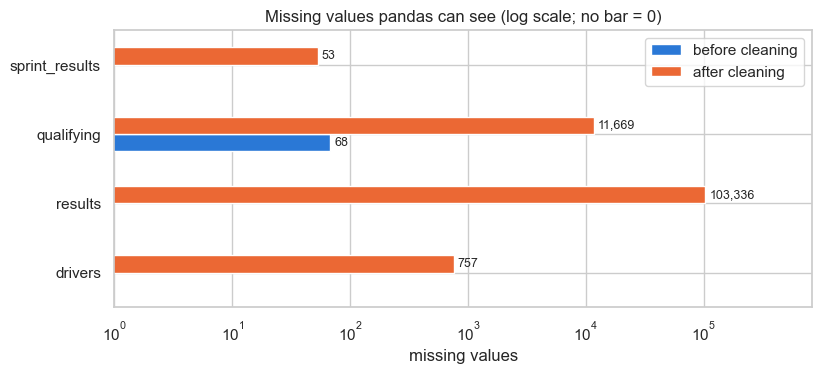

In [ ]:
# Missing values pandas can see, before vs. after cleaning (tables that have any)
missing_compare = pd.DataFrame({
    "before cleaning": {name: raw[name].isna().sum().sum() for name in raw},
    "after cleaning": {name: clean[name].isna().sum().sum() for name in raw},
})
missing_compare = missing_compare[missing_compare.sum(axis=1) > 0]

ax = missing_compare.plot.barh(figsize=(9, 3.6), logx=True)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=9)
ax.set_xlim(1, missing_compare.values.max() * 8)
ax.set_title("Missing values pandas can see (log scale; no bar = 0)")
ax.set_xlabel("missing values")
plt.show()

- **Rows:** `results` lost 91 rows (shared drives, 1.4) and `constructor_results` lost 7 rows with a wrong team
  id (1.2.8 e). Every other table keeps all its rows.
- **Columns:** 20 unused columns were dropped (1.2.2), mostly in `races` (18 → 6 columns: the session dates and times).
- **`\N` values:** 160,076 placeholders were replaced, 122,887 of them in `results`.
- **Types:** 18 columns now have their real type: numbers, dates (`races.date`, `drivers.dob`), or seconds
  (`q1`–`q3`, fastest lap, lap and pit-stop times).
- **The plot shows the main effect of cleaning:** before, pandas could see almost no missing values (only 68 empty
  fields in `qualifying`). After cleaning, the real missing values are visible, e.g. 103,336 in `results`.

#### 1.5.2 Real missing values after cleaning

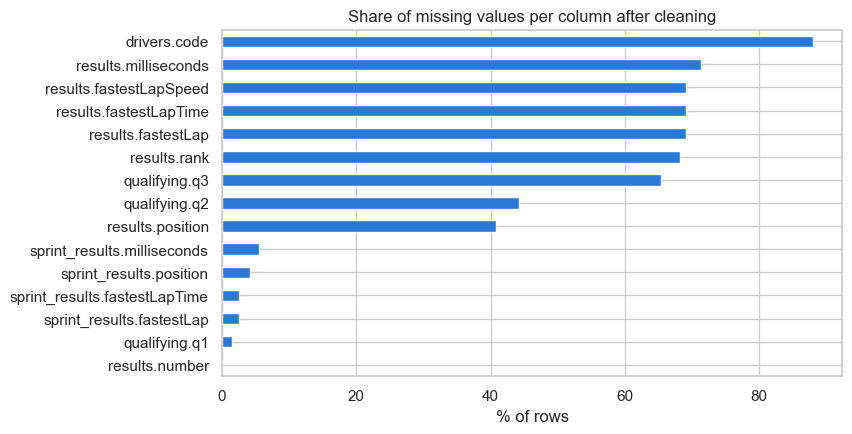

In [ ]:
missing_rows = []
for name in ["results", "qualifying", "sprint_results", "drivers"]:
    for col in clean[name].columns:
        pct = clean[name][col].isna().mean() * 100
        if pct > 0:
            missing_rows.append({"column": f"{name}.{col}", "% missing": pct})
missing_after = pd.DataFrame(missing_rows).sort_values("% missing")

missing_after.plot.barh(x="column", y="% missing", figsize=(8, 4.5), legend=False)
plt.title("Share of missing values per column after cleaning")
plt.xlabel("% of rows")
plt.ylabel("")
plt.show()

Missing values are not all the same. Most of them are **missing by design**: the value cannot exist for that row.

| Column(s) | % missing | Why | Type |
|---|---|---|---|
| `qualifying.q3`, `qualifying.q2` | 65%, 44% | Drivers knocked out in Q1/Q2 never set a Q2/Q3 time; before 2006 qualifying had a single session | By design |
| `results.position` | 41% | The driver was not classified (retired, disqualified); `positionOrder`, our target, is never missing | By design |
| `results.milliseconds` | 71% | A total race time is only recorded for drivers who finished on the lead lap | By design |
| `results.fastestLap`, `fastestLapTime`, `fastestLapSpeed`, `rank` | 68–69% | Not recorded before the mid-2000s | Not recorded |
| `drivers.code` | 88% | Three-letter codes exist only for modern drivers | Not recorded |
| `qualifying.q1`, sprint columns | 1–6% | No time set / did not finish the sprint | Small gaps |

**Consequences for section 3:** the "by design" gaps carry information and should become flags (e.g. "reached Q3")
instead of being filled with an average. Most of the gappy columns (`position`, `milliseconds`, fastest lap) are
post-race information anyway, so they will never be features. The two columns we rely on most, `positionOrder` and
`grid`, have no missing values.

#### 1.5.3 Distributions we could not plot before cleaning

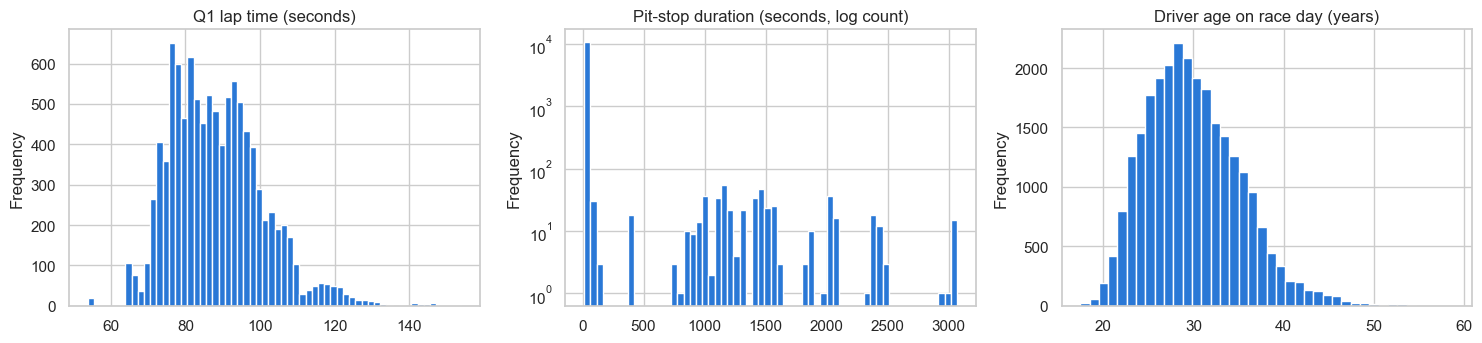

,count,mean,std,min,25%,50%,75%,max
Q1 time (s),10337.0,88.4,12.5,53.9,78.8,87.1,95.9,153.9
pit stop (s),11371.0,85.2,310.4,12.9,21.9,23.6,26.5,3069.0
driver age (years),26668.0,30.0,5.3,17.5,26.1,29.4,33.3,58.8


In [ ]:
race_ages = (clean["results"]
             .merge(clean["races"][["raceId", "date"]], on="raceId")
             .merge(clean["drivers"][["driverId", "dob"]], on="driverId"))
driver_age = (race_ages["date"] - race_ages["dob"]).dt.days / 365.25

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
clean["qualifying"]["q1"].plot.hist(bins=60, ax=axes[0], title="Q1 lap time (seconds)")
clean["pit_stops"]["duration"].plot.hist(bins=60, ax=axes[1], logy=True,
                                         title="Pit-stop duration (seconds, log count)")
driver_age.plot.hist(bins=40, ax=axes[2], title="Driver age on race day (years)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Q1 time (s)": clean["qualifying"]["q1"].describe(),
    "pit stop (s)": clean["pit_stops"]["duration"].describe(),
    "driver age (years)": driver_age.describe(),
}).T.round(1)

- **Q1 lap time:** most values lie between about 54 and 150 seconds (median 87.1 s). The spread mainly comes
  from circuits of different lengths, so a raw lap time is not comparable across races. **Section 3 should use the
  gap to the fastest driver in the same session** instead.
  - This plot first revealed one impossible value: `16:42.640` (1,002.6 s) in the 1995 Japanese GP, where the
    fastest Q1 time was 1:38.0 and the median 1:41.5. It was a recording error and is now set to missing in
    **1.2.6**, so the distribution above is clean.
- **Pit-stop duration:** the median stop is 23.6 s, but there are clusters between about 400 and 3,069 s. These
  are red-flag interruptions (cars waiting in the pit lane), not real stops. Any pit-stop statistic must use the
  median or exclude these values.
- **Driver age on race day:** from 17.5 to 58.8 years (median 29.4). This plot was only possible after parsing
  `dob` and `date` as real dates, and the plausible range confirms the date parsing worked.

#### 1.5.4 Effect of cleaning on the target

,rows,podium rows,podium rate
before cleaning,26759,3397,12.69%
after cleaning,26668,3395,12.73%


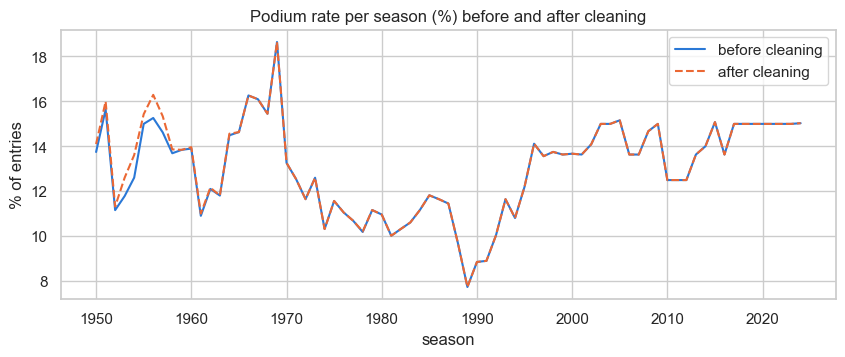

In [ ]:
podium_before = raw["results"]["positionOrder"] <= 3
podium_after = clean["results"]["positionOrder"] <= 3
target_effect = pd.DataFrame({
    "rows": [len(raw["results"]), len(clean["results"])],
    "podium rows": [podium_before.sum(), podium_after.sum()],
    "podium rate": [f"{podium_before.mean():.2%}", f"{podium_after.mean():.2%}"],
}, index=["before cleaning", "after cleaning"])
display(target_effect)

year_of = clean["races"].set_index("raceId")["year"]
rate_before = podium_before.groupby(raw["results"]["raceId"].map(year_of)).mean() * 100
rate_after = podium_after.groupby(clean["results"]["raceId"].map(year_of)).mean() * 100
pd.DataFrame({"before cleaning": rate_before, "after cleaning": rate_after}).plot(
    figsize=(10, 3.5), style=["-", "--"])
plt.title("Podium rate per season (%) before and after cleaning")
plt.xlabel("season")
plt.ylabel("% of entries")
plt.show()

- The cleaning removed 91 rows and 2 podium rows. The 2 podium rows were the same drivers counted twice (shared
  drives), so **no driver's podium was lost**.
- The podium rate barely moves: **12.69% → 12.73%**.
- The per-season plot shows the two lines are identical from 1979 onward. The only differences are in the
  1950s, where the duplicated shared-drive rows were removed. **The cleaning did not distort the target** in the
  seasons we will model.

#### 1.5.5 Summary

| What cleaning did | Effect on the data | What it means next |
|---|---|---|
| Replaced 160,076 `\N` placeholders | Real missing values are now visible (e.g. 103,336 in `results`) | Most gaps are "by design" → flags in section 3, not averages |
| Retyped 18 columns (numbers, dates, seconds) | Times and dates can be plotted and computed | Q1 times differ by circuit → use the gap to pole |
| Dropped 20 unused columns | Smaller, clearer tables | — |
| One row per driver per race (−91 rows) | Grain fixed, no podium lost | `clean["results"]` is ready for the modelling table (3.2) |
| Fixed 2 category spellings and 56 impossible or contradictory values (1.2.7–1.2.8) | One spelling per value; no impossible race times, fastest laps, or pit stops; one team id per driver per race | Joins and filters (e.g. by country in 2.2) are reliable |

**Found during this EDA:** one impossible Q1 time (1995), which is now **fixed in 1.2.6** (set to missing), and
red-flag pit stops (400–3,069 s), which are real records and are kept. They are inside the modelling window
(pit-stop data starts in 2011), so if pit-stop times are ever used as a feature they must be summarised with the
median.

## 2. Data-Engineering Questions

### 2.0 One joined table for all three questions

No single table can answer these questions: `results` has the grid and the finishing position, but the year,
the circuit's country, the driver's nationality, the qualifying position, and the retirement reason live in other
tables. We join them **once** into `entries` and reuse it in 2.1–2.3.

| Table | Joined on | What it adds |
|---|---|---|
| `results` (cleaned, one row per driver per race) | – | grid, finishing position (`positionOrder`), status id, team id |
| `races` | `raceId` | year, circuit id |
| `circuits` | `circuitId` | circuit name, country |
| `drivers` | `driverId` | nationality |
| `qualifying` | `raceId` + `driverId` | qualifying position (missing when no qualifying data exists) |
| `status` | `statusId` | retirement reason as text |
| `constructors` | `constructorId` | team name |

In [ ]:
entries = (clean["results"]
           .merge(clean["races"][["raceId", "year", "round", "circuitId"]], on="raceId")
           .merge(clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}),
                  on="circuitId")
           .merge(clean["drivers"][["driverId", "forename", "surname", "nationality"]], on="driverId")
           .merge(clean["qualifying"][["raceId", "driverId", "position"]]
                  .rename(columns={"position": "quali_position"}), on=["raceId", "driverId"], how="left")
           .merge(clean["status"], on="statusId")
           .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
                  on="constructorId"))
entries["podium"] = entries["positionOrder"] <= 3

# The joins must not add or lose rows: still exactly one row per driver per race
assert len(entries) == len(clean["results"])
assert not entries.duplicated(["raceId", "driverId"]).any()
print(f"entries: {len(entries):,} rows (one per driver per race), {entries.shape[1]} columns")
entries[["year", "circuit", "country", "surname", "nationality", "constructor",
         "grid", "quali_position", "positionOrder", "podium", "status"]].tail(3)

entries: 26,668 rows (one per driver per race), 29 columns


,year,circuit,country,surname,nationality,constructor,grid,quali_position,positionOrder,podium,status
26665,2024,Yas Marina Circuit,UAE,Bottas,Finnish,Sauber,9,9.0,18,False,Collision damage
26666,2024,Yas Marina Circuit,UAE,Colapinto,Argentine,Williams,20,19.0,19,False,Engine
26667,2024,Yas Marina Circuit,UAE,Pérez,Mexican,Red Bull,10,10.0,20,False,Collision


### 2.1 Front-Row Starts to Podiums by Circuit: Qualifying vs. Grid and the 2014 Hybrid Era

**Question.** Which circuits convert a front-row start into a podium most often, and does that ranking change
after the 2014 hybrid era?

**How we answer it.**
- **Front-row start**, measured two ways, because they are not the same thing:
  - by **grid**: the driver actually started from slot 1 or 2 (`grid` ∈ {1, 2});
  - by **qualifying**: the driver qualified 1st or 2nd (`quali_position` ∈ {1, 2}). Grid penalties can move a
    front-row qualifier further back, and others can move up into the front row.
- **Conversion rate** = podiums ÷ front-row starts, per circuit and per era.
- **Eras:** 2003–2013 (before the hybrid era) vs. 2014–2024 (hybrid era). Both have complete qualifying data
  (1.1.3), which the grid-vs-qualifying comparison needs, and both are about 11 seasons long.
- **Minimum sample:** a circuit is ranked in an era only if it has at least **10 front-row starts** there (about 5
  races). With fewer, a single race changes the rate by 10–50 points.

#### 2.1.1 Front-row starts: grid vs. qualifying

In [ ]:
fr = entries[entries["year"].between(2003, 2024)].copy()
fr["era"] = np.where(fr["year"] <= 2013, "2003–2013", "2014–2024")
fr["front_by_grid"] = fr["grid"].isin([1, 2])
fr["front_by_quali"] = fr["quali_position"].isin([1, 2])

print("Entries 2003–2024:", len(fr), "| missing qualifying position:", fr["quali_position"].isna().sum())
pd.crosstab(fr["front_by_quali"], fr["front_by_grid"],
            rownames=["qualified on front row"], colnames=["started on front row (grid)"])

Entries 2003–2024: 8970 | missing qualifying position: 24


started on front row (grid),False,True
qualified on front row,,
False,8078,36
True,38,818


In [ ]:
# Overall conversion rate by era and by definition
overall_rows = []
for definition, column in [("grid", "front_by_grid"), ("qualifying", "front_by_quali")]:
    for era, part in fr[fr[column]].groupby("era"):
        overall_rows.append({"front row by": definition, "era": era, "front-row starts": len(part),
                     "podiums": part["podium"].sum(), "conversion rate": round(part["podium"].mean(), 3)})
pd.DataFrame(overall_rows)

,front row by,era,front-row starts,podiums,conversion rate
0,grid,2003–2013,400,272,0.680
1,grid,2014–2024,454,345,0.760
2,qualifying,2003–2013,400,269,0.672
3,qualifying,2014–2024,456,336,0.737


#### 2.1.2 Conversion rate per circuit and era

In [ ]:
MIN_STARTS = 10


def conversion_by_circuit(front_rows):
    """Podiums / front-row starts per circuit and era, for circuits with enough starts."""
    table = (front_rows.groupby(["circuit", "era"])["podium"]
             .agg(starts="size", podiums="sum").reset_index())
    table["rate"] = table["podiums"] / table["starts"]
    return table[table["starts"] >= MIN_STARTS]


conv_grid = conversion_by_circuit(fr[fr["front_by_grid"]])
conv_quali = conversion_by_circuit(fr[fr["front_by_quali"]])

# Circuits ranked in both eras (grid definition), side by side
grid_wide = conv_grid.pivot(index="circuit", columns="era", values="rate").dropna()
grid_wide["change"] = grid_wide["2014–2024"] - grid_wide["2003–2013"]
grid_wide["rank 2003–2013"] = grid_wide["2003–2013"].rank(ascending=False, method="min").astype(int)
grid_wide["rank 2014–2024"] = grid_wide["2014–2024"].rank(ascending=False, method="min").astype(int)
print("Circuits with at least", MIN_STARTS, "front-row starts in both eras:", len(grid_wide))
grid_wide.sort_values("2014–2024", ascending=False).round(2)

Circuits with at least 10 front-row starts in both eras: 14


era,2003–2013,2014–2024,change,rank 2003–2013,rank 2014–2024
circuit,,,,,
Suzuka Circuit,0.72,0.89,0.17,4,1
Yas Marina Circuit,0.60,0.86,0.26,10,2
Circuit de Monaco,0.77,0.85,0.08,1,3
Circuit de Spa-Francorchamps,0.72,0.82,0.10,4,4
Circuit de Barcelona-Catalunya,0.68,0.82,0.14,6,4
Autódromo José Carlos Pace,0.59,0.79,0.20,12,6
Shanghai International Circuit,0.65,0.79,0.14,8,7
Circuit Gilles Villeneuve,0.60,0.78,0.18,10,8
Silverstone Circuit,0.73,0.75,0.02,3,9


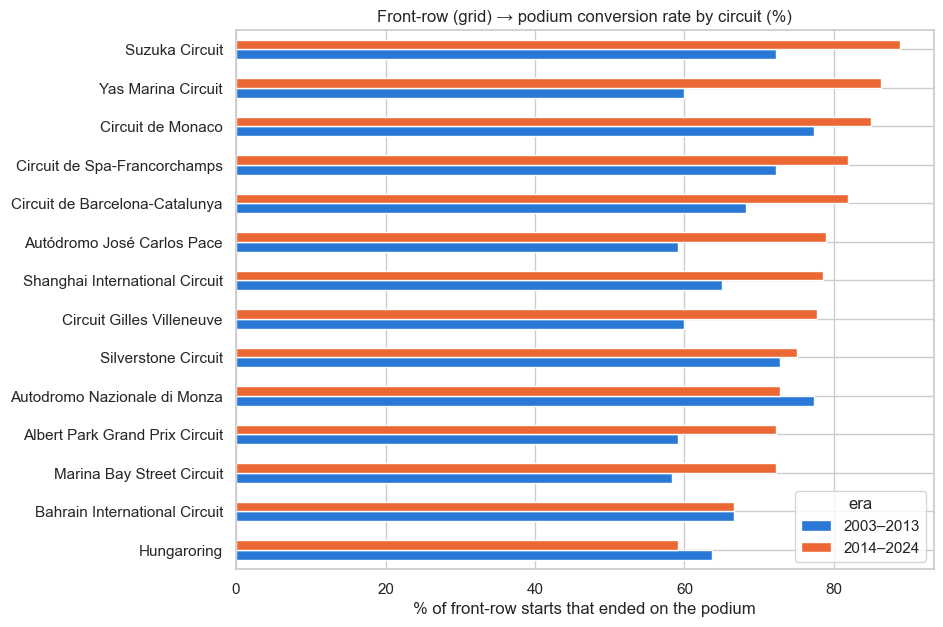

In [ ]:
ax = (grid_wide[["2003–2013", "2014–2024"]] * 100).sort_values("2014–2024").plot.barh(figsize=(9, 7))
ax.set_title("Front-row (grid) → podium conversion rate by circuit (%)")
ax.set_xlabel("% of front-row starts that ended on the podium")
ax.set_ylabel("")
plt.show()

#### 2.1.3 Did the ranking change after 2014? And does qualifying vs. grid matter?

We rank the 14 circuits by conversion rate in each era (1 = the circuit where a front-row start most often
becomes a podium) and look at how far each circuit moved between the two eras.

In [ ]:
moves = grid_wide[["rank 2003–2013", "rank 2014–2024", "2003–2013", "2014–2024"]].copy()
moves["places moved"] = moves["rank 2003–2013"] - moves["rank 2014–2024"]   # positive = moved up the ranking
moves = moves.sort_values("places moved", key=abs, ascending=False)
moves.rename(columns={"2003–2013": "rate 2003–2013", "2014–2024": "rate 2014–2024"}).round(2)

era,rank 2003–2013,rank 2014–2024,rate 2003–2013,rate 2014–2024,places moved
circuit,,,,,
Autodromo Nazionale di Monza,1,10,0.77,0.73,-9
Yas Marina Circuit,10,2,0.60,0.86,8
Bahrain International Circuit,7,13,0.67,0.67,-6
Autódromo José Carlos Pace,12,6,0.59,0.79,6
Silverstone Circuit,3,9,0.73,0.75,-6
Hungaroring,9,14,0.64,0.59,-5
Suzuka Circuit,4,1,0.72,0.89,3
Marina Bay Street Circuit,14,11,0.58,0.72,3
Circuit Gilles Villeneuve,10,8,0.60,0.78,2


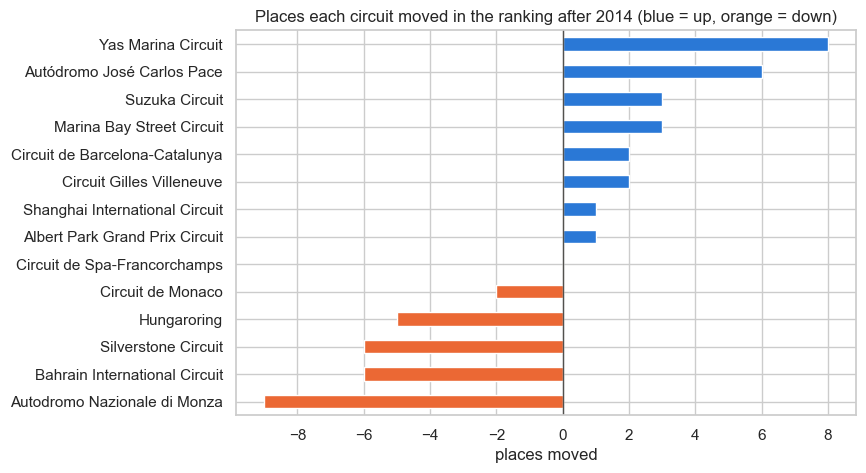

In [ ]:
moved = moves["places moved"].sort_values()
moved.plot.barh(figsize=(8, 5), color=["#2a78d6" if v > 0 else "#eb6834" for v in moved])
plt.axvline(0, color="#52514e", linewidth=1)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.title("Places each circuit moved in the ranking after 2014 (blue = up, orange = down)")
plt.xlabel("places moved")
plt.ylabel("")
plt.show()

- **Biggest movers:** Yas Marina rose 8 places (60% → 86%) and Interlagos 6 places (59% → 79%); Monza fell 9
  places (77% → 73%) and Hungaroring 5 places to last (64% → 59%).
- A circuit can drop even if its own rate stays the same: **Bahrain** converted 67% in both eras but fell 6 places,
  because most other circuits improved (11 of the 14 have a higher rate after 2014).

In [ ]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(grid_wide["2003–2013"], grid_wide["2014–2024"])
print(f"Spearman rho = {rho:.2f}, p-value = {p_value:.2f}")

Spearman rho = 0.30, p-value = 0.29


**How to read these two numbers.**
- **rho** compares the two rankings with one number: **1** means the circuits are in exactly the same order in both
  eras, **0** means the old rank tells us nothing about the new rank. Our **0.30** is close to 0, so the order was
  **shuffled a lot** after 2014, as the table and chart show.
- The **p-value** asks whether a number like this could come from luck alone. Each rate rests on only 10–24
  front-row starts, so one podium more or less moves a circuit several places. At **0.29** (above the usual 0.05
  limit), luck could explain it: the ranking clearly changed, but we cannot say exactly how much of the change is
  real and how much is random.

**Does it matter whether "front row" means grid or qualifying?** We compute each circuit's rate twice in the
same era, once per definition, and compare.

In [ ]:
both_definitions = conv_grid.merge(conv_quali, on=["circuit", "era"], suffixes=("_grid", "_quali"))
for era, part in both_definitions.groupby("era"):
    rho_def, _ = spearmanr(part["rate_grid"], part["rate_quali"])
    changed = (part["rate_grid"] != part["rate_quali"]).sum()
    print(f"{era}: the rate differs at {changed} of {len(part)} circuits; "
          f"rho between the two definitions = {rho_def:.2f}")

2003–2013: the rate differs at 6 of 21 circuits; rho between the two definitions = 0.94
2014–2024: the rate differs at 7 of 19 circuits; rho between the two definitions = 0.88


- At most circuits the two rates are identical. At 6–7 circuits they differ slightly, because a few drivers
  qualified on the front row but started further back (or the reverse).
- **rho** is close to **1** (0.94 and 0.88), so the circuits come out in almost the same order with either definition:
  the choice changes a few percentages, **not which circuits come out on top**. The top-5 lists below show this.

In [ ]:
# Top 5 circuits per era under each definition
top5 = {}
for name, table in [("grid", conv_grid), ("qualifying", conv_quali)]:
    for era, part in table.groupby("era"):
        best = part.sort_values(["rate", "starts"], ascending=False).head(5)
        top5[f"{era} ({name})"] = [f"{c} ({r:.0%})" for c, r in zip(best["circuit"], best["rate"])]
pd.DataFrame(top5, index=range(1, 6))

,2003–2013 (grid),2014–2024 (grid),2003–2013 (qualifying),2014–2024 (qualifying)
1,Circuit de Nevers Magny-Cours (92%),Suzuka Circuit (89%),Circuit de Nevers Magny-Cours (92%),Suzuka Circuit (89%)
2,Istanbul Park (79%),Yas Marina Circuit (86%),Istanbul Park (79%),Circuit de Monaco (85%)
3,Autodromo Nazionale di Monza (77%),Circuit de Monaco (85%),Silverstone Circuit (77%),Circuit de Barcelona-Catalunya (82%)
4,Circuit de Monaco (77%),Circuit de Barcelona-Catalunya (82%),Autodromo Nazionale di Monza (73%),Circuit de Spa-Francorchamps (82%)
5,Silverstone Circuit (73%),Circuit de Spa-Francorchamps (82%),Circuit de Spa-Francorchamps (72%),Yas Marina Circuit (82%)


#### 2.1.4 Answer

**Overall, a front-row start converts into a podium more often in the hybrid era:** 68% in 2003–2013 vs. 76% in
2014–2024 by grid (67% → 74% by qualifying).

**Which circuits convert best?**
- **2014–2024 (grid):** Suzuka 89% (16 of 18), Yas Marina 86% (19 of 22), Monaco 85% (17 of 20), then Spa and
  Barcelona 82% (18 of 22 each). Lowest: Hungaroring 59%.
- **2003–2013 (grid):** Magny-Cours 92% and Istanbul Park 79% lead, followed by Monaco and Monza (77%). Magny-Cours
  and Istanbul do not have enough front-row starts after 2014 to be ranked there.

**Did the ranking change after 2014? Yes, considerably.** For the 14 circuits ranked in both eras, the rank
correlation between the eras is only **0.30**. Examples: Yas Marina moved from 10th to 2nd (60% → 86%), Interlagos
from 12th to 6th, while Monza dropped from joint 1st to 10th and Hungaroring from 9th to last. 11 of the 14 circuits
convert better in the hybrid era, Bahrain is unchanged, and only Monza and Hungaroring convert worse.

**Does qualifying vs. grid matter?** 74 entries differ between the two definitions (36 started on the front row
without qualifying there, 38 qualified there but started further back, e.g. after a grid penalty). The rate changes
at 6 of 21 circuits (2003–2013) and 7 of 19 (2014–2024), but the **rankings stay almost the same** (rank correlation
0.94 and 0.88 between the definitions). The qualifying definition gives slightly lower rates in both eras, which is
consistent with front-row qualifiers who were moved back converting less often.

**Caution.** Each rate rests on 10–24 front-row starts, so one podium more or less moves it by 4–10 points.
Small gaps (e.g. Spa vs. Barcelona) are not meaningful, and the correlation of 0.30 is not statistically
distinguishable from zero (p = 0.29), so part of the reshuffling may be noise. These are descriptive patterns, not
causes: the higher hybrid-era rate fits a period dominated by a few teams, but this analysis does not prove why.

#### 2.1.5 Grain, missing data, and the pre-race cutoff

- **Grain:** `entries` has one row per driver per race (asserted in 2.0). A front-row start is one of those rows
  (two per race), and each rate aggregates those rows per circuit and era.
- **Missing data:** `grid` is never missing; `grid = 0` (pit-lane start or did not qualify) is never a front-row start.
  The qualifying position is missing for 24 of the 8,970 entries in 2003–2024; those rows only drop out of the
  qualifying definition. Before 2003 qualifying data is incomplete (1.1.3), which is why both eras start in 2003.
- **Pre-race cutoff:** the front row, by grid or by qualifying, is known before the race starts; the podium is the
  outcome. This is a historical, descriptive analysis, so using the outcome here is correct. For the model it tells
  us that grid and qualifying position are strong, legitimate pre-race features (about 70–76% of front-row starters
  reach the podium).

### 2.2 Home-Country Podium Advantage Controlling for Starting Position

**Question.** Do drivers podium more often at a circuit in their home country than elsewhere, after
controlling for starting position?

**Why "controlling for starting position" matters.** Starting position is the strongest predictor of a podium
(1.1.5). If home drivers simply started further forward, a raw home-vs-away comparison would show a "home advantage"
that is really a grid advantage. So we only compare drivers who started from **similar grid positions**.

**How we answer it.**
- **Home race:** the driver's nationality matches the **circuit's country** (not the race name, e.g. the "San Marino
  GP" at Imola is a home race for Italians).
- **Rows used:** drivers who actually started (`grid` > 0, not F/W), all seasons, with the 11 **Indianapolis 500**
  races (1950–1960) excluded: a different event whose entries were almost all American drivers who never raced
  another Grand Prix (1.1).
- **Control:** compare home vs. away within grid groups P1, P2–3, P4–6, P7–10, P11+, then summarise the effect with
  one logistic regression. The same regression on 2003–2024 checks whether the effect holds in the seasons we will
  model.

#### 2.2.1 Who races at home?

In [ ]:
# Driver nationality -> circuit country (dual nationalities count as home in both countries)
home_country = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"], "Australian": ["Australia"], "Austrian": ["Austria"],
    "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"],
    "Chinese": ["China"], "Dutch": ["Netherlands"], "French": ["France"], "German": ["Germany"],
    "Hungarian": ["Hungary"], "Indian": ["India"], "Italian": ["Italy"], "Japanese": ["Japan"],
    "Malaysian": ["Malaysia"], "Mexican": ["Mexico"], "Monegasque": ["Monaco"], "Portuguese": ["Portugal"],
    "Russian": ["Russia"], "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"],
    "Swiss": ["Switzerland"],
}
# Never a home race: no circuit in their country ("East German": every German circuit was in West Germany)
no_home_circuit = ["Chilean", "Colombian", "Czech", "Danish", "East German", "Finnish", "Indonesian", "Irish",
                   "Liechtensteiner", "New Zealander", "Polish", "Rhodesian", "Thai", "Uruguayan", "Venezuelan"]

# Every nationality is covered, and every mapped country really has a circuit
assert set(clean["drivers"]["nationality"]) == set(home_country) | set(no_home_circuit)
assert {c for countries in home_country.values() for c in countries} <= set(clean["circuits"]["country"])

indy_500 = clean["races"].loc[clean["races"]["name"] == "Indianapolis 500", "raceId"]
starters = entries[(entries["grid"] > 0) & ~entries["positionText"].isin(["F", "W"])
                   & ~entries["raceId"].isin(indy_500)].copy()
starters["home"] = [country in home_country.get(nationality, [])
                    for nationality, country in zip(starters["nationality"], starters["country"])]

print(f"Starts used: {len(starters):,} (excluded: {len(entries) - len(starters):,} non-starters, "
      f"pit-lane starts and Indianapolis 500 entries)")
print(f"Home starts: {starters['home'].sum():,} ({starters['home'].mean():.1%}) by "
      f"{starters.loc[starters['home'], 'driverId'].nunique()} drivers")
starters[starters["home"]]["nationality"].value_counts().head(8).rename("home starts").to_frame()

Starts used: 24,499 (excluded: 2,169 non-starters, pit-lane starts and Indianapolis 500 entries)
Home starts: 1,923 (7.8%) by 498 drivers


,home starts
nationality,
British,446
Italian,397
French,206
German,198
Brazilian,114
American,112
Spanish,60
Belgian,60


#### 2.2.2 The naive comparison (no control)

In [ ]:
naive = starters.groupby("home")["podium"].agg(starts="size", podium_rate="mean")
naive.index = naive.index.map({False: "away", True: "home"})
naive.round(3)

,starts,podium_rate
home,,
away,22576,0.139
home,1923,0.120


This raw comparison mixes two things: racing at home **and** where the driver started. The next step
removes the second one.

#### 2.2.3 Home vs. away within the same grid group

In [ ]:
starters["grid_group"] = pd.cut(starters["grid"], bins=[0, 1, 3, 6, 10, 99],
                                labels=["P1", "P2–3", "P4–6", "P7–10", "P11+"])
by_group = (starters.groupby(["grid_group", "home"], observed=True)["podium"]
            .agg(["size", "mean"]).unstack())
by_group.columns = ["away starts", "home starts", "away podium rate", "home podium rate"]
by_group["difference (home − away)"] = by_group["home podium rate"] - by_group["away podium rate"]
by_group.round(3)

,away starts,home starts,away podium rate,home podium rate,difference (home − away)
grid_group,,,,,
P1,1028,80,0.650,0.612,-0.037
P2–3,2067,148,0.511,0.554,0.043
P4–6,3102,224,0.262,0.272,0.011
P7–10,4101,336,0.094,0.074,-0.019
P11+,12278,1135,0.017,0.011,-0.005


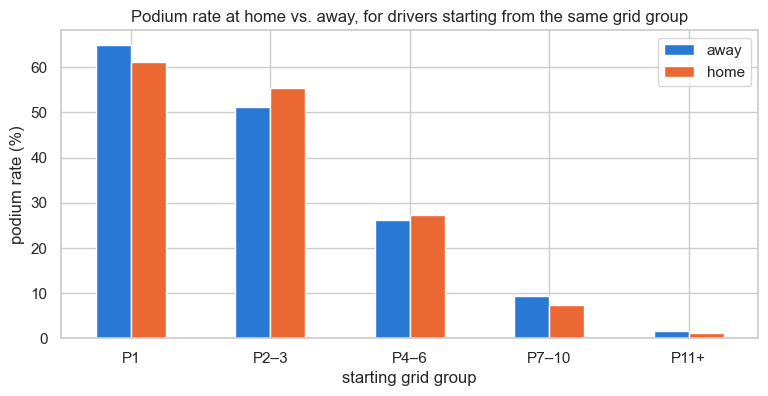

In [ ]:
ax = (by_group[["away podium rate", "home podium rate"]] * 100).plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Podium rate at home vs. away, for drivers starting from the same grid group")
ax.set_xlabel("starting grid group")
ax.set_ylabel("podium rate (%)")
ax.legend(["away", "home"])
plt.show()

#### 2.2.4 One number for the home effect

In [ ]:
import statsmodels.formula.api as smf


def home_effect(df):
    """Logistic regression podium ~ home + grid group: the odds ratio of 'home', with its 95% CI and p-value.
    Standard errors are grouped by race, because drivers in the same race compete for the same podium places."""
    data = df.assign(podium=df["podium"].astype(int), home=df["home"].astype(int))
    model = smf.logit("podium ~ home + C(grid_group)", data=data).fit(
        disp=False, cov_type="cluster", cov_kwds={"groups": data["raceId"]})
    low, high = np.exp(model.conf_int().loc["home"])
    return {"starts": len(df), "home starts": int(df["home"].sum()),
            "odds ratio": np.exp(model.params["home"]), "95% CI low": low, "95% CI high": high,
            "p-value": model.pvalues["home"]}


pd.DataFrame({
    "all seasons (main answer)": home_effect(starters),
    "2003–2024 (check)": home_effect(starters[starters["year"] >= 2003]),
}).T.round(3)

,starts,home starts,odds ratio,95% CI low,95% CI high,p-value
all seasons (main answer),24499.0,1923.0,0.954,0.808,1.126,0.577
2003–2024 (check),8837.0,363.0,0.778,0.523,1.158,0.217


**How to read these numbers.**
- The **odds ratio** compares the chance of a podium at home with the chance away, for drivers who started from the
  **same grid group**. **1** means no difference, above 1 means more podiums at home, below 1 means fewer.
- The **95% CI** is the range of values the data supports. Both ranges include **1**, so the data is consistent with
  "no home effect at all".
- The **p-value** (0.58 for all seasons) asks whether a difference this small could come from chance alone. It
  easily could; a real effect would need a p-value below 0.05.
- The uncertainty is **grouped by race**: drivers in the same race compete for the same three podium places, so their
  outcomes are not independent. Treating them as independent would make the result look more certain than it is.

#### 2.2.5 Answer

**No: after controlling for starting position, drivers do not finish on the podium more often at home.**

- **The naive comparison is misleading.** Without any control, home drivers look *worse* (12.0% podium rate at home
  vs. 13.9% away). That is because home starts come more often from the back of the grid: 59% of home starts were
  from P11 or lower, vs. 54% of away starts.
- **Within the same grid group, there is no consistent pattern.** Home drivers do slightly better from P2–3 (+4.3
  points) and P4–6 (+1.1), but slightly worse from P1 (−3.7), P7–10 (−1.9), and P11+ (−0.5). The differences are small
  and point in both directions.
- **One summary number:** the odds ratio for a home race is **0.95** (95% CI 0.81–1.13, p = 0.58), i.e. no
  measurable effect. The **2003–2024** check gives the same conclusion: 0.78 (95% CI 0.52–1.16, p = 0.22),
  with a wider range because it rests on only 363 home starts.

**What it means for the model:** a "home race" feature is unlikely to add much on top of grid position; the feature
ablation in section 5 can confirm this. **Not causal:** we controlled only for the starting position, not for the
team, era, or anything else that might differ between home and away drivers.

#### 2.2.6 Grain, missing data, and the pre-race cutoff

- **Grain:** `entries` has one row per driver per race. We keep only drivers who actually started, so each row is
  one start; the rates group these starts by home/away and grid group.
- **Missing data:** grid, nationality, and circuit country are never missing. Every nationality is either mapped to
  a country or listed as having no home circuit (checked with an `assert`). 2,169 rows are excluded on purpose:
  non-starters (F/W), `grid = 0` (pit-lane starts and non-qualifiers, which are not a grid position), and the
  Indianapolis 500.
- **Pre-race cutoff:** whether a race is at home (driver nationality, circuit country) and the grid position are
  both known before the race starts; the podium is the outcome. This is a historical, descriptive analysis.
- **Definition limits:** "home" uses nationality, so drivers living abroad still count as home in their country of
  nationality, and countries with several Grands Prix (e.g. Italy, the USA) give their drivers more home races.

### 2.3 Constructor Mechanical-Retirement Rates: 2014–2021 vs. 2022–2024

**Question.** Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Definition (from the task).** A mechanical retirement is a race start that ended early because a **component of the
car failed**. Crashes, the driver (e.g. illness), and regulation decisions (e.g. disqualification) do not count.

**How we answer it.**
- The reason a driver stopped is in `status`. We put each of the 66 status codes used in 2014–2024 into a category,
  and only the **mechanical** category counts.
- **Rate** = mechanical retirements ÷ race starts, per team and period. Drivers who never started (F/W, "Withdrew")
  are not starts; pit-lane starters (`grid = 0`) are.
- Teams use the dataset's names (e.g. "Alfa Romeo" and "Sauber" stay separate), as decided for team renames in 1.2.8.
- A team is ranked in a period only with at least **40 starts** (about one full season for a two-car team).

#### 2.3.1 Classifying every status code

In [ ]:
status_category = {
    "finished": ["Finished"],   # plus every "+n Lap(s)" code (finished, but lapped)
    "mechanical": ["Engine", "Power Unit", "Gearbox", "Brakes", "Suspension", "Hydraulics", "Electrical",
                   "Power loss", "Oil leak", "Overheating", "Water pressure", "Mechanical", "Turbo", "Battery",
                   "Fuel pressure", "Exhaust", "ERS", "Electronics", "Water leak", "Transmission", "Radiator",
                   "Oil pressure", "Throttle", "Technical", "Clutch", "Driveshaft", "Fuel leak", "Vibrations",
                   "Steering", "Fuel system", "Fuel pump", "Drivetrain", "Brake duct", "Cooling system",
                   "Differential", "Spark plugs", "Water pump",
                   "Front wing", "Rear wing", "Undertray", "Seat"],   # car parts (crash damage has its own code)
    "crash / contact": ["Collision", "Accident", "Collision damage", "Spun off", "Damage", "Debris"],
    "driver": ["Illness"],
    "regulation": ["Disqualified", "Excluded"],
    "did not start": ["Withdrew"],
    "pit stop / team error": ["Wheel", "Wheel nut", "Out of fuel"],   # loose wheel after a stop, fuel strategy
    "tyre": ["Puncture", "Tyre"],                                     # usually debris or contact
    "unknown cause": ["Retired"],                                     # no reason recorded
}


def categorise(status):
    if status.startswith("+") and "Lap" in status:
        return "finished"
    for category, codes in status_category.items():
        if status in codes:
            return category
    return None


mech = entries[entries["year"] >= 2014].copy()
mech["period"] = np.where(mech["year"] <= 2021, "2014–2021", "2022–2024")
mech["category"] = mech["status"].map(categorise)
assert mech["category"].notna().all()   # every status code used in 2014–2024 has a category

for category, codes in status_category.items():
    print(f"{category} ({len(codes)}): {', '.join(codes)}")
pd.crosstab(mech["category"], mech["period"], margins=True, margins_name="total")

finished (1): Finished
mechanical (41): Engine, Power Unit, Gearbox, Brakes, Suspension, Hydraulics, Electrical, Power loss, Oil leak, Overheating, Water pressure, Mechanical, Turbo, Battery, Fuel pressure, Exhaust, ERS, Electronics, Water leak, Transmission, Radiator, Oil pressure, Throttle, Technical, Clutch, Driveshaft, Fuel leak, Vibrations, Steering, Fuel system, Fuel pump, Drivetrain, Brake duct, Cooling system, Differential, Spark plugs, Water pump, Front wing, Rear wing, Undertray, Seat
crash / contact (6): Collision, Accident, Collision damage, Spun off, Damage, Debris
driver (1): Illness
regulation (2): Disqualified, Excluded
did not start (1): Withdrew
pit stop / team error (3): Wheel, Wheel nut, Out of fuel
tyre (2): Puncture, Tyre
unknown cause (1): Retired


period,2014–2021,2022–2024,total
category,,,
crash / contact,219,89,308
did not start,9,5,14
driver,2,1,3
finished,2660,1165,3825
mechanical,305,83,388
pit stop / team error,15,0,15
regulation,8,4,12
tyre,11,0,11
unknown cause,38,12,50


#### 2.3.2 Mechanical-retirement rate per team and period

In [ ]:
MIN_TEAM_STARTS = 40

starts = mech[~mech["positionText"].isin(["F", "W"]) & (mech["category"] != "did not start")]
rates = (starts.assign(mechanical=starts["category"] == "mechanical")
         .groupby(["constructor", "period"])
         .agg(starts=("mechanical", "size"), mechanical=("mechanical", "sum"))
         .reset_index())
rates["rate"] = rates["mechanical"] / rates["starts"]
rates = rates[rates["starts"] >= MIN_TEAM_STARTS]

print("Overall mechanical-retirement rate:",
      starts.groupby("period")["category"].apply(lambda c: f"{(c == 'mechanical').mean():.1%}").to_dict())
order = rates.pivot(index="constructor", columns="period", values="rate").sort_values(
    ["2022–2024", "2014–2021"], ascending=False).index
team_table = rates.assign(**{"rate": rates["rate"].map("{:.1%}".format),
                             "mechanical / starts": rates["mechanical"].astype(str) + " / " + rates["starts"].astype(str)})
team_table.pivot(index="constructor", columns="period", values=["rate", "mechanical / starts"]).loc[order].fillna("–")

Overall mechanical-retirement rate: {'2014–2021': '9.0%', '2022–2024': '5.9%'}


rate           mechanical / starts          
period         2014–2021 2022–2024           2014–2021 2022–2024
constructor                                                     
Alfa Romeo          3.3%     12.5%             4 / 120   11 / 88
Alpine F1 Team      9.1%     10.4%              4 / 44  14 / 135
AlphaTauri          9.1%      8.0%              7 / 77    7 / 88
Williams            7.2%      6.0%            23 / 319   8 / 134
Aston Martin        2.3%      5.3%              1 / 44   7 / 133
Ferrari             4.7%      5.2%            15 / 318   7 / 134
Haas F1 Team        7.5%      5.2%            18 / 240   7 / 135
Mercedes            3.8%      4.4%            12 / 320   6 / 136
RB F1 Team             –      4.2%                   –    2 / 48
McLaren            13.0%      3.7%            41 / 315   5 / 136
Red Bull           10.7%      3.7%            34 / 318   5 / 136
Sauber             10.6%      2.1%            21 / 199    1 / 48
Lotus F1           18.7%         –             14 / 75         –
Toro Rosso         16.1%         –            39 / 242         –
Renault            13.6%         –            27 / 199         –
Racing Point        8.0%         –              6 / 75         –
Force India         6.6%         –            13 / 198         –
Manor Marussia      5.2%         –              4 / 77         –

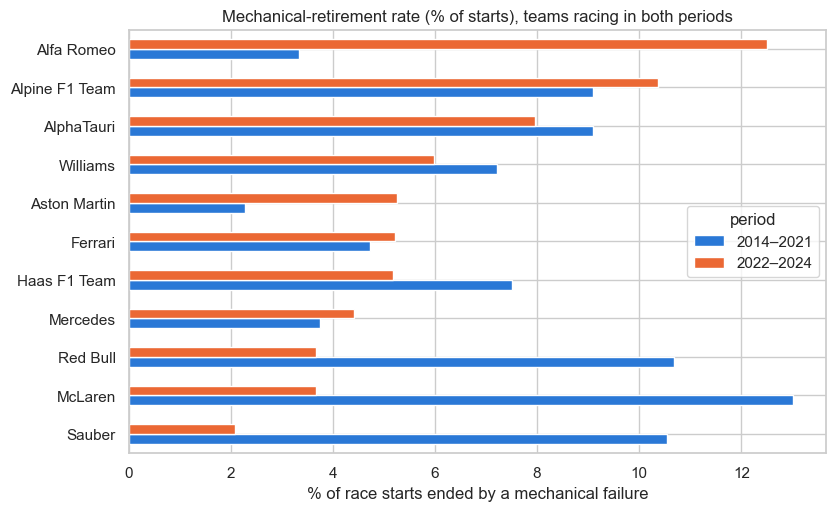

In [ ]:
team_wide = rates.pivot(index="constructor", columns="period", values="rate")
in_both = team_wide.dropna()
ax = (in_both * 100).sort_values("2022–2024").plot.barh(figsize=(9, 5.5))
ax.set_title("Mechanical-retirement rate (% of starts), teams racing in both periods")
ax.set_xlabel("% of race starts ended by a mechanical failure")
ax.set_ylabel("")
plt.show()

#### 2.3.3 Which teams are highest, and what changed?

In [ ]:
top_teams = {}
for period, part in rates.groupby("period"):
    best = part.sort_values("rate", ascending=False).head(5)
    top_teams[period] = [f"{team} ({rate:.1%}, {m} of {s})"
                         for team, rate, m, s in zip(best["constructor"], best["rate"], best["mechanical"], best["starts"])]
pd.DataFrame(top_teams, index=range(1, 6))

,2014–2021,2022–2024
1,"Lotus F1 (18.7%, 14 of 75)","Alfa Romeo (12.5%, 11 of 88)"
2,"Toro Rosso (16.1%, 39 of 242)","Alpine F1 Team (10.4%, 14 of 135)"
3,"Renault (13.6%, 27 of 199)","AlphaTauri (8.0%, 7 of 88)"
4,"McLaren (13.0%, 41 of 315)","Williams (6.0%, 8 of 134)"
5,"Red Bull (10.7%, 34 of 318)","Aston Martin (5.3%, 7 of 133)"


In [ ]:
change = in_both.assign(change=in_both["2022–2024"] - in_both["2014–2021"]).sort_values("change")
(change * 100).round(1).rename(columns=lambda c: f"{c} (%)" if c != "change" else "change (points)")

period,2014–2021 (%),2022–2024 (%),change (points)
constructor,,,
McLaren,13.0,3.7,-9.3
Sauber,10.6,2.1,-8.5
Red Bull,10.7,3.7,-7.0
Haas F1 Team,7.5,5.2,-2.3
Williams,7.2,6.0,-1.2
AlphaTauri,9.1,8.0,-1.1
Ferrari,4.7,5.2,0.5
Mercedes,3.8,4.4,0.7
Alpine F1 Team,9.1,10.4,1.3


#### 2.3.4 Robustness check: what if "Retired" (no cause recorded) were mechanical?

"Retired" has no reason attached, so we left it out of the mechanical count. If the conclusion depended on that
choice it would be fragile, so we recompute the ranking with "Retired" counted as mechanical (the upper bound).

In [ ]:
robust = (starts.assign(mechanical=starts["category"].isin(["mechanical", "unknown cause"]))
          .groupby(["constructor", "period"])
          .agg(starts=("mechanical", "size"), mechanical=("mechanical", "sum"))
          .reset_index())
robust = robust[robust["starts"] >= MIN_TEAM_STARTS]
robust["rate"] = robust["mechanical"] / robust["starts"]

comparison = {}
for name, table in [("main", rates), ("'Retired' counted", robust)]:
    for period, part in table.groupby("period"):
        best = part.sort_values("rate", ascending=False).head(3)
        comparison[f"{period} – {name}"] = [f"{t} ({r:.1%})" for t, r in zip(best["constructor"], best["rate"])]
pd.DataFrame(comparison, index=range(1, 4))

,2014–2021 – main,2022–2024 – main,2014–2021 – 'Retired' counted,2022–2024 – 'Retired' counted
1,Lotus F1 (18.7%),Alfa Romeo (12.5%),Lotus F1 (22.7%),Alfa Romeo (12.5%)
2,Toro Rosso (16.1%),Alpine F1 Team (10.4%),Toro Rosso (17.8%),RB F1 Team (10.4%)
3,Renault (13.6%),AlphaTauri (8.0%),McLaren (14.6%),Alpine F1 Team (10.4%)


Counting the 50 "Retired" codes as mechanical changes little. The **top team in each period stays the same**
(Lotus F1 before 2022, Alfa Romeo after), and Toro Rosso stays 2nd before 2022. Only places further down move:
McLaren replaces Renault in 3rd before 2022, and RB F1 Team (3 "Retired" in only 48 starts) rises to joint 2nd
after 2022. So the main conclusion does not depend on how we treat "Retired", but the exact order below the top is
sensitive for teams with few starts.

#### 2.3.5 Answer

**Overall, mechanical failures became rarer:** 9.0% of starts ended with a mechanical failure in 2014–2021,
vs. 5.9% in 2022–2024.

**Highest mechanical-retirement rates:**
- **2014–2021:** Lotus F1 18.7% (14 of 75 starts), Toro Rosso 16.1% (39 of 242), Renault 13.6% (27 of 199),
  McLaren 13.0% (41 of 315), Red Bull 10.7% (34 of 318).
- **2022–2024:** Alfa Romeo 12.5% (11 of 88), Alpine 10.4% (14 of 135), AlphaTauri 8.0% (7 of 88), Williams 6.0%,
  Aston Martin 5.3%.

**What changed for the 11 teams racing in both periods:** the biggest improvements are McLaren (13.0% → 3.7%),
Sauber (10.6% → 2.1%), and Red Bull (10.7% → 3.7%); the biggest increase is Alfa Romeo (3.3% → 12.5%), then
Aston Martin (+3.0 points). In 2022–2024 the front-running teams (Red Bull, McLaren, Mercedes, Ferrari) all stay at
or below 5.2%, so the most reliable cars belong to the strongest teams.

**Caution.**
- Counts are small after 2022 (e.g. Alfa Romeo 11 of 88): one or two failures move a rate by 1–2 points.
- Some names cover only part of a period: Lotus F1 raced 2014–2015, Alfa Romeo 2019–2023, Alpine and Aston Martin
  only 2021 in the first period, Sauber 2014–2018 and 2024.
- The same team can appear under several names (e.g. Sauber → Alfa Romeo → Sauber, Toro Rosso → AlphaTauri → RB),
  because we keep the dataset's team ids.
- These are descriptive patterns, not causes: the higher 2014–2021 rate fits the arrival of the new hybrid power
  units, but this analysis does not prove why.

#### 2.3.6 Grain, missing data, and the pre-race cutoff

- **Grain:** `entries` has one row per driver per race. We keep 2014–2024 race starts; each row is one car's start,
  so a two-car team has two rows per race. Each rate aggregates those starts per team and period.
- **Missing data:** `status` is never missing, and every status code used in 2014–2024 has a category (checked with
  an `assert`). The 50 "Retired" codes have no recorded cause, so they are kept out of the mechanical count and
  tested separately in 2.3.4. Drivers who never started (F/W, "Withdrew") are not starts. Teams with fewer than 40
  starts in a period (Caterham and Marussia in 2014–2021) are not ranked.
- **Pre-race cutoff:** `status` is only known **after** the race. That is fine for this descriptive question, but the
  current race's status must never be a model feature (leakage). What *is* allowed before the race is a team's
  mechanical-retirement rate in its **previous** races, a possible reliability feature for section 3.

## 3. Feature Selection & Engineering

**Order of this section.** We fix the prediction cutoff (3.1) and the modelling rows (3.2) first, then the
train/validation/test split (3.3), and only then build and choose features (3.4–3.6). The split comes before the
features on purpose: every data-driven choice below (window lengths, feature variants, which features to keep,
imputation values) is made on the **training seasons only**, so the test seasons never influence the feature set.

### 3.1 Pre-Race Prediction Cutoff and Leakage Audit

**The cutoff.** A prediction is made **after qualifying and before the race starts**. A field can be a feature only
if its value is known at that moment. Everything the race itself produces (finishing position, points, laps, status,
pit stops, lap times, the standings after the race) is **leakage**: it would not exist yet when the prediction is made.

We go through every table and decide when each field becomes known. Post-race fields can still be used, but only
from **previous** races (as form or standings features).

In [ ]:
leakage_audit = pd.DataFrame([
    ("races, circuits", "year, round, date, circuitId, circuit country", "before the weekend", "context (e.g. home race)"),
    ("drivers, constructors", "driverId, constructorId, dob, nationality", "before the weekend", "context (age, experience)"),
    ("qualifying", "position, q1, q2, q3", "after qualifying", "current race: allowed"),
    ("results", "grid", "before the start (official starting grid)", "current race: allowed"),
    ("sprint_results", "all columns", "Saturday, before the race", "allowed, but not used (only 2021+, no training data)"),
    ("results", "positionOrder, position, positionText", "after the race", "TARGET / leakage; past races only"),
    ("results", "points, laps, milliseconds, statusId", "after the race", "leakage; past races only"),
    ("results", "fastestLap, rank, fastestLapTime, fastestLapSpeed", "during the race", "leakage; not used"),
    ("lap_times, pit_stops", "all columns", "during the race", "leakage; not used"),
    ("driver_standings, constructor_standings", "row of the SAME raceId", "after the race (includes its result)", "leakage"),
    ("driver_standings, constructor_standings", "row of the PREVIOUS round", "before the race", "allowed (standings features)"),
    ("constructor_results", "points, status", "after the race", "leakage; not used"),
], columns=["table", "field(s)", "known", "use as a feature"])
leakage_audit

,table,field(s),known,use as a feature
0,"races, circuits","year, round, date, circuitId, circuit country",before the weekend,context (e.g. home race)
1,"drivers, constructors","driverId, constructorId, dob, nationality",before the weekend,"context (age, experience)"
2,qualifying,"position, q1, q2, q3",after qualifying,current race: allowed
3,results,grid,before the start (official starting grid),current race: allowed
4,sprint_results,all columns,"Saturday, before the race","allowed, but not used (only 2021+, no training..."
5,results,"positionOrder, position, positionText",after the race,TARGET / leakage; past races only
6,results,"points, laps, milliseconds, statusId",after the race,leakage; past races only
7,results,"fastestLap, rank, fastestLapTime, fastestLapSpeed",during the race,leakage; not used
8,"lap_times, pit_stops",all columns,during the race,leakage; not used
9,"driver_standings, constructor_standings",row of the SAME raceId,after the race (includes its result),leakage


Two fields need special care, because their table name hides when they become known:
- **`results.grid`** lives in the results table, but it is the official starting grid, fixed before the start.
  It is a legal pre-race feature.
- **`driver_standings` for the same `raceId`** looks like "the championship before this race", but 1.3.4 showed it
  is the table **after** the race, so it already contains the race's result. Only the **previous round's** row is
  allowed.

**An empirical check.** A leaky field gives itself away by predicting the podium "too well". Below we score single
fields by their ROC-AUC against the podium label (0.5 = no signal, 1.0 = perfect separation), on all 2003–2024
entries.

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score


def single_feature_scores(y, x):
    """ROC-AUC and PR-AUC of one feature used on its own as a score (direction chosen so that AUC >= 0.5)."""
    x = pd.Series(x, dtype=float)
    known = x.notna().values
    y_known, x_known = np.asarray(y)[known], x[known].values
    auc = roc_auc_score(y_known, x_known)
    sign = 1 if auc >= 0.5 else -1
    return {"ROC-AUC": max(auc, 1 - auc), "PR-AUC": average_precision_score(y_known, sign * x_known),
            "direction": "higher → podium" if sign > 0 else "lower → podium", "% missing": 100 * (~known).mean()}


# Every race with its season order and the raceId of the previous round of the same season
race_order = (clean["races"][["raceId", "year", "round", "date", "circuitId"]]
              .sort_values(["year", "round"]).reset_index(drop=True))
race_order["race_seq"] = np.arange(len(race_order))   # global race order, used for "previous races"
previous_round = (race_order[["raceId", "year", "round"]].assign(round=race_order["round"] + 1)
                  .rename(columns={"raceId": "prev_raceId"}))
race_order = race_order.merge(previous_round, on=["year", "round"], how="left")
assert race_order["prev_raceId"].isna().sum() == (race_order["round"] == 1).sum()   # only round 1 has no previous round

standing = clean["driver_standings"][["raceId", "driverId", "position"]]
leak_demo = (entries[entries["year"] >= 2003]
             .merge(race_order[["raceId", "prev_raceId"]], on="raceId")
             .merge(standing.rename(columns={"position": "standing_same_raceId"}), on=["raceId", "driverId"], how="left")
             .merge(standing.rename(columns={"raceId": "prev_raceId", "position": "standing_previous_round"}),
                    on=["prev_raceId", "driverId"], how="left"))

pd.DataFrame({
    "points (this race)": single_feature_scores(leak_demo["podium"], leak_demo["points"]),
    "laps (this race)": single_feature_scores(leak_demo["podium"], leak_demo["laps"]),
    "championship position, same raceId": single_feature_scores(leak_demo["podium"], leak_demo["standing_same_raceId"]),
    "championship position, previous round": single_feature_scores(leak_demo["podium"], leak_demo["standing_previous_round"]),
    "grid (pre-race)": single_feature_scores(leak_demo["podium"], leak_demo["grid"].replace(0, 99)),
}).T.round(3)

,ROC-AUC,PR-AUC,direction,% missing
points (this race),0.970816,0.872973,higher → podium,0.0
laps (this race),0.634149,0.205629,higher → podium,0.0
"championship position, same raceId",0.932385,0.650505,lower → podium,0.90301
"championship position, previous round",0.892029,0.542921,lower → podium,6.755853
grid (pre-race),0.90957,0.629952,lower → podium,0.0


- **`points` of the current race separates podium from non-podium almost perfectly** (ROC-AUC 0.97): a podium always
  scores points. It is the result itself, written differently. `laps` is weaker (0.63) but is just as illegal: it is
  only known once the race is over (a driver who retires early cannot finish on the podium).
- **The standings make the trap visible.** The championship position from the **same** `raceId` scores 0.93, the one
  from the **previous round** 0.89. The difference is this race's own points, already included in the same-raceId
  row: that difference is the leakage. We only use the previous round.
- `grid` is strong (0.91) **and** legal: it is known before the start.

**Rule for section 3.4:** current-race fields come only from `qualifying` and `results.grid`; every other result
field enters only through a `shift(1)` (strictly earlier races) or through the previous round's standings.

### 3.2 Unique Driver-Race Modeling Table and Podium Target

**Rows.** One row per driver per race, built from `clean["results"]` (already unique per (`raceId`, `driverId`), 1.4).

**Seasons: 2003–2024.** Qualifying is a core feature and is complete only from 2003 (1.1.3). Earlier seasons are
**not thrown away**: they are still used as *history* for the form features, so a driver's first 2003 race already
has a form value.

**Who is a row: only drivers who started.** Entries that never took the start (positionText **F**/**W**, status
"Withdrew", "Did not qualify", "Did not prequalify") are removed, as decided in 1.1.6: a car that does not start
cannot finish on the podium, so the question "will this driver podium?" does not apply to it. Pit-lane starters
(`grid = 0`) **did** start and are kept.

**Target.** `podium = positionOrder <= 3`, as the task defines it.

In [ ]:
DID_NOT_START = ["Withdrew", "Did not qualify", "Did not prequalify"]
FIRST_YEAR, LAST_YEAR = 2003, 2024

# All seasons: the history the form features are computed from
history = (clean["results"]
           .merge(race_order, on="raceId")
           .merge(clean["status"], on="statusId")
           .sort_values(["race_seq", "driverId"])
           .reset_index(drop=True))
history["podium"] = (history["positionOrder"] <= 3).astype(int)
history["started"] = ~history["positionText"].isin(["F", "W"]) & ~history["status"].isin(DID_NOT_START)

in_window = history["year"].between(FIRST_YEAR, LAST_YEAR)
model_rows = history.loc[in_window & history["started"], ["raceId", "driverId", "constructorId", "year", "round",
                                                          "race_seq", "podium"]].reset_index(drop=True)

assert not model_rows.duplicated(["raceId", "driverId"]).any()            # one row per driver per race
assert history.loc[in_window & ~history["started"], "podium"].sum() == 0  # no podium is removed with the non-starters
pd.Series({
    f"entries {FIRST_YEAR}–{LAST_YEAR}": in_window.sum(),
    "removed: did not start (F, W, withdrew, did not qualify)": (in_window & ~history["started"]).sum(),
    "modelling rows": len(model_rows),
    "races": model_rows["raceId"].nunique(),
    "podium rows": model_rows["podium"].sum(),
    "podium rate": f"{model_rows['podium'].mean():.1%}",
}, name="value").to_frame()

,value
entries 2003–2024,8970
"removed: did not start (F, W, withdrew, did not qualify)",64
modelling rows,8906
races,428
podium rows,1284
podium rate,14.4%


Podium drivers per race: {3: 428}


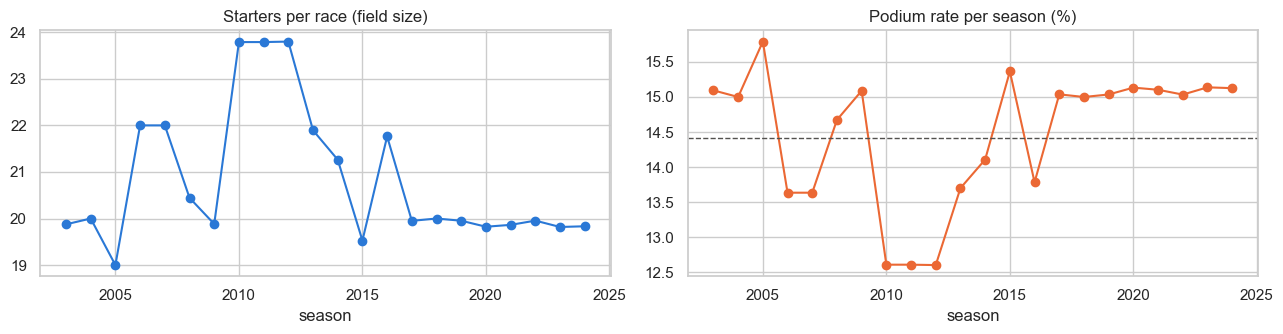

In [ ]:
per_race = model_rows.groupby("raceId")["podium"].sum()
print("Podium drivers per race:", per_race.value_counts().to_dict())

season = model_rows.groupby("year").agg(rows=("podium", "size"), races=("raceId", "nunique"), podium_rate=("podium", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
(season["rows"] / season["races"]).plot(ax=axes[0], marker="o", title="Starters per race (field size)")
(season["podium_rate"] * 100).plot(ax=axes[1], marker="o", color="#eb6834", title="Podium rate per season (%)")
axes[1].axhline(model_rows["podium"].mean() * 100, color="#52514e", linewidth=1, linestyle="--")
for ax in axes:
    ax.set_xlabel("season")
plt.tight_layout()
plt.show()

- **8,906 modelling rows** in 428 races; 64 non-starters were removed and none of them had a podium (checked with
  an `assert`).
- Every race has exactly **3** podium drivers, so the shared-car anomalies of the 1950s (1.4.4) do not reach the
  modelling table.
- The podium rate is **14.4%** overall. It moves between seasons only because the **field size** changes (about 19 to
  24 starters): with 3 podium places, a bigger field means a lower rate (12.6% in 2010–2012 with 24 cars, 15.1% with
  20 cars). The class imbalance (about 1 podium in 7 rows) is the reason PR-AUC and F1 are needed in section 4.

### 3.3 Training, Validation, and Test Split

**Choice: a split by season (time), not a random split.**

| Set | Seasons | Role |
|---|---|---|
| Training | 2003–2018 | fit the models; all feature and preprocessing choices in this section |
| Validation | 2019–2021 | choose hyperparameters and the decision threshold (section 4), compare feature sets |
| Test | 2022–2024 | touched once, for the final scores |

**Why by season:**
1. **It is how the model would be used.** The model predicts *upcoming* races from past ones. A temporal split
   evaluates exactly that: train on the past, predict the future. A random split would train on 2024 races and
   test on 2005 races, which says nothing about real use.
2. **A race must stay in one set.** The 3 podium places are shared by the drivers of a race, so the rows of one race
   are not independent. A random row split scatters each race across all sets (shown below); a season split never
   does.
3. **The test set is a real change of era.** 2022 introduced new car regulations (ground-effect cars), and 2022–2024
   is also the most recent data. Testing there is harder than testing on a random sample, but it is an honest
   estimate of performance on future seasons.

**Sizes.** 16 / 3 / 3 seasons give about 71% / 13% / 15% of the rows: enough training data for the models, and
1,200–1,350 rows (60–68 races, 180–204 podiums) in each of validation and test, so PR-AUC and F1 are not decided by a
handful of races.

In [ ]:
SPLITS = {"train": (2003, 2018), "validation": (2019, 2021), "test": (2022, 2024)}


def split_of(year):
    return next(name for name, (first, last) in SPLITS.items() if first <= year <= last)


model_rows["split"] = model_rows["year"].map(split_of)

split_summary = model_rows.groupby("split", sort=False).agg(
    seasons=("year", lambda y: f"{y.min()}–{y.max()}"), races=("raceId", "nunique"), rows=("podium", "size"),
    podiums=("podium", "sum"), podium_rate=("podium", "mean"))
split_summary["% of rows"] = (100 * split_summary["rows"] / len(model_rows)).round(1)
assert model_rows.groupby("raceId")["split"].nunique().max() == 1   # no race is in two sets
split_summary.round(3)

,seasons,races,rows,podiums,podium_rate,% of rows
split,,,,,,
train,2003–2018,300,6362,900,0.141,71.4
validation,2019–2021,60,1193,180,0.151,13.4
test,2022–2024,68,1351,204,0.151,15.2


C:\Users\Dell\AppData\Local\Temp\ipykernel_3764\2712561660.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  shared = model_rows[model_rows["raceId"].isin(races_in_test)].groupby("raceId").apply(


Random split: 100% of the test races also have drivers in the training set
Random split: 69% of the 2022–2024 rows would be used for training


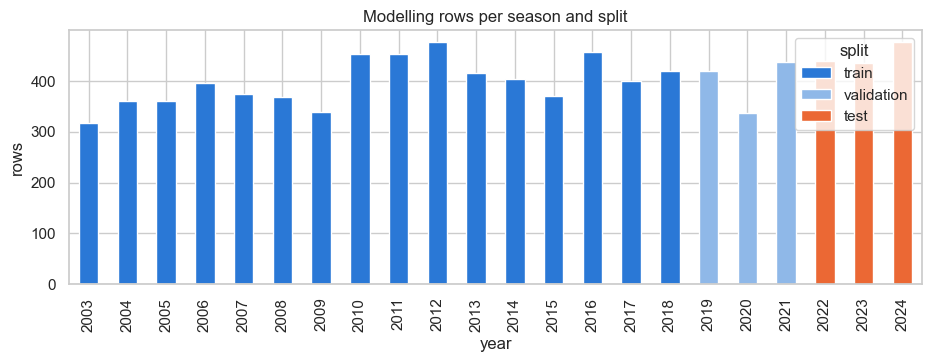

In [ ]:
# What a random 70/15/15 row split would have done instead
rng = np.random.default_rng(0)
random_split = pd.Series(rng.choice(["train", "validation", "test"], size=len(model_rows), p=[0.7, 0.15, 0.15]))
races_in_test = model_rows.loc[random_split.eq("test").values, "raceId"].unique()
shared = model_rows[model_rows["raceId"].isin(races_in_test)].groupby("raceId").apply(
    lambda race: random_split[race.index].eq("train").any())
print(f"Random split: {shared.mean():.0%} of the test races also have drivers in the training set")
print(f"Random split: {random_split[model_rows['year'].ge(2022).values].eq('train').mean():.0%} "
      f"of the 2022–2024 rows would be used for training")

ax = model_rows.groupby(["year", "split"]).size().unstack()[list(SPLITS)].plot.bar(
    stacked=True, figsize=(11, 3.3), color=["#2a78d6", "#8fb8e8", "#eb6834"], rot=90)
ax.set_title("Modelling rows per season and split")
ax.set_ylabel("rows")
plt.show()

- The season split keeps every race inside one set (checked with an `assert`). A random split would put drivers from
  **every** test race into training, and would train on 69% of the 2022–2024 rows, i.e. on the very seasons it
  claims to predict.
- The podium rate is similar in the three sets (14.1% / 15.1% / 15.1%; training is slightly lower because it
  contains the 24-car seasons 2010–2012), so the class balance is about the same in all three.
- **Not used:** a separate cross-validation over seasons. With a fixed validation block we can tune and compare
  models with one simple, reproducible procedure; the price is that validation covers only 3 seasons.

### 3.4 Leakage-Safe Historical Form, Standings, Grid, and Qualifying Features

We build **candidate** features in five families, motivated by the EDA so far, and choose among them in 3.5. Every
feature is computed from information known at the cutoff:

| Family | Candidate | Definition | Known before the start because… | Motivation |
|---|---|---|---|---|
| Qualifying | `quali_position` | qualifying position | qualifying is over | 1.1.5: podium rate falls steeply with starting position |
| | `quali_gap_pct` | gap of the driver's best qualifying lap to pole, in % | qualifying is over | 1.5.3: raw lap times are not comparable across circuits, gaps are |
| Grid | `grid_position` | starting slot; pit-lane start = behind the last slot | official grid | 1.1.5, 2.1 |
| | `grid_penalty` | `grid_position − quali_position` (places lost (+) or gained (−) after qualifying) | both known | 1.1.6: grid ≠ qualifying for 23%; 2.1: penalised front-row qualifiers convert less |
| | `pit_lane_start` | 1 if `grid = 0` | official grid | 1.1.6: nobody reached the podium from `grid = 0` |
| Standings | `driver_champ_pos`, `driver_points_share` | championship position / points ÷ leader's points, **after the previous round** | previous round | 1.3.4: same-raceId standings leak |
| | `team_champ_pos`, `team_points_share` | the same for the constructor | previous round | car strength |
| Form | `driver_podium_rate`, `driver_avg_finish` | podium rate / mean finishing position over the driver's previous *N* races | strictly earlier races | recent performance |
| | `team_podium_rate` | podium rate of the team's cars over its previous *N* races | strictly earlier races | car performance |
| Reliability | `team_finish_rate`, `team_mech_dnf_rate` | share of the team's cars that finished / retired with a mechanical failure, previous *N* races | strictly earlier races | 2.3: reliability differs strongly between teams |
| Context | `career_starts` | number of previous F1 entries | strictly earlier races | experience |
| | `driver_age` | age on race day | date of birth | experience |
| | `home_race` | driver nationality = circuit country | known | 2.2 found no effect; tested again here |

**Why points *share* and not raw points:** the points system changed in 2003, 2010, and with sprints in 2021 (a win
was worth 10 points, then 25), so raw points are not comparable across seasons; the share of the leader's points is.

#### 3.4.1 Building blocks: past-only means and the previous round

In [ ]:
def past_mean(df, key, column, window):
    """Mean of `column` over the previous `window` rows of the same `key` (df sorted by race order).
    shift(1) drops the current row, so the current race never enters its own feature."""
    return df.groupby(key)[column].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())


# Mechanical failures: the 2.3 categories cover the 2014–2024 codes; these older codes also name a failed car part
OLDER_MECHANICAL_CODES = ["Halfshaft", "Alternator", "Wheel bearing", "Pneumatics", "Ignition", "Chassis", "Track rod",
                          "Heat shield fire", "Engine fire", "Oil line", "Launch control", "Crankshaft", "Oil pump",
                          "Injection", "Distributor", "Engine misfire", "Wheel rim", "Fuel rig"]
MECHANICAL = set(status_category["mechanical"]) | set(OLDER_MECHANICAL_CODES)

history["finished"] = (history["status"].eq("Finished") | history["status"].str.match(r"^\+\d+ Laps?$")).astype(int)
history["mech_dnf"] = history["status"].isin(MECHANICAL).astype(int)

unmapped = history.loc[history["year"].between(2002, 2013) & (history["finished"] == 0) & (history["mech_dnf"] == 0)
                       & ~history["status"].isin(sum(status_category.values(), [])) & history["started"], "status"]
print("Retirement codes 2002–2013 not counted as mechanical:", unmapped.value_counts().to_dict())

Retirement codes 2002–2013 not counted as mechanical: {'Broken wing': 2, 'Fuel': 2, 'Not classified': 1, 'Handling': 1, 'Fire': 1, 'Tyre puncture': 1, 'Refuelling': 1, 'Driver Seat': 1}


- `past_mean` is the only way current-race results enter a feature: `shift(1)` removes the current race before the
  rolling mean. A driver's first race ever has no history and gets a missing value (handled in 3.6).
- The window counts **races**, not seasons, and runs across season boundaries, so the first race of a season still
  has form from the end of the previous season (where the standings are still empty).
- Only 10 retirements in 2002–2013 remain uncounted. Their cause is unclear ("Broken wing" and "Tyre puncture" are
  usually contact damage, "Fuel" and "Refuelling" can be a strategy or pit error) or not a car failure ("Not
  classified"), so, as in 2.3, they are not counted as mechanical. 10 rows in 12 seasons cannot move the feature.

#### 3.4.2 Choosing the form window *N* (trial on training seasons)

A short window reacts quickly to change (a new car, a driver switching teams) but is noisy; a long one is stable but
slow. We tried *N* ∈ {1, 3, 5, 10, 20} and scored each form feature on its own on the **training seasons only**.

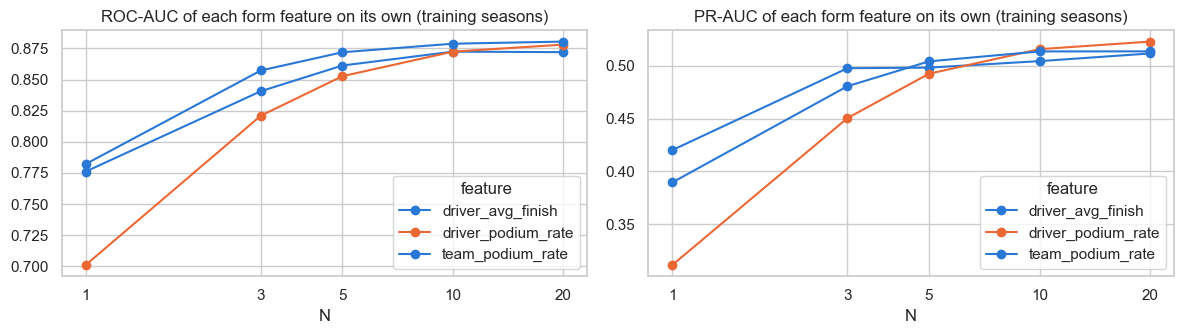

feature,driver_avg_finish,driver_podium_rate,team_podium_rate
N,,,
1,0.776,0.701,0.782
3,0.841,0.821,0.857
5,0.861,0.853,0.872
10,0.872,0.872,0.879
20,0.872,0.878,0.881


In [ ]:
train_keys = model_rows.loc[model_rows["split"] == "train", ["raceId", "driverId"]]
team_races = (history.groupby(["constructorId", "race_seq"])["podium"].mean()
              .rename("team_podium").reset_index().sort_values("race_seq"))

window_trial = []
for window in [1, 3, 5, 10, 20]:
    trial = history[["raceId", "driverId", "constructorId", "race_seq", "podium"]].copy()
    trial["driver_podium_rate"] = past_mean(history, "driverId", "podium", window)
    trial["driver_avg_finish"] = past_mean(history, "driverId", "positionOrder", window)
    team_trial = team_races.assign(team_podium_rate=past_mean(team_races, "constructorId", "team_podium", window))
    trial = trial.merge(team_trial[["constructorId", "race_seq", "team_podium_rate"]], on=["constructorId", "race_seq"])
    trial = trial.merge(train_keys, on=["raceId", "driverId"])
    for feature in ["driver_podium_rate", "driver_avg_finish", "team_podium_rate"]:
        window_trial.append({"N": window, "feature": feature,
                             **single_feature_scores(trial["podium"], trial[feature])})
window_trial = pd.DataFrame(window_trial)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for metric, ax in zip(["ROC-AUC", "PR-AUC"], axes):
    window_trial.pivot(index="N", columns="feature", values=metric).plot(ax=ax, marker="o", logx=True)
    ax.set_xticks([1, 3, 5, 10, 20], labels=["1", "3", "5", "10", "20"])
    ax.set_title(f"{metric} of each form feature on its own (training seasons)")
plt.tight_layout()
plt.show()
window_trial.pivot(index="N", columns="feature", values="ROC-AUC").round(3)

**Decision: N = 10 races.**
- The score rises steeply from 1 to 5 races and then flattens: from 10 to 20 races ROC-AUC gains less than 0.01
  for every form feature.
- So 10 races (about half a season) captures almost all of the signal, while reacting twice as fast as 20 races to a
  real change, for example a driver moving to a better team or a team bringing a new car. The extra few thousandths
  of AUC from N = 20 are not worth a window that is still half full of the previous car's results.

#### 3.4.3 Choosing the qualifying-gap definition (trial on training seasons)

Qualifying formats changed: 2003–2005 had a single timed lap (only `q1` is filled), since 2006 there are three
knock-out sessions (Q1, Q2, Q3). We compared two ways to turn the times into one comparable number:
- **Q1 gap:** gap to the fastest Q1 time. Everybody drives Q1, so all drivers are compared on the same session.
- **Best-lap gap:** gap of the driver's best lap in any session to the best lap of the session (the pole time).

In [ ]:
quali = clean["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].copy()
quali["best_lap"] = quali[["q1", "q2", "q3"]].min(axis=1)
quali["q1_gap_pct"] = 100 * (quali["q1"] / quali.groupby("raceId")["q1"].transform("min") - 1)
quali["best_gap_pct"] = 100 * (quali["best_lap"] / quali.groupby("raceId")["best_lap"].transform("min") - 1)

quali_train = train_keys.merge(model_rows[["raceId", "driverId", "podium"]]).merge(quali, how="left")
pd.DataFrame({"Q1 gap": single_feature_scores(quali_train["podium"], quali_train["q1_gap_pct"]),
              "best-lap gap": single_feature_scores(quali_train["podium"], quali_train["best_gap_pct"])}).T.round(3)

,ROC-AUC,PR-AUC,direction,% missing
Q1 gap,0.82916,0.454367,lower → podium,1.744734
best-lap gap,0.892569,0.594918,lower → podium,1.744734


**Decision: the best-lap gap.** It separates podium finishers clearly better (ROC-AUC 0.89 vs. 0.83, PR-AUC 0.59 vs.
0.45). In the knock-out format the top drivers often do just enough in Q1 to progress, so the Q1 gap understates how
fast they are; their best lap (usually in Q3) shows their real pace. Both definitions are identical for 2003–2005,
where only one lap exists.

#### 3.4.4 The feature builder

All candidates come from one function. It takes the four tables whose rows describe a race's outcome or the session before it.

In [ ]:
FORM_WINDOW = 10   # 3.4.2


def build_features(results, driver_standings, constructor_standings, qualifying, window=FORM_WINDOW):
    """One row per driver-race (all seasons) with every candidate feature, using only pre-race information."""
    h = (results.merge(race_order, on="raceId").merge(clean["status"], on="statusId")
         .sort_values(["race_seq", "driverId"]).reset_index(drop=True))
    h["podium"] = (h["positionOrder"] <= 3).astype(int)
    h["finished"] = (h["status"].eq("Finished") | h["status"].str.match(r"^\+\d+ Laps?$")).astype(int)
    h["mech_dnf"] = h["status"].isin(MECHANICAL).astype(int)
    f = h[["raceId", "driverId", "constructorId", "circuitId", "date", "round", "prev_raceId", "race_seq"]].copy()

    # Qualifying and grid (the current race; both known before the start)
    q = qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}).copy()
    best_lap = qualifying[["q1", "q2", "q3"]].min(axis=1)
    q["quali_gap_pct"] = 100 * (best_lap / best_lap.groupby(qualifying["raceId"]).transform("min") - 1)
    f = f.merge(q, on=["raceId", "driverId"], how="left")
    last_slot = h["grid"].groupby(h["raceId"]).transform("max")
    f["grid_position"] = np.where(h["grid"] > 0, h["grid"], last_slot + 1)   # pit lane = behind the last slot
    f["pit_lane_start"] = (h["grid"] == 0).astype(int)
    f["grid_penalty"] = f["grid_position"] - f["quali_position"]

    # Championship standings after the PREVIOUS round (round 1 has none -> missing)
    ds = driver_standings[["raceId", "driverId", "points", "position"]].copy()
    ds["driver_points_share"] = ds["points"] / ds.groupby("raceId")["points"].transform("max")
    ds["drivers_listed"] = ds.groupby("raceId")["driverId"].transform("size")
    f = f.merge(ds.rename(columns={"raceId": "prev_raceId", "position": "driver_champ_pos"})
                [["prev_raceId", "driverId", "driver_champ_pos", "driver_points_share", "drivers_listed"]],
                on=["prev_raceId", "driverId"], how="left")
    cs = constructor_standings[["raceId", "constructorId", "points", "position"]].copy()
    cs["team_points_share"] = cs["points"] / cs.groupby("raceId")["points"].transform("max")
    cs["teams_listed"] = cs.groupby("raceId")["constructorId"].transform("size")
    f = f.merge(cs.rename(columns={"raceId": "prev_raceId", "position": "team_champ_pos"})
                [["prev_raceId", "constructorId", "team_champ_pos", "team_points_share", "teams_listed"]],
                on=["prev_raceId", "constructorId"], how="left")
    # Not yet in the standings after round 1 = no points yet: behind everyone listed, share 0
    f["drivers_listed"] = f.groupby("raceId")["drivers_listed"].transform("max")
    f["teams_listed"] = f.groupby("raceId")["teams_listed"].transform("max")
    new_driver = f["round"].gt(1) & f["driver_champ_pos"].isna()
    f.loc[new_driver, "driver_champ_pos"] = f.loc[new_driver, "drivers_listed"] + 1
    f.loc[new_driver, "driver_points_share"] = 0.0
    new_team = f["round"].gt(1) & f["team_champ_pos"].isna()
    f.loc[new_team, "team_champ_pos"] = f.loc[new_team, "teams_listed"] + 1
    f.loc[new_team, "team_points_share"] = 0.0

    # Form and reliability: previous `window` races only
    f["driver_podium_rate"] = past_mean(h, "driverId", "podium", window)
    f["driver_avg_finish"] = past_mean(h, "driverId", "positionOrder", window)
    team = (h.groupby(["constructorId", "race_seq"])[["podium", "finished", "mech_dnf"]].mean()
            .reset_index().sort_values("race_seq"))
    team["team_podium_rate"] = past_mean(team, "constructorId", "podium", window)
    team["team_finish_rate"] = past_mean(team, "constructorId", "finished", window)
    team["team_mech_dnf_rate"] = past_mean(team, "constructorId", "mech_dnf", window)
    f = f.merge(team[["constructorId", "race_seq", "team_podium_rate", "team_finish_rate", "team_mech_dnf_rate"]],
                on=["constructorId", "race_seq"], how="left")

    # Context
    f["career_starts"] = h.groupby("driverId").cumcount()   # entries before this one
    drivers = clean["drivers"].set_index("driverId")
    f["driver_age"] = (f["date"] - f["driverId"].map(drivers["dob"])).dt.days / 365.25
    country = f["circuitId"].map(clean["circuits"].set_index("circuitId")["country"])
    nationality = f["driverId"].map(drivers["nationality"])
    f["home_race"] = [int(c in home_country.get(n, [])) for n, c in zip(nationality, country)]   # mapping from 2.2

    return f.drop(columns=["circuitId", "date", "round", "prev_raceId", "race_seq", "constructorId",
                           "drivers_listed", "teams_listed"])


FEATURE_FAMILIES = {
    "qualifying": ["quali_position", "quali_gap_pct"],
    "grid": ["grid_position", "grid_penalty", "pit_lane_start"],
    "standings": ["driver_champ_pos", "driver_points_share", "team_champ_pos", "team_points_share"],
    "form": ["driver_podium_rate", "driver_avg_finish", "team_podium_rate"],
    "reliability": ["team_finish_rate", "team_mech_dnf_rate"],
    "context": ["career_starts", "driver_age", "home_race"],
}
CANDIDATES = sum(FEATURE_FAMILIES.values(), [])

features = build_features(clean["results"], clean["driver_standings"], clean["constructor_standings"],
                          clean["qualifying"])
assert len(features) == len(clean["results"]) and not features.duplicated(["raceId", "driverId"]).any()
print(f"{len(CANDIDATES)} candidate features for {len(features):,} driver-races (all seasons)")

17 candidate features for 26,668 driver-races (all seasons)


#### 3.4.5 The modelling table

In [ ]:
modeling_table = model_rows.merge(features, on=["raceId", "driverId"], how="left")
assert len(modeling_table) == len(model_rows) and not modeling_table.duplicated(["raceId", "driverId"]).any()

print(f"modeling_table: {len(modeling_table):,} rows × {len(CANDIDATES)} candidate features")
modeling_table[["year", "round", "driverId", "split", "podium"] + CANDIDATES].tail(3)

modeling_table: 8,906 rows × 17 candidate features


,year,round,driverId,split,podium,quali_position,quali_gap_pct,grid_position,grid_penalty,pit_lane_start,driver_champ_pos,driver_points_share,team_champ_pos,team_points_share,driver_podium_rate,driver_avg_finish,team_podium_rate,team_finish_rate,team_mech_dnf_rate,career_starts,driver_age,home_race
8903,2024,24,859,test,0,12.0,1.061808,12,0.0,0,21.0,0.009324,8.0,0.071875,0.0,12.500,0.0,0.85,0.05,10,22.822724,0
8904,2024,24,861,test,0,19.0,1.594528,20,1.0,0,19.0,0.011655,9.0,0.026562,0.0,12.875,0.0,0.70,0.10,8,21.535934,0
8905,2024,24,862,test,0,20.0,1.828198,17,-3.0,0,24.0,0.000000,6.0,0.092188,NaN,NaN,0.1,0.90,0.05,0,21.883641,0


In [ ]:
# Missing values per candidate and split
(modeling_table.groupby("split", sort=False)[CANDIDATES].apply(lambda d: d.isna().mean() * 100)
 .T.round(1).loc[lambda t: t.sum(axis=1) > 0])

split,train,validation,test
quali_position,0.3,0.3,0.0
quali_gap_pct,1.7,1.7,1.0
grid_penalty,0.3,0.3,0.0
driver_champ_pos,5.2,5.0,4.4
driver_points_share,5.2,5.0,4.4
team_champ_pos,5.2,5.0,4.4
team_points_share,5.2,5.0,4.4
driver_podium_rate,1.1,0.8,0.6
driver_avg_finish,1.1,0.8,0.6
team_podium_rate,0.5,0.5,0.1


Every missing value has a known reason; none of them is a data error:

| Feature(s) | Missing because | Share |
|---|---|---|
| standings (4) | **round 1**: no previous round in the season, no standings yet | 4.4–5.2% |
| `driver_podium_rate`, `driver_avg_finish` | the driver's **first F1 race**: no history | 0.6–1.1% |
| team form / reliability (3) | the team's **first race** under this constructor id (new team or rename, e.g. Toro Rosso → AlphaTauri) | 0.1–0.5% |
| `quali_position`, `grid_penalty` | no qualifying row (24 entries, 2.1.5) | 0–0.3% |
| `quali_gap_pct` | no qualifying time set (or no qualifying row) | 1.0–1.7% |

Each family is missing **on the same rows**: the four standings features are all missing on exactly the round-1
rows, the two driver-form features on exactly the debut rows, and so on. There are only **5 distinct reasons** for a
gap, which matters for the missing-value flags in 3.6.

Drivers who join mid-season are not missing: before their first race they have no points, so they are placed
behind everyone in the standings with a points share of 0. How the remaining gaps are filled is decided in 3.6.

### 3.5 EDA Evidence and Feature-Selection Justification

All evidence here uses the **training seasons (2003–2018)** only. We combine three kinds of evidence:
1. **Relevance:** does the feature, on its own, separate podium from non-podium rows? (3.5.1, 3.5.2)
2. **Redundancy:** does it repeat information another feature already carries? (3.5.3)
3. **Experiment:** does adding the family actually improve a simple model on the validation seasons? (3.5.5)

In [ ]:
train = modeling_table[modeling_table["split"] == "train"]
validation = modeling_table[modeling_table["split"] == "validation"]
test = modeling_table[modeling_table["split"] == "test"]

#### 3.5.1 Relevance: each candidate on its own

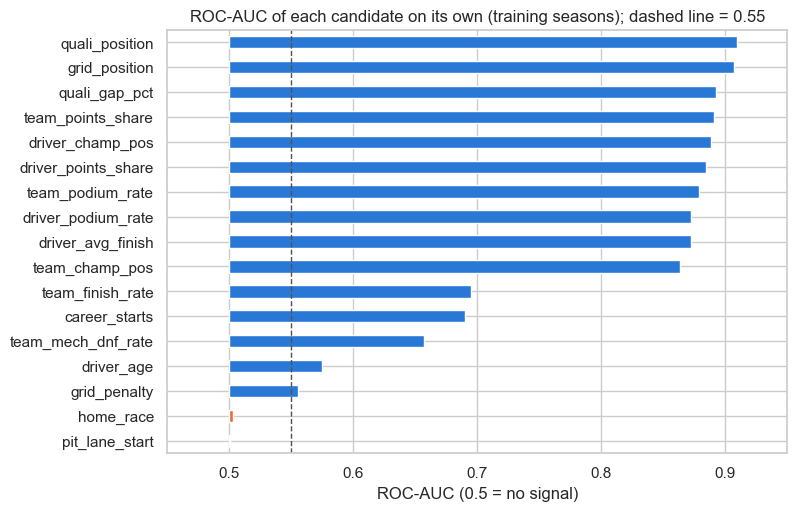

,family,ROC-AUC,PR-AUC,direction,% missing
quali_position,qualifying,0.909195,0.614444,lower → podium,0.28293
grid_position,grid,0.907086,0.619883,lower → podium,0.0
quali_gap_pct,qualifying,0.892569,0.594918,lower → podium,1.744734
team_points_share,standings,0.891228,0.51091,higher → podium,5.234203
driver_champ_pos,standings,0.888487,0.526748,lower → podium,5.234203
driver_points_share,standings,0.884723,0.540227,higher → podium,5.234203
team_podium_rate,form,0.878833,0.513538,higher → podium,0.518705
driver_podium_rate,form,0.872458,0.51568,higher → podium,1.13172
driver_avg_finish,form,0.872448,0.504379,lower → podium,1.13172
team_champ_pos,standings,0.863809,0.469201,lower → podium,5.234203


In [ ]:
family_of = {feature: family for family, members in FEATURE_FAMILIES.items() for feature in members}
relevance = pd.DataFrame({feature: single_feature_scores(train["podium"], train[feature]) for feature in CANDIDATES}).T
relevance.insert(0, "family", relevance.index.map(family_of))
relevance = relevance.sort_values("ROC-AUC", ascending=False)

ax = (relevance["ROC-AUC"] - 0.5).sort_values().plot.barh(
    figsize=(8, 5.5), left=0.5,
    color=["#eb6834" if v < 0.55 else "#2a78d6" for v in relevance["ROC-AUC"].sort_values()])
ax.axvline(0.55, color="#52514e", linestyle="--", linewidth=1)
ax.set_xlim(0.45, 0.95)
ax.set_title("ROC-AUC of each candidate on its own (training seasons); dashed line = 0.55")
ax.set_xlabel("ROC-AUC (0.5 = no signal)")
plt.show()
relevance.round(3)

- **Qualifying, grid, standings, and form** are all strong on their own (ROC-AUC 0.86–0.91). The best single feature
  is the qualifying position, closely followed by the grid position.
- **Reliability and experience** are weaker (0.66–0.70) but clearly informative: a team that often breaks down, or
  a rookie, rarely reaches the podium. `driver_age` is weak (0.57), mostly because it is a rough proxy for experience.
- **`home_race` (0.50) and `pit_lane_start` (0.50) carry no signal on their own.** For `home_race` this confirms
  2.2 (no home advantage once the grid is controlled for). Pit-lane starts are too rare (about 1% of rows) to matter.
- **`grid_penalty` is weak on its own (0.56)**, because most drivers have no penalty (0). Its value shows up only
  *together with* the qualifying position, which the next plot checks.

#### 3.5.2 What the effect looks like

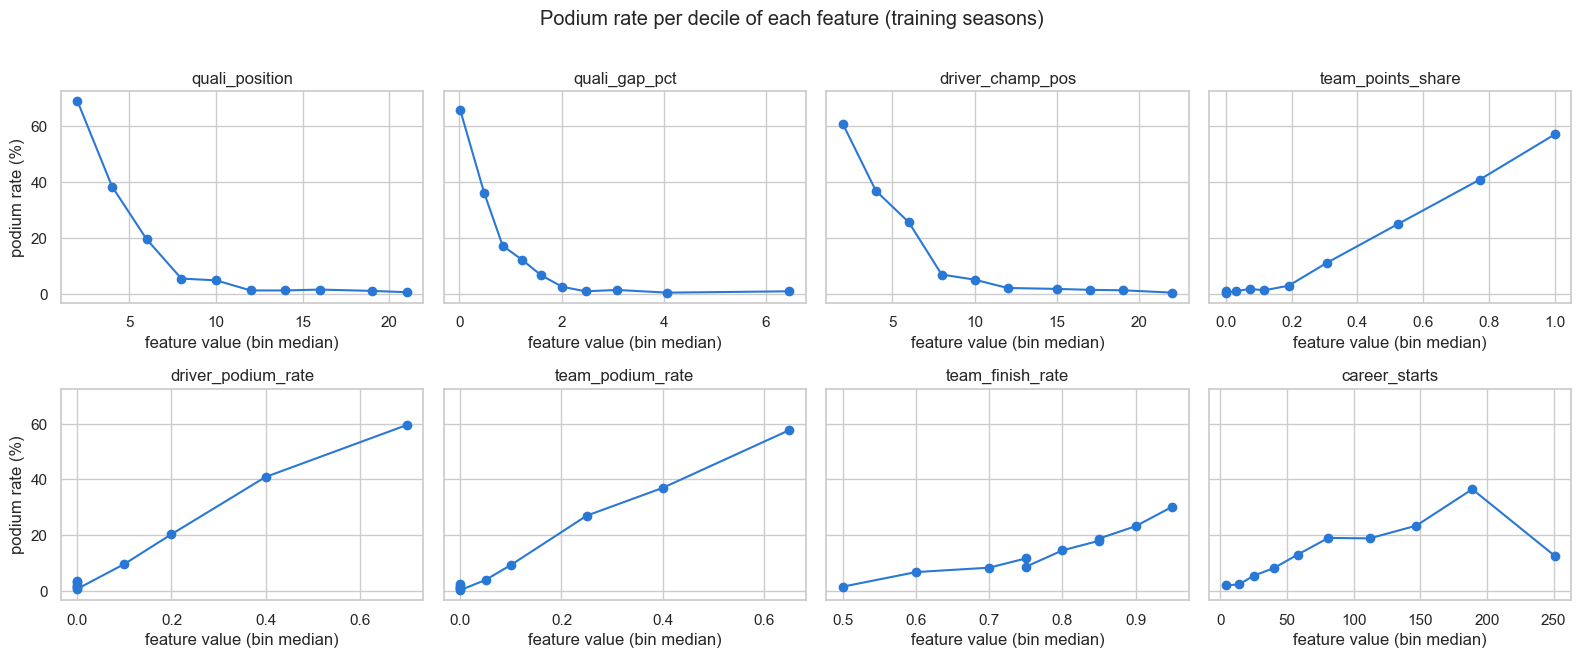

In [ ]:
def podium_rate_by_bins(df, feature, bins=10):
    """Podium rate per quantile bin of a feature (equal-count bins; ties merged)."""
    groups = pd.qcut(df[feature].rank(method="first"), q=bins, labels=False)
    return df.groupby(groups).agg(x=(feature, "median"), rate=("podium", "mean"))


shown = ["quali_position", "quali_gap_pct", "driver_champ_pos", "team_points_share",
         "driver_podium_rate", "team_podium_rate", "team_finish_rate", "career_starts"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharey=True)
for feature, ax in zip(shown, axes.ravel()):
    binned = podium_rate_by_bins(train.dropna(subset=[feature]), feature)
    ax.plot(binned["x"], binned["rate"] * 100, marker="o")
    ax.set_title(feature)
    ax.set_xlabel("feature value (bin median)")
axes[0, 0].set_ylabel("podium rate (%)")
axes[1, 0].set_ylabel("podium rate (%)")
plt.suptitle("Podium rate per decile of each feature (training seasons)", y=1.01)
plt.tight_layout()
plt.show()

- Seven of the eight features have a **monotonic** relationship with the podium rate: better qualifying, a smaller
  gap to pole, a higher championship position, more team points, better recent form, and better reliability all go
  with more podiums (e.g. the podium rate rises from 2% to 30% across the deciles of `team_finish_rate`). Monotonic
  patterns are easy for every model in section 4 to use, including logistic regression.
- **`career_starts` is the exception:** the podium rate rises from 2% (rookies) to 36% (about 190 starts) and then
  falls to 13% for the most experienced decile (about 250 starts), the veterans past their peak or in midfield cars
  late in their career. A linear model can only fit one direction; a tree or a neural network can follow the turn.
- The relationships are **not linear**: the podium rate falls from 69% to 5% within the first four qualifying
  deciles and is almost 0 after that, and it stays near 0 until a team has about 20% of the leader's points, then
  rises steeply to 57%. This motivates trying non-linear models (trees, a neural network) besides logistic regression
  in section 4.
- `quali_gap_pct` is **right-skewed** (the top decile median is 6.5%, a few rows beyond 10% in wet or disrupted
  sessions); this is handled in 3.6.

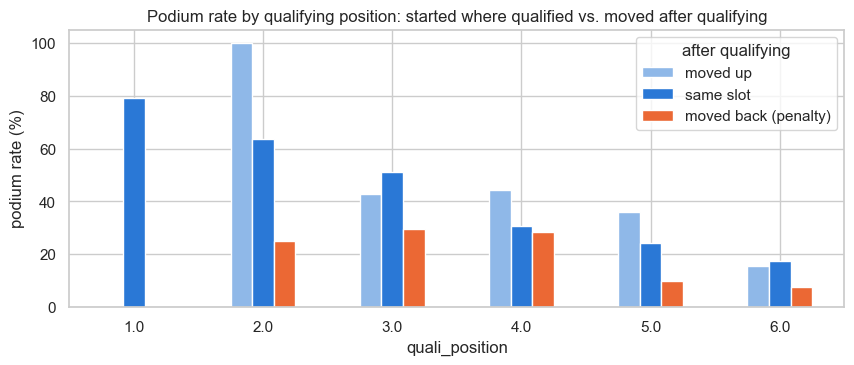

after qualifying,moved back (penalty),moved up,same slot
quali_position,,,
1.0,4,0,295
2.0,12,4,283
3.0,17,14,267
4.0,14,27,258
5.0,10,39,251
6.0,13,45,240


In [ ]:
# Does a grid penalty matter for drivers who qualified in the same place?
top = train[train["quali_position"] <= 6].copy()
top["after qualifying"] = np.select([top["grid_penalty"] > 0, top["grid_penalty"] < 0],
                                    ["moved back (penalty)", "moved up"], "same slot")
penalty_effect = top.groupby(["quali_position", "after qualifying"])["podium"].agg(["size", "mean"]).unstack()
ax = (penalty_effect["mean"][["moved up", "same slot", "moved back (penalty)"]] * 100).plot.bar(
    figsize=(10, 3.6), rot=0, color=["#8fb8e8", "#2a78d6", "#eb6834"])
ax.set_title("Podium rate by qualifying position: started where qualified vs. moved after qualifying")
ax.set_ylabel("podium rate (%)")
plt.show()
penalty_effect["size"].fillna(0).astype(int)

**`grid_penalty` is useful despite its weak AUC.** Among drivers with the *same* qualifying position, those moved
back reach the podium far less often than those who start where they qualified: from P2, 25% vs. 64%; from P3, 29%
vs. 51%; and none of the 4 pole-sitters moved back reached the podium (79% of the others did). Drivers moved *up*
mostly convert more often than those in their qualifying slot (from P4: 44% vs. 31%, from P5: 36% vs. 24%). The
penalty is information the qualifying position cannot carry, so it stays a candidate although it is 0 for about 94%
of the rows. (The "moved" groups are small, see the counts, so single bars are noisy; the direction is consistent.)

#### 3.5.3 Redundancy: which candidates repeat each other?

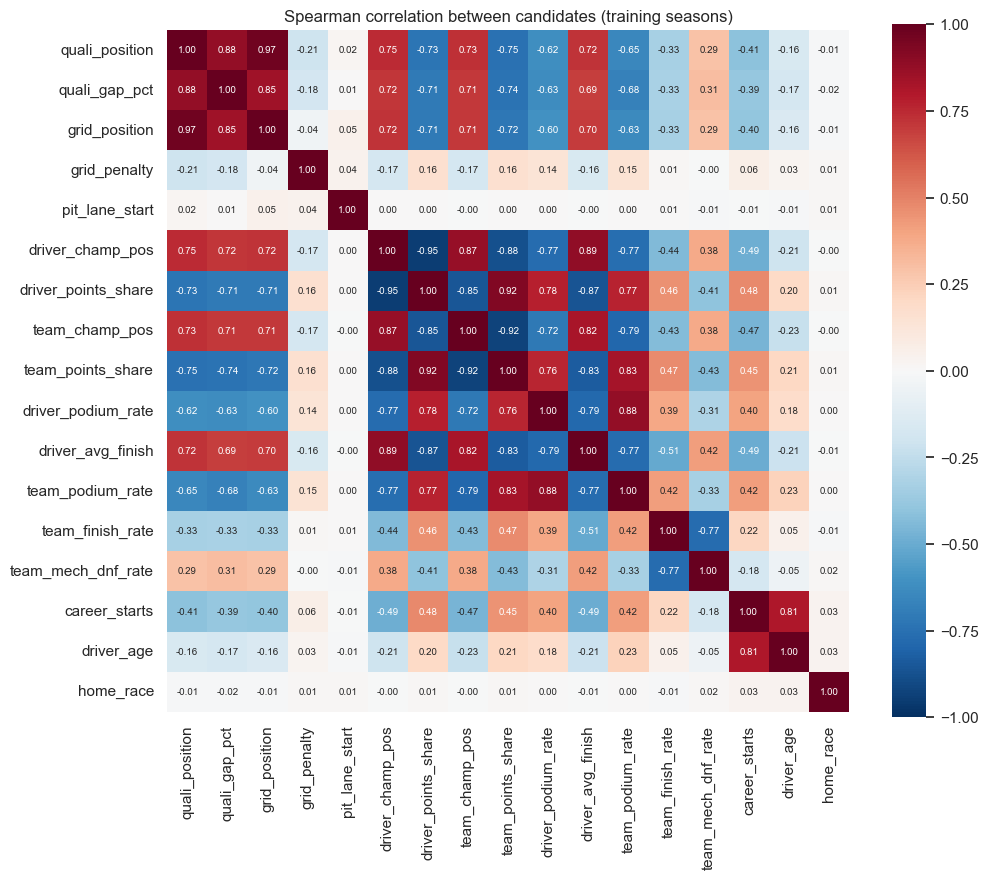

,feature A,feature B,spearman
1,quali_position,grid_position,0.971
70,driver_champ_pos,driver_points_share,-0.950
91,team_champ_pos,team_points_share,-0.923
82,driver_points_share,team_points_share,0.922


In [ ]:
spearman = train[CANDIDATES].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(spearman, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Spearman correlation between candidates (training seasons)")
plt.show()

pairs = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
pairs[pairs["spearman"].abs() >= 0.9].sort_values("spearman", key=abs, ascending=False).round(3)

- We use **Spearman** (rank) correlation, because the relationships are monotonic but not linear (3.5.2).
- Four pairs are almost the same information (|ρ| ≥ 0.9): **grid position vs. qualifying position** (0.97: the grid
  *is* the qualifying order for most drivers), **driver championship position vs. points share** (0.95), **team
  championship position vs. points share** (0.92), and **driver vs. team points share** (0.92: teammates share a car,
  so their points move together).
- **Why redundancy matters here:** two near-copies add no new information, make logistic-regression coefficients
  unstable, and split the importance between them in section 6 (permutation importance and SHAP would each show half
  of the effect), which makes the explanations misleading.
- Many other pairs are high but below 0.9 (e.g. form vs. standings, 0.78–0.89). They overlap but are not copies:
  standings cover the current season, form the last 10 races, so both are kept.

#### 3.5.4 The selection rule

We apply one rule to all candidates, in order of single-feature ROC-AUC (strongest first):
1. **Relevance:** drop a candidate whose ROC-AUC on its own is below **0.55**, *unless* it carries conditional
   information shown in 3.5.2 (`grid_penalty`).
2. **Redundancy:** drop a candidate with |Spearman ρ| ≥ **0.9** to a feature that is already kept (the stronger one
   of a pair is kept).

The thresholds are common rules of thumb: 0.55 means "at least slightly better than a coin flip", 0.9 means "the
two features rank the drivers almost identically".

In [ ]:
KEEP_DESPITE_LOW_AUC = {"grid_penalty": "adds what qualifying cannot: penalties (3.5.2)"}
selected, decisions = [], []
for feature, row in relevance.iterrows():
    copy_of = [kept for kept in selected if abs(spearman.loc[feature, kept]) >= 0.9]
    if row["ROC-AUC"] < 0.55 and feature not in KEEP_DESPITE_LOW_AUC:
        decision, reason = "drop", f"no signal on its own (ROC-AUC {row['ROC-AUC']:.3f})"
    elif copy_of:
        decision, reason = "drop", f"redundant with {copy_of[0]} (ρ = {spearman.loc[feature, copy_of[0]]:.2f})"
    else:
        decision = "keep"
        reason = KEEP_DESPITE_LOW_AUC.get(feature, f"relevant (ROC-AUC {row['ROC-AUC']:.3f}), not a copy")
        selected.append(feature)
    decisions.append({"feature": feature, "family": row["family"], "decision": decision, "reason": reason})

pd.DataFrame(decisions)

,feature,family,decision,reason
0,quali_position,qualifying,keep,"relevant (ROC-AUC 0.909), not a copy"
1,grid_position,grid,drop,redundant with quali_position (ρ = 0.97)
2,quali_gap_pct,qualifying,keep,"relevant (ROC-AUC 0.893), not a copy"
3,team_points_share,standings,keep,"relevant (ROC-AUC 0.891), not a copy"
4,driver_champ_pos,standings,keep,"relevant (ROC-AUC 0.888), not a copy"
5,driver_points_share,standings,drop,redundant with team_points_share (ρ = 0.92)
6,team_podium_rate,form,keep,"relevant (ROC-AUC 0.879), not a copy"
7,driver_podium_rate,form,keep,"relevant (ROC-AUC 0.872), not a copy"
8,driver_avg_finish,form,keep,"relevant (ROC-AUC 0.872), not a copy"
9,team_champ_pos,standings,drop,redundant with team_points_share (ρ = -0.92)


**Result: 12 of the 17 candidates are kept.** The 5 dropped ones and why:
- **`grid_position`**: a near-copy of `quali_position` (ρ = 0.97), which is very slightly stronger. **The grid
  information is not lost**: `quali_position + grid_penalty` is exactly the grid position. Keeping the pair
  (qualifying position, penalty) instead of (qualifying, grid) turns two near-identical columns into two almost
  unrelated ones (ρ = −0.21), each with its own meaning: *how fast the driver was* and *what happened to the grid
  afterwards*.
- **`driver_points_share`**: a copy of both `team_points_share` (0.92) and `driver_champ_pos` (0.95).
  **`team_champ_pos`**: a copy of `team_points_share` (0.92). What remains is one standings view per entity: the
  driver's championship position and the team's share of the leader's points.
- **`home_race`**: no signal, consistent with 2.2.
- **`pit_lane_start`**: no signal on its own, and a pit-lane start is already encoded as "behind the last slot" in
  `grid_penalty`.

#### 3.5.5 Experiment: does each family improve a simple model?

Single-feature scores cannot show whether a family adds anything **on top of** the others. So we add the selected
families one at a time to a simple logistic regression (median imputation and scaling, fitted on the training
seasons) and score it on the **validation** seasons. The last row adds back the 5 dropped candidates. The test
seasons are not used.

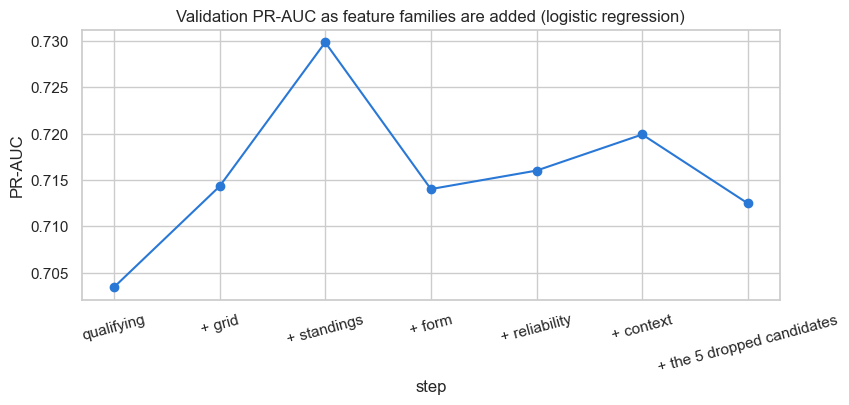

,features,validation ROC-AUC,validation PR-AUC
step,,,
qualifying,2,0.923,0.703
+ grid,3,0.925,0.714
+ standings,5,0.931,0.730
+ form,8,0.931,0.714
+ reliability,10,0.931,0.716
+ context,12,0.932,0.720
+ the 5 dropped candidates,17,0.932,0.712


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


def validation_probabilities(feature_list):
    """Logistic regression fitted on the training seasons; podium probabilities for the validation seasons."""
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(train[feature_list], train["podium"])
    return model.predict_proba(validation[feature_list])[:, 1]


def validation_scores(feature_list):
    p = validation_probabilities(feature_list)
    return {"features": len(feature_list), "validation ROC-AUC": roc_auc_score(validation["podium"], p),
            "validation PR-AUC": average_precision_score(validation["podium"], p)}


steps, cumulative = [], []
for family in FEATURE_FAMILIES:
    members = [f for f in FEATURE_FAMILIES[family] if f in selected]
    if members:
        cumulative = cumulative + members
        steps.append({"step": f"+ {family}" if steps else family, **validation_scores(cumulative)})
dropped = [f for f in CANDIDATES if f not in selected]
steps.append({"step": "+ the 5 dropped candidates", **validation_scores(cumulative + dropped)})
family_steps = pd.DataFrame(steps).set_index("step")

ax = family_steps["validation PR-AUC"].plot(marker="o", figsize=(9, 3.5), rot=15)
ax.set_title("Validation PR-AUC as feature families are added (logistic regression)")
ax.set_ylabel("PR-AUC")
plt.show()
family_steps.round(3)

In [ ]:
# How much would the validation PR-AUC move by chance? Resample the 60 validation races with replacement.
p_selected = validation_probabilities(selected)
y_validation, validation_races = validation["podium"].values, validation["raceId"].values
rows_of_race = {race: np.flatnonzero(validation_races == race) for race in np.unique(validation_races)}
rng = np.random.default_rng(0)
bootstrap = []
for _ in range(500):
    rows = np.concatenate([rows_of_race[race] for race in rng.choice(list(rows_of_race), size=len(rows_of_race))])
    bootstrap.append(average_precision_score(y_validation[rows], p_selected[rows]))
print(f"Validation PR-AUC of the selected set: {average_precision_score(y_validation, p_selected):.3f}, "
      f"standard error over resampled races: {np.std(bootstrap):.3f}")

Validation PR-AUC of the selected set: 0.720, standard error over resampled races: 0.047


- **Qualifying alone** already gives a strong model (validation PR-AUC 0.70). The **grid penalty** (+0.011) and the
  **standings** (+0.016) add on top of it.
- **Form, reliability, and context do not improve this linear model** once qualifying and standings are in
  (changes between −0.016 and +0.006). The resampling above shows why we do not read much into this: the validation
  PR-AUC has a standard error of about 0.05, so differences of ±0.01–0.02 between neighbouring rows are noise.
  Form also overlaps strongly with the standings (ρ 0.78–0.89, 3.5.3), so a linear model gains little from it.
- **We keep them anyway**, for three reasons: (1) each is clearly relevant on its own (3.5.1); (2) form is the only
  current-performance information in **round 1**, where all standings are missing (5% of rows); (3) this is one
  linear model, and the non-linear models of section 4 may use them differently. The feature-group ablation in
  section 5 measures their real contribution for every model, and is where a group would be dropped if it never helps.
- **Adding the 5 dropped candidates back does not help** (0.720 → 0.712), which is consistent with the selection rule:
  they are copies or noise.

#### 3.5.6 The selected feature set

In [ ]:
FEATURE_GROUPS = {family: [f for f in members if f in selected] for family, members in FEATURE_FAMILIES.items()}
FEATURE_GROUPS = {family: members for family, members in FEATURE_GROUPS.items() if members}
FEATURES = sum(FEATURE_GROUPS.values(), [])
assert set(FEATURES) == set(selected)

pd.DataFrame([(group, feature, relevance.loc[feature, "ROC-AUC"]) for group, members in FEATURE_GROUPS.items()
              for feature in members], columns=["group", "feature", "single-feature ROC-AUC"]).round(3)

,group,feature,single-feature ROC-AUC
0,qualifying,quali_position,0.909
1,qualifying,quali_gap_pct,0.893
2,grid,grid_penalty,0.556
3,standings,driver_champ_pos,0.888
4,standings,team_points_share,0.891
5,form,driver_podium_rate,0.872
6,form,driver_avg_finish,0.872
7,form,team_podium_rate,0.879
8,reliability,team_finish_rate,0.695
9,reliability,team_mech_dnf_rate,0.657


| Group | Feature | Why it is valid at the pre-race cutoff |
|---|---|---|
| qualifying | `quali_position`, `quali_gap_pct` | qualifying is finished before the race |
| grid | `grid_penalty` | the official grid and the qualifying result are both fixed before the start |
| standings | `driver_champ_pos`, `team_points_share` | taken after the **previous** round, never the same `raceId` (3.1) |
| form | `driver_podium_rate`, `driver_avg_finish`, `team_podium_rate` | previous 10 races only (`shift(1)`, 3.4.1) |
| reliability | `team_finish_rate`, `team_mech_dnf_rate` | previous 10 races only |
| context | `career_starts`, `driver_age` | entries before this race; date of birth |

`FEATURE_GROUPS` is the definition the feature-group ablation in section 5 removes one group at a time.

**Not used as features, on purpose:** `driverId`, `constructorId`, and `circuitId` as categories. They are labels,
not measurements: a team's id says nothing stable about its speed (Mercedes was a midfield team in 2010 and dominant
in 2015), 2022–2024 contain drivers and teams the training seasons never saw, and one-hot encoding several hundred
ids would let the model memorise names instead of learning from performance. The strength of a driver or team enters
through standings, form, and reliability instead, which update every race.

### 3.6 Preprocessing, Encoding, and Effects on Feature Distributions

**Principle: every preprocessing step is fitted on the training seasons only** (the medians, the scaling means and
standard deviations) and then *applied* unchanged to validation and test. Fitting on all rows would let the test
seasons shape the inputs (a leak through preprocessing); section 5 tests what happens when this order is changed.

The steps, and why each is needed:
1. **Missing values → median of the training seasons, plus one missing-value flag per reason.** All gaps are missing
   by design (3.4.5), and *that* a value is missing is itself informative (round 1, a debutant, a new team). 1.5.2
   concluded that such gaps should become flags rather than silently filled averages: the flag keeps that
   information, the median keeps the column usable for every model. Because each family is missing on the same rows,
   we add **one flag per reason (5)**, not one per column (10): duplicated flag columns would carry no new
   information and would split the importance between identical columns in section 6.
2. **The one skewed, unbounded feature → `log1p`** (`quali_gap_pct`, tested below).
3. **Scaling → standardisation** (mean 0, standard deviation 1 on training). Regularised logistic regression and the
   neural network need features on the same scale; tree models do not care, and it does not hurt them.
4. **Encoding:** none needed. All 12 features are numeric; there are no categorical features left (the ids are
   excluded on purpose, 3.5.6), and the flags are already 0/1.
5. **Class imbalance is not changed here** (no over- or under-sampling): the data keeps its real 14.4% podium rate, so
   predicted probabilities stay meaningful. Imbalance is handled in section 4 (class weights, threshold choice).

#### 3.6.1 Skewness and the `log1p` trial

In [ ]:
skewness = train[FEATURES].agg(["skew", "min", "max"]).T.sort_values("skew", ascending=False)
skewness.round(2)

,skew,min,max
grid_penalty,4.91,-7.00,23.00
quali_gap_pct,4.63,0.00,37.80
driver_podium_rate,1.72,0.00,1.00
team_mech_dnf_rate,1.59,0.00,1.00
team_podium_rate,1.57,0.00,1.00
team_points_share,1.00,0.00,1.00
career_starts,0.83,0.00,325.00
driver_age,0.49,17.45,43.89
driver_champ_pos,0.15,1.00,28.00
quali_position,0.06,1.00,24.00


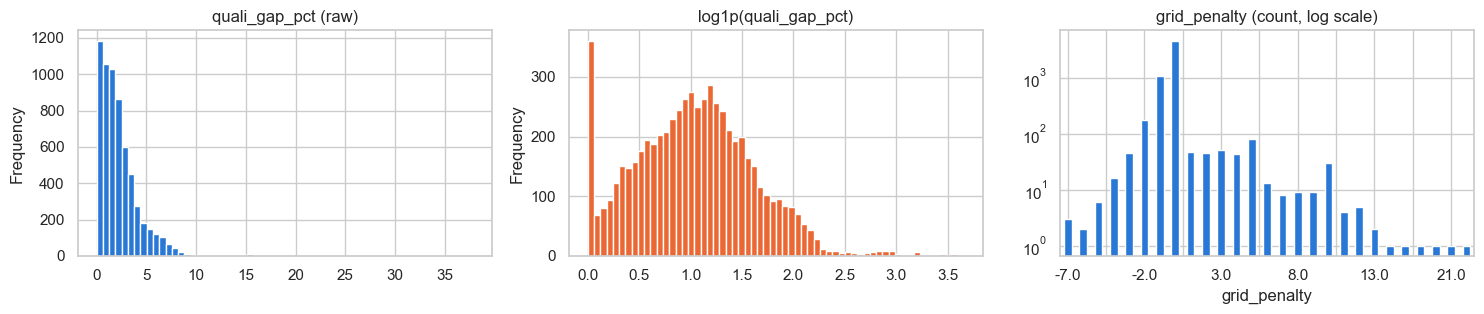

quali_gap_pct: 1.4% of rows are more than 10% off pole, maximum 37.8%


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
train["quali_gap_pct"].plot.hist(bins=60, ax=axes[0], title="quali_gap_pct (raw)")
np.log1p(train["quali_gap_pct"]).plot.hist(bins=60, ax=axes[1], color="#eb6834", title="log1p(quali_gap_pct)")
train["grid_penalty"].value_counts().sort_index().plot.bar(ax=axes[2], logy=True, rot=0,
                                                          title="grid_penalty (count, log scale)")
axes[2].xaxis.set_major_locator(plt.MaxNLocator(12))
plt.tight_layout()
plt.show()
print(f"quali_gap_pct: {(train['quali_gap_pct'] > 10).mean():.1%} of rows are more than 10% off pole, "
      f"maximum {train['quali_gap_pct'].max():.1f}%")

Which features get `log1p`, and why only one:
- **`quali_gap_pct`** (skewness 4.6): most drivers are within 2% of pole, but a few sessions (rain, red flags, a
  driver who barely ran) give gaps up to 38%. After standardisation these few rows would sit far out (more than 10
  standard deviations), and a linear model or neural network would bend to fit them. `log1p` pulls the tail in, keeps
  the order, and keeps 0 (pole) at 0.
- **`grid_penalty`** (skewness 4.9) is skewed too, but it is **signed** (−7 to +23), so `log1p` cannot be applied
  without an arbitrary shift, and its large values are rare real events (pit-lane starts, engine penalties) whose
  size matters. It is only scaled.
- **The rates** (`driver_podium_rate`, `team_podium_rate`, `team_mech_dnf_rate`, skewness 1.6–1.7) are skewed by many
  zeros but are bounded between 0 and 1: there are no extreme values to tame. `career_starts` (0.8) is only mildly
  skewed. They are only scaled.

In [ ]:
from sklearn.impute import MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

LOG_FEATURES = ["quali_gap_pct"]
MISSING_FLAGS = {   # one representative column per reason a value can be missing (3.4.5)
    "quali_position": "no qualifying result",
    "quali_gap_pct": "no qualifying time",
    "driver_champ_pos": "round 1: no standings yet",
    "driver_podium_rate": "the driver's first race",
    "team_podium_rate": "the team's first race",
}


def log_transform(X):
    X = X.copy()
    X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
    return X


def make_preprocessor(flags=True, log=True):
    """[log1p] -> median imputation (+ one missing flag per reason) -> standardisation. Fit on training rows only."""
    values = make_pipeline(FunctionTransformer(log_transform if log else None, feature_names_out="one-to-one"),
                           SimpleImputer(strategy="median"))
    parts = [("values", values, FEATURES)]
    if flags:
        parts.append(("flags", MissingIndicator(features="all"), list(MISSING_FLAGS)))
    return make_pipeline(ColumnTransformer(parts, verbose_feature_names_out=False),
                         StandardScaler()).set_output(transform="pandas")


def validation_scores_with(preprocessor):
    """Logistic regression on the selected features with a given preprocessing, scored on validation."""
    model = make_pipeline(preprocessor, LogisticRegression(max_iter=1000)).fit(train[FEATURES], train["podium"])
    p = model.predict_proba(validation[FEATURES])[:, 1]
    return {"validation ROC-AUC": roc_auc_score(validation["podium"], p),
            "validation PR-AUC": average_precision_score(validation["podium"], p)}


pd.DataFrame({
    "A: median + scale": validation_scores_with(make_preprocessor(flags=False, log=False)),
    "B: A + missing flags": validation_scores_with(make_preprocessor(flags=True, log=False)),
    "C: B + log1p(quali_gap_pct)": validation_scores_with(make_preprocessor(flags=True, log=True)),
}).T.round(4)

,validation ROC-AUC,validation PR-AUC
A: median + scale,0.9322,0.7199
B: A + missing flags,0.9382,0.7298
C: B + log1p(quali_gap_pct),0.9392,0.7362


**Trial result (logistic regression, validation seasons):**
- **Missing flags (A → B):** ROC-AUC 0.932 → 0.938, PR-AUC 0.720 → 0.730. The model can now tell a round-1 driver
  (median imputed) from a driver who really is in mid-table, and a debutant from a driver with average form.
- **`log1p` (B → C):** ROC-AUC 0.938 → 0.939, PR-AUC 0.730 → 0.736.
- Both steps point in the same direction, but each gain is smaller than the standard error of the validation PR-AUC
  (≈ 0.05, 3.5.5), so this trial alone does not prove them. The decision therefore rests on the reasons given above
  (the flags carry real information, the log tames a handful of extreme gaps that matter most for the neural
  network), and the trial shows that neither step hurts. Whether the order of these steps matters is one of the
  preprocessing experiments in section 5.

**Decision: C** (log1p on `quali_gap_pct` → median imputation + 5 missing flags → standardisation).

#### 3.6.2 The final preprocessing pipeline

In [ ]:
preprocessor = make_preprocessor()
X_train = preprocessor.fit_transform(train[FEATURES])   # fitted on the training seasons only
X_val = preprocessor.transform(validation[FEATURES])
X_test = preprocessor.transform(test[FEATURES])
y_train, y_val, y_test = train["podium"].values, validation["podium"].values, test["podium"].values

print("Model inputs:", list(X_train.columns))
pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_test)], "columns": [X_train.shape[1]] * 3,
              "podium rate": [round(y.mean(), 3) for y in (y_train, y_val, y_test)],
              "missing values left": [int(X.isna().sum().sum()) for X in (X_train, X_val, X_test)]},
             index=["train", "validation", "test"])

Model inputs: ['quali_position', 'quali_gap_pct', 'grid_penalty', 'driver_champ_pos', 'team_points_share', 'driver_podium_rate', 'driver_avg_finish', 'team_podium_rate', 'team_finish_rate', 'team_mech_dnf_rate', 'career_starts', 'driver_age', 'missingindicator_quali_position', 'missingindicator_quali_gap_pct', 'missingindicator_driver_champ_pos', 'missingindicator_driver_podium_rate', 'missingindicator_team_podium_rate']


,rows,columns,podium rate,missing values left
train,6362,17,0.141,0
validation,1193,17,0.151,0
test,1351,17,0.151,0


#### 3.6.3 Effect of preprocessing on the feature distributions

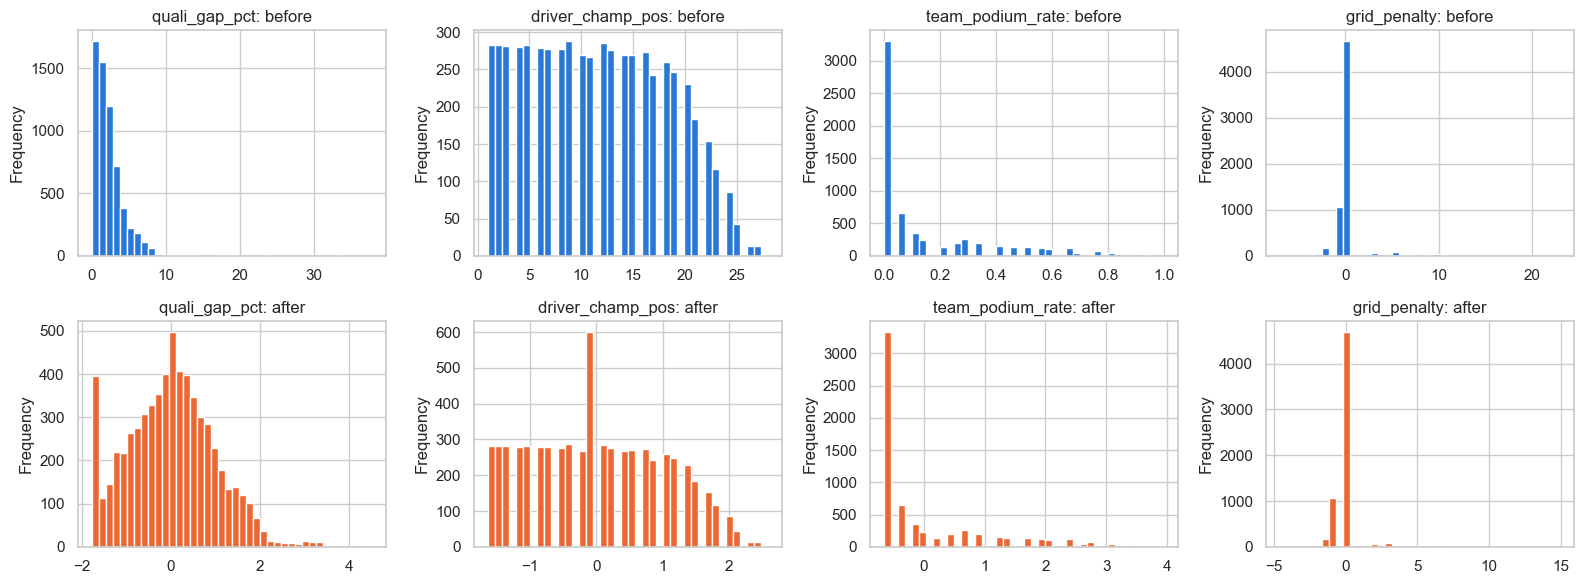

,before: min,before: max,before: mean,before: std,after: min,after: max,after: mean (train),after: std (train),after: mean (val),after: mean (test)
quali_position,1.00,24.00,11.19,6.24,-1.63,2.05,-0.0,1.0,-0.12,-0.11
quali_gap_pct,0.00,37.80,2.40,2.66,-1.78,4.51,-0.0,1.0,-0.09,-0.26
grid_penalty,-7.00,23.00,0.00,1.54,-4.56,14.97,0.0,1.0,0.03,0.01
driver_champ_pos,1.00,28.00,11.50,6.58,-1.63,2.58,-0.0,1.0,-0.13,-0.12
team_points_share,0.00,1.00,0.30,0.34,-0.89,2.14,0.0,1.0,-0.01,0.02
driver_podium_rate,0.00,1.00,0.14,0.23,-0.60,3.69,0.0,1.0,0.04,0.05
driver_avg_finish,1.20,24.00,11.18,4.25,-2.37,3.04,0.0,1.0,-0.17,-0.19
team_podium_rate,0.00,1.00,0.14,0.22,-0.65,3.95,-0.0,1.0,0.02,0.04
team_finish_rate,0.00,1.00,0.76,0.14,-5.37,1.68,-0.0,1.0,0.58,0.67
team_mech_dnf_rate,0.00,1.00,0.12,0.11,-1.11,7.83,0.0,1.0,-0.44,-0.55


In [ ]:
shown = ["quali_gap_pct", "driver_champ_pos", "team_podium_rate", "grid_penalty"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for col, feature in enumerate(shown):
    train[feature].plot.hist(bins=40, ax=axes[0, col], title=f"{feature}: before")
    X_train[feature].plot.hist(bins=40, ax=axes[1, col], color="#eb6834", title=f"{feature}: after")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "before: min": train[FEATURES].min(), "before: max": train[FEATURES].max(),
    "before: mean": train[FEATURES].mean(), "before: std": train[FEATURES].std(),
    "after: min": X_train[FEATURES].min(), "after: max": X_train[FEATURES].max(),
    "after: mean (train)": X_train[FEATURES].mean(), "after: std (train)": X_train[FEATURES].std(),
    "after: mean (val)": X_val[FEATURES].mean(), "after: mean (test)": X_test[FEATURES].mean(),
}).round(2)

**What preprocessing changed:**
- **Range:** before, the features lived on very different scales (`career_starts` 0–325, rates 0–1, championship
  position 1–28, age 17–44). After, every feature has mean 0 and standard deviation 1 on the training seasons, so no
  feature dominates a gradient-based model (logistic regression, neural network) just because of its unit.
- **Shape:** `log1p` turned the long tail of `quali_gap_pct` into a compact distribution: the largest gap was 13
  standard deviations above the mean before, and is 4.5 after. Standardisation alone does not change shapes:
  `driver_champ_pos`, `team_podium_rate`, and `grid_penalty` have the same histogram before and after, only on a new
  axis (`grid_penalty` keeps its rare extreme values, up to 15 standard deviations, on purpose, see 3.6.1).
- **Missing values:** none are left. The imputed medians show up as a spike at one value (e.g. the round-1 rows in
  `driver_champ_pos`), and the 5 **missing flags** (`missingindicator_…`) tell the model which rows those are. The
  model sees 17 columns: 12 features + 5 flags.
- **Validation and test are not centred at 0, and that is expected.** They are transformed with the training
  statistics, so differences between eras show up. The largest are the reliability features: in the
  validation/test seasons `team_finish_rate` is 0.6–0.7 standard deviations higher and `team_mech_dnf_rate` 0.4–0.6
  lower than in 2003–2018 (cars break down less often today, as 2.3 also found), and careers are longer
  (`career_starts` +0.3 in validation, +0.7 in test). This **era drift** is a limitation for the report: the model
  learns from seasons in which reliability and careers looked different from the seasons it is tested on.

**Handed over to section 4:** `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`, the fitted `preprocessor`
(and `make_preprocessor()` for a fresh copy, with switches for the preprocessing experiments in section 5),
`FEATURES` and `FEATURE_GROUPS` (for the ablation in section 5), and `modeling_table` (one row per driver-race with
the split, the target, and all candidate features). The same `preprocessor` turns a partially missing record into
valid model inputs, which the inference function in section 7 relies on.

## 4. Predictive Modeling Task

All models are trained on **the same rows and the same inputs**: `X_train` from 3.6 (6,362 rows; 12 features + 5
missing flags = 17 columns), with the same preprocessing. They are scored with the same metrics on the same rows, so
their scores are directly comparable.

The protocol:
1. **Fit** every model on the training seasons (2003–2018).
2. **Choose** hyperparameters and the decision threshold on the validation seasons (2019–2021) only.
3. **Score** the test seasons (2022–2024) **once**, in 4.6, after every choice is fixed. Nothing in 4.6–4.7 is used to
   change a choice made before.

### 4.1 Baseline and Primary/Secondary Evaluation Metrics

#### 4.1.1 The metrics

| Metric | Needs a threshold? | What it tells us here |
|---|---|---|
| ROC-AUC | no | how often a random podium row is ranked above a random non-podium row |
| PR-AUC (average precision) | no | how precise the model's ranking is while it finds more and more of the podium finishers; chance level = podium rate (≈ 0.15) |
| F1 | yes | harmonic mean of precision and recall at the chosen threshold |
| Precision | yes | of the drivers predicted on the podium, the share that got there |
| Recall | yes | of the drivers who got on the podium, the share the model predicted |

**Primary metric: PR-AUC.**
1. **Podiums are rare** (14–15% of rows, 1.1.5). ROC-AUC also rewards ranking the many obvious non-podium rows
   (backmarkers) low, which is easy: even the no-learning rule below reaches 0.92. PR-AUC only asks how well the podium
   finishers are found and how clean the top of the ranking is, which is where the models actually differ.
2. **It needs no threshold**, so when we tune hyperparameters we compare models, not thresholds.
3. **It matches the use**: rank the drivers of a race by their podium chance.

**Secondary metric: F1 at the threshold chosen on validation.** In the end a user wants a yes/no answer ("podium or
not?"). F1 scores that decision and weighs false alarms and missed podiums equally: nothing in our task makes one of
them worse than the other. Precision and recall are reported next to it to show where the F1 comes from.

ROC-AUC is reported for every model, as required, but no decision is based on it.

**Selection rules, fixed before any model is trained:**
- hyperparameters → highest validation PR-AUC
- threshold → highest validation F1
- final model → highest validation PR-AUC (4.6)

#### 4.1.2 Baselines
- **Chance**: no model. PR-AUC = the podium rate, ROC-AUC = 0.5.
- **Rule "qualified top 3"**: no learning, predicts a podium for P1–P3 in qualifying. Qualifying position is the
  strongest single feature (3.5.1), so this is the reference any learned model must beat to be worth anything.
- **Baseline LR**: the required statistical baseline. Logistic regression with scikit-learn's default settings
  (C = 1, no class weights) on all 17 inputs. Every other model must earn its extra complexity against it.

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, precision_recall_curve, roc_curve


def scores(y, p, threshold):
    """The five metrics: two ranking metrics (no threshold) and three at a probability threshold."""
    predicted = (p >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, predicted), "precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted)}


def best_threshold(y, p):
    """Probability threshold with the highest F1 on (y, p). Only ever called on validation predictions."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def race_bootstrap(y, p, races, metric=average_precision_score, n=1000, seed=0):
    """Metric on n resamples of whole races (rows of one race stay together, 3.3)."""
    rows_of = [np.flatnonzero(races == race) for race in np.unique(races)]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        rows = np.concatenate([rows_of[i] for i in rng.integers(len(rows_of), size=len(rows_of))])
        out.append(metric(y[rows], p[rows]))
    return np.array(out)


MODEL_COLORS = ["#8fb8e8", "#2a78d6", "#3a9e6f", "#eb6834", "#8e5bb5"]   # baseline, LR, RF, boosting, NN
SPLIT_DATA = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}
races_of_split = {"train": train["raceId"].values, "validation": validation["raceId"].values,
                  "test": test["raceId"].values}

In [ ]:
def qualifying_rule(df):
    """No learning: 'the top 3 qualifiers finish on the podium'. Score = 1 / qualifying position, so the threshold
    1/3 means exactly 'qualified P1-P3'. A driver without a qualifying result gets 0."""
    return (1 / df["quali_position"]).fillna(0).values


p_rule = qualifying_rule(validation)
baseline_lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)   # default settings, nothing tuned
p_baseline = baseline_lr.predict_proba(X_val)[:, 1]

pd.DataFrame({
    "chance (no model)": {"ROC-AUC": 0.5, "PR-AUC": y_val.mean()},
    "rule: qualified top 3 (threshold 1/3)": scores(y_val, p_rule, 1 / 3),
    "baseline LR (threshold 0.5)": scores(y_val, p_baseline, 0.5),
    f"baseline LR (F1-best threshold {best_threshold(y_val, p_baseline):.2f})":
        scores(y_val, p_baseline, best_threshold(y_val, p_baseline)),
}).T.round(3)

,ROC-AUC,PR-AUC,F1,precision,recall
chance (no model),0.500,0.151,NaN,NaN,NaN
rule: qualified top 3 (threshold 1/3),0.921,0.681,0.702,0.704,0.700
baseline LR (threshold 0.5),0.939,0.736,0.697,0.711,0.683
baseline LR (F1-best threshold 0.23),0.939,0.736,0.736,0.639,0.867


- The rule is already strong (validation PR-AUC 0.681, F1 0.702). The qualifying order explains most of the podium.
- The **baseline LR beats it by +0.055 PR-AUC** (0.736). The other inputs (standings, form, penalties, …) add real
  information on top of the qualifying order.
- **The threshold matters for F1.** At the default 0.5, the baseline LR has F1 0.697, *below* the rule. At its F1-best
  threshold (0.23), F1 is 0.736. 0.5 is an arbitrary cut for a class that is only 15% of the rows: a driver with a 30%
  podium chance is already a strong candidate. So every model gets its own threshold, chosen on validation (4.5).

### 4.2 Statistical Model 1: Logistic Regression

**How it works.** Logistic regression computes a weighted sum of the inputs, $z = w \cdot x + b$, and turns it into a
probability with the sigmoid $p = 1 / (1 + e^{-z})$. The weights minimise the log-loss on the training rows plus an L2
penalty $\lVert w \rVert^2 / (2C)$ that pulls them towards 0 (smaller C = stronger pull). On standardised inputs, each
weight is the change in the log-odds of a podium for +1 standard deviation of that input, *holding the others fixed*.

**Why it fits here:** 3.5.2 showed that most features have a monotonic relation with the podium rate, which a model
that is linear in the log-odds can follow. It is fast and stable, and its probabilities are usually well calibrated.

**Tuned (12 settings):**
- `C` ∈ {0.001, 0.01, 0.1, 1, 10, 100}
- `class_weight` ∈ {none, balanced}. Balanced weights each podium row about 6× to equalise the two classes.

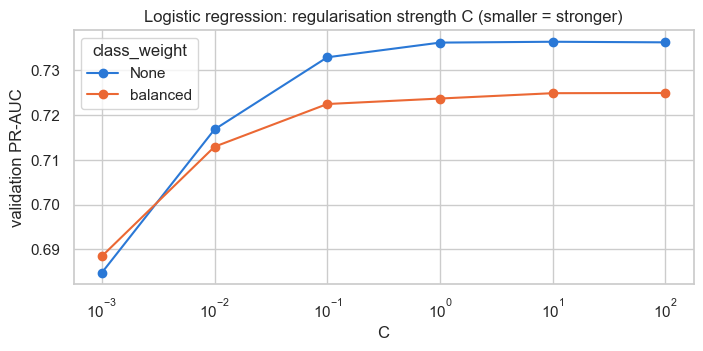

,C,class_weight,train PR-AUC,validation ROC-AUC,validation PR-AUC
8,10.0,None,0.6864,0.9392,0.7364
10,100.0,None,0.6864,0.9392,0.7363
6,1.0,None,0.6866,0.9392,0.7362
4,0.1,None,0.6859,0.9386,0.7329
11,100.0,balanced,0.6794,0.9366,0.7250
9,10.0,balanced,0.6794,0.9366,0.7249


In [ ]:
LR_GRID = [{"C": C, "class_weight": weight} for C in [0.001, 0.01, 0.1, 1, 10, 100] for weight in [None, "balanced"]]


def tune(make_model, grid):
    """Fit one model per setting on the training seasons and score it on the validation seasons."""
    rows = []
    for params in grid:
        model = make_model(**params).fit(X_train, y_train)
        p_train, p_val = model.predict_proba(X_train)[:, 1], model.predict_proba(X_val)[:, 1]
        rows.append({**{k: str(v) if isinstance(v, tuple) or v is None else v for k, v in params.items()},
                     "train PR-AUC": average_precision_score(y_train, p_train),
                     "validation ROC-AUC": roc_auc_score(y_val, p_val),
                     "validation PR-AUC": average_precision_score(y_val, p_val)})
    return pd.DataFrame(rows)


lr_results = tune(lambda **params: LogisticRegression(max_iter=1000, **params), LR_GRID)
ax = lr_results.pivot(index="C", columns="class_weight", values="validation PR-AUC").plot(
    marker="o", logx=True, figsize=(8, 3.3), color=["#2a78d6", "#eb6834"])
ax.set_ylabel("validation PR-AUC")
ax.set_title("Logistic regression: regularisation strength C (smaller = stronger)")
plt.show()
lr_results.sort_values("validation PR-AUC", ascending=False).head(6).round(4)

- **Strong regularisation hurts** (C = 0.001: PR-AUC 0.685; C = 0.01: 0.717): it shrinks real effects towards 0. From
  C = 1 on the score is flat (0.736). With 6,362 rows and 17 inputs there is little overfitting to prevent: the
  training PR-AUC (0.687) is not even above the validation PR-AUC.
- Training PR-AUC *below* validation is not a sign of a problem: the validation seasons are easier to predict. 2019–2021
  were dominated by two teams (Mercedes, Red Bull), while the training seasons include more open years.
- **`class_weight="balanced"` is worse for every C ≥ 0.1** (e.g. 0.724 vs. 0.736 at C = 1). Reweighting adds no
  information; it shifts every probability upwards and distorts them. We handle the imbalance with the threshold instead
  (4.5), which keeps the probabilities meaningful.
- **Chosen: C = 10, no class weights.** This is practically the baseline (+0.0002 PR-AUC): the defaults were already
  right, and tuning cannot do much for a linear model here.

Chosen: {'C': 10, 'class_weight': None}


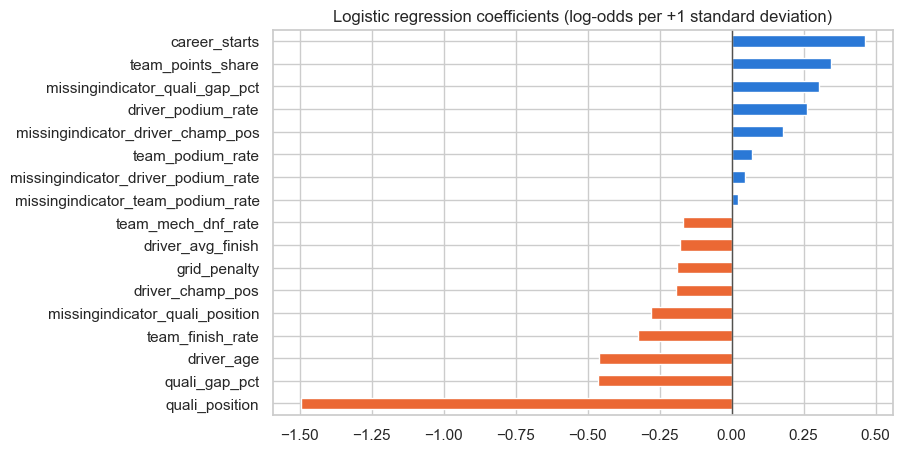

In [ ]:
LR_PARAMS = LR_GRID[lr_results["validation PR-AUC"].idxmax()]   # the setting with the best validation PR-AUC
logistic = LogisticRegression(max_iter=1000, **LR_PARAMS).fit(X_train, y_train)
print("Chosen:", LR_PARAMS)

# Coefficients on standardised inputs: the change in log-odds for +1 standard deviation of the feature
coefficients = pd.Series(logistic.coef_[0], index=X_train.columns).sort_values()
ax = coefficients.plot.barh(figsize=(8, 5), color=["#eb6834" if c < 0 else "#2a78d6" for c in coefficients])
ax.set_title("Logistic regression coefficients (log-odds per +1 standard deviation)")
ax.axvline(0, color="#52514e", linewidth=1)
plt.show()

**Reading the coefficients.** These are associations *inside the model*, not causes (see section 6):
- `quali_position` dominates (−1.50): starting one standard deviation (about 6 places) further back lowers the log-odds
  of a podium by 1.5.
- Then come `quali_gap_pct` (−0.47), `career_starts` (+0.46), `driver_age` (−0.46), and `team_points_share` (+0.34).
  Age and starts have opposite signs: *for the same experience*, younger drivers do better (they are mostly the ones
  promoted early into top cars). Each coefficient only makes sense together with the other.
- `team_finish_rate` gets a *negative* weight (−0.33), although on its own it goes with more podiums (3.5.2). It
  overlaps with standings and form, and the model uses it as a correction. Correlated inputs must not be read one
  coefficient at a time.

**Limitations of logistic regression:**
- Each input enters the log-odds along a single straight line. It cannot follow the rise-and-fall of `career_starts`
  (3.5.2) or the saturation of the qualifying effect (steep in the first places, flat after).
- It cannot model interactions without hand-made features. For example, a grid penalty costs a front-row qualifier a
  lot and a P15 qualifier almost nothing.
- The tree models and the network below can learn all three patterns. 4.6 tests whether that helps.

### 4.3 Statistical Model 2: Tree Ensembles (Random Forest and Gradient Boosting)

We try two tree ensembles. Both can model what the linear model cannot (curves, thresholds, interactions), and neither
needs scaling.

- **Random forest (bagging):** 300 decision trees. Each tree is grown on a bootstrap sample of the rows and considers a
  random subset of the inputs at every split. The forest averages the trees' probabilities; averaging many deep,
  different trees reduces variance.
  - Tuned (8 settings): `min_samples_leaf` (how small a leaf may get, the main protection against memorising rows) and
    `max_features` (share of inputs considered per split).
- **Gradient boosting (`HistGradientBoostingClassifier`):** small trees are added one after another. Each new tree is
  fitted to the remaining errors (the gradient of the log-loss) of the trees before it, scaled by a learning rate. It
  reduces bias step by step.
  - Tuned (24 settings): learning rate, leaves per tree (how complex the interactions can be), minimum rows per leaf,
    and number of trees.
  - Built-in early stopping is off (as in 5.4); the number of trees is tuned instead.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

RF_GRID = [{"min_samples_leaf": leaf, "max_features": features}
           for leaf in [1, 5, 20, 50] for features in ["sqrt", 0.5]]
rf_results = tune(lambda **params: RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1, **params),
                  RF_GRID)
rf_results.sort_values("validation PR-AUC", ascending=False).round(4)

,min_samples_leaf,max_features,train PR-AUC,validation ROC-AUC,validation PR-AUC
5,20,0.5,0.7828,0.9387,0.7391
3,5,0.5,0.9323,0.9408,0.7388
4,20,sqrt,0.7672,0.9387,0.7353
7,50,0.5,0.7273,0.9385,0.7334
2,5,sqrt,0.9088,0.9383,0.7301
6,50,sqrt,0.7175,0.9375,0.7262
0,1,sqrt,1.0000,0.9358,0.7104
1,1,0.5,1.0000,0.9371,0.7072


- **Unrestricted leaves memorise the training seasons.** With `min_samples_leaf = 1` the training PR-AUC is 1.000, and
  the validation PR-AUC is the worst in the grid (0.707–0.710).
- Leaves of at least 20 rows cut the training score to 0.78 and give the best validation PR-AUC (0.739).
- **Chosen:** `min_samples_leaf = 20`, `max_features = 0.5`.

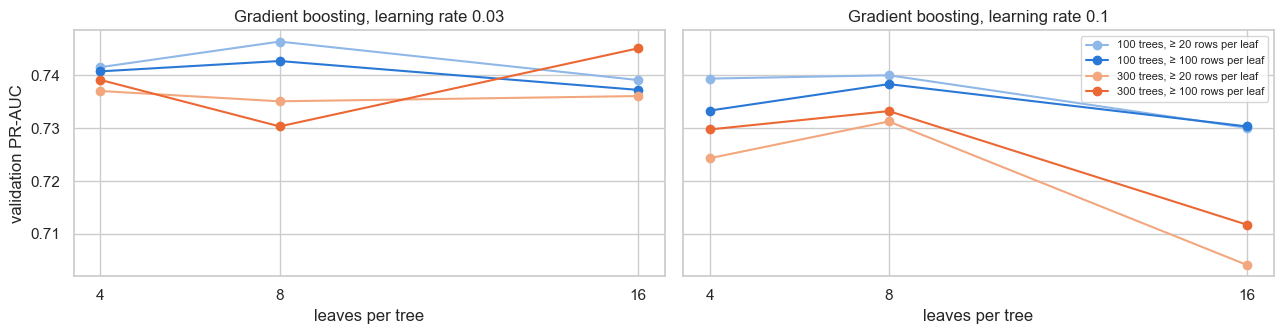

,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,train PR-AUC,validation ROC-AUC,validation PR-AUC
4,0.03,8,20,100,0.7270,0.9396,0.7464
11,0.03,16,100,300,0.8226,0.9368,0.7451
6,0.03,8,100,100,0.7214,0.9392,0.7427
0,0.03,4,20,100,0.6983,0.9398,0.7415
2,0.03,4,100,100,0.6971,0.9399,0.7407
16,0.10,8,20,100,0.7936,0.9396,0.7400


In [ ]:
HGB_GRID = [{"learning_rate": rate, "max_leaf_nodes": leaves, "min_samples_leaf": leaf, "max_iter": rounds}
            for rate in [0.03, 0.1] for leaves in [4, 8, 16] for leaf in [20, 100] for rounds in [100, 300]]
hgb_results = tune(lambda **params: HistGradientBoostingClassifier(early_stopping=False, random_state=0, **params),
                   HGB_GRID)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, rate in zip(axes, [0.03, 0.1]):
    groups = hgb_results[hgb_results["learning_rate"] == rate].groupby(["max_iter", "min_samples_leaf"])
    for ((rounds, leaf), group), color in zip(groups, ["#8fb8e8", "#2a78d6", "#f2a77f", "#eb6834"]):
        ax.plot(group["max_leaf_nodes"], group["validation PR-AUC"], marker="o", color=color,
                label=f"{rounds} trees, ≥ {leaf} rows per leaf")
    ax.set_title(f"Gradient boosting, learning rate {rate}")
    ax.set_xlabel("leaves per tree")
    ax.set_xticks([4, 8, 16])
axes[0].set_ylabel("validation PR-AUC")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
hgb_results.sort_values("validation PR-AUC", ascending=False).head(6).round(4)

- **The slow learning rate (0.03) is as good or better in almost every setting.** With 0.1, larger trees overfit
  quickly: 16 leaves, 300 trees, and ≥ 20 rows per leaf reach a training PR-AUC of 0.989 but only 0.704 on validation.
- **Best:** learning rate 0.03, 8 leaves, ≥ 20 rows per leaf, 100 trees. Validation PR-AUC is 0.746 against a training
  PR-AUC of 0.727, so there is no overfitting gap.
- The top 6 settings are within 0.007 of each other, far below the noise level of the validation PR-AUC (≈ 0.05,
  3.5.5). The exact setting matters much less than staying out of the overfitting corner (fast learning + large trees).

In [ ]:
RF_PARAMS = RF_GRID[rf_results["validation PR-AUC"].idxmax()]
HGB_PARAMS = HGB_GRID[hgb_results["validation PR-AUC"].idxmax()]
forest = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1, **RF_PARAMS).fit(X_train, y_train)
boosting = HistGradientBoostingClassifier(early_stopping=False, random_state=0, **HGB_PARAMS).fit(X_train, y_train)
print("Random forest:", RF_PARAMS)
print("Gradient boosting:", HGB_PARAMS)

Random forest: {'min_samples_leaf': 20, 'max_features': 0.5}
Gradient boosting: {'learning_rate': 0.03, 'max_leaf_nodes': 8, 'min_samples_leaf': 20, 'max_iter': 100}


**Limitations of the tree ensembles:**
- **Step-shaped predictions.** A tree's output changes in jumps, and a random forest's probabilities are pulled
  towards the middle by averaging. Calibration is checked in 4.7.
- **No extrapolation.** A value beyond the training range is treated like the largest value seen in training. This
  matters because the 2022–2024 reliability and career values lie outside the 2003–2018 range (3.6.3).
- **The forest overfits even with 20-row leaves.** Its training PR-AUC is 0.04 above validation (4.6).
- **Harder to read than coefficients.** They need the explanation methods of section 6.

### 4.4 Shallow Neural Network

**Architecture:** 17 inputs → 1 or 2 hidden layers (ReLU activation, dropout) → 1 output with a sigmoid (the podium
probability).

**Training (Keras with TensorFlow):** Adam optimiser (learning rate 0.001), mini-batches of 128 rows, binary cross-entropy loss (the
same log-loss as logistic regression). Each hidden unit learns its own combination of the inputs, so the network can
model curves and interactions. Without a hidden layer it would be exactly logistic regression, so it directly tests
whether non-linearity helps.

**Regularisation.** 6,362 training rows is small for a network, so three tools keep it from memorising them:
- **Dropout:** randomly switches off hidden units during training.
- **Weight decay:** an L2 penalty on all weights and biases, with coefficient `weight_decay / 2`,
  matching the coupled L2 penalty used by the previous Adam implementation.
- **Early stopping:** after every epoch, the loss on the validation seasons is checked. Training stops after 25 epochs
  without improvement, and the weights of the best epoch are kept. The number of epochs is therefore chosen on
  validation, like every other hyperparameter.

**Why shallow:** the inputs are 17 engineered numbers. Deeper networks need far more data and bring no benefit on small
tabular data.

**Tuned (16 settings):**
- width (8, 32, or 64 units) and depth (1 layer, or 2 layers of 32 → 16)
- dropout ∈ {0, 0.3}
- weight decay ∈ {0, 0.001}

The network uses the standardised inputs from 3.6, which gradient-based training needs. (Requires `pip install tensorflow keras`.)

Keras provides `Sequential`, `fit`, and an `EarlyStopping` callback for this shallow network.
Seeds are fixed and TensorFlow deterministic operations are enabled. Keras initialisation and
batch shuffling differ from PyTorch, so rerun 4.4 onward to obtain the new scores and model selection.

In [ ]:
import tensorflow as tf
import keras

tf.config.experimental.enable_op_determinism()


class ShallowNet:
    """Keras feed-forward network with the same fit / predict_proba interface as the other models.

    Early stopping uses only the supplied validation seasons and restores the best weights.
    history_ contains per-epoch training and validation binary cross-entropy (without the L2 penalty).
    """

    def __init__(self, hidden=(32,), dropout=0.2, weight_decay=1e-4, lr=1e-3, batch_size=128, max_epochs=300,
                 patience=25, seed=0, validation=None):
        self.hidden, self.dropout, self.weight_decay, self.lr = hidden, dropout, weight_decay, lr
        self.batch_size, self.max_epochs, self.patience, self.seed = batch_size, max_epochs, patience, seed
        self.validation = validation

    @staticmethod
    def _array(a):
        return np.asarray(a, dtype=np.float32)

    def fit(self, X, y):
        X_val, y_val = self.validation
        Xt, yt = self._array(X), self._array(y).reshape(-1, 1)
        Xv, yv = self._array(X_val), self._array(y_val).reshape(-1, 1)
        assert Xt.ndim == Xv.ndim == 2 and Xt.shape[1] == Xv.shape[1]
        assert len(Xt) == len(yt) and len(Xv) == len(yv)
        assert all(np.isfinite(a).all() for a in (Xt, yt, Xv, yv))
        assert np.isin(yt, [0, 1]).all() and np.isin(yv, [0, 1]).all()

        keras.backend.clear_session()
        keras.utils.set_random_seed(self.seed)
        # PyTorch Adam's coupled decay adds decay * parameter to each gradient.
        # L2(decay / 2) reproduces that penalty, including biases; Adam(weight_decay=...)
        # would instead use decoupled decay in Keras.
        penalty = keras.regularizers.L2(self.weight_decay / 2)
        layers = [keras.Input(shape=(Xt.shape[1],))]
        for size in self.hidden:
            layers += [keras.layers.Dense(size, activation="relu", kernel_regularizer=penalty,
                                          bias_regularizer=penalty),
                       keras.layers.Dropout(self.dropout)]
        layers.append(keras.layers.Dense(1, activation="sigmoid", kernel_regularizer=penalty,
                                         bias_regularizer=penalty))
        self.net = keras.Sequential(layers)
        self.net.compile(optimizer=keras.optimizers.Adam(learning_rate=self.lr, epsilon=1e-8),
                         loss=keras.losses.BinaryCrossentropy(),
                         metrics=[keras.metrics.BinaryCrossentropy(name="bce")])
        # Monitor BCE alone, as before: Keras val_loss also includes the L2 penalty.
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_bce", mode="min", min_delta=1e-4, patience=self.patience,
            restore_best_weights=True)
        history = self.net.fit(Xt, yt, validation_data=(Xv, yv), batch_size=self.batch_size,
                               epochs=self.max_epochs, shuffle=True, callbacks=[early_stopping], verbose=0)
        self.history_ = list(zip(history.history["bce"], history.history["val_bce"]))
        self.best_epoch_ = int(early_stopping.best_epoch) + 1
        return self

    def predict_proba(self, X):
        p = self.net(self._array(X), training=False).numpy().reshape(-1).astype(float)
        return np.column_stack([1 - p, p])


In [ ]:
NN_GRID = [{"hidden": hidden, "dropout": dropout, "weight_decay": decay}
           for hidden in [(8,), (32,), (64,), (32, 16)] for dropout in [0.0, 0.3] for decay in [0.0, 1e-3]]
nn_results = tune(lambda **params: ShallowNet(**params, validation=(X_val, y_val)), NN_GRID)
nn_results.sort_values("validation PR-AUC", ascending=False).round(4)

The table above compares all 16 Keras settings on validation PR-AUC. The next cell chooses the highest
validation score, then checks that architecture over five seeds. The previous PyTorch scores and chosen
architecture are not reused: framework initialisation and batch order can change the ranking.


In [ ]:
NN_PARAMS = NN_GRID[nn_results["validation PR-AUC"].idxmax()]
network = ShallowNet(**NN_PARAMS, validation=(X_val, y_val)).fit(X_train, y_train)
print("Chosen:", NN_PARAMS, f"| best epoch: {network.best_epoch_}")

# Same architecture, 5 different random seeds: how much does the result depend on the initial weights?
seed_scores = [average_precision_score(y_val, ShallowNet(**NN_PARAMS, seed=seed, validation=(X_val, y_val)).fit(X_train, y_train)
                                       .predict_proba(X_val)[:, 1]) for seed in range(5)]
print(f"Validation PR-AUC over 5 seeds: mean {np.mean(seed_scores):.3f}, "
      f"min {np.min(seed_scores):.3f}, max {np.max(seed_scores):.3f}")

curve = pd.DataFrame(network.history_, columns=["training loss", "validation loss"], index=range(1, len(network.history_) + 1))
ax = curve.plot(figsize=(8, 3.3), color=["#2a78d6", "#eb6834"])
ax.axvline(network.best_epoch_, color="#52514e", linestyle="--", linewidth=1, label="kept weights")
ax.set_xlabel("epoch")
ax.set_ylabel("binary cross-entropy")
ax.set_title("Shallow network: learning curve (early stopping on the validation loss)")
ax.legend()
plt.show()

The learning curve shows training and validation binary cross-entropy. Training BCE is measured during
mini-batch updates with dropout active; validation BCE is measured after each epoch with dropout off.
Neither curve includes the L2 penalty. The dashed line marks the epoch whose weights were restored.
The printed seed range measures sensitivity to random initialisation and batch order.

**Limitations of the network:**
- It is a black box: no coefficients to read (section 6 explains it).
- It needs scaled, imputed inputs, and has more settings to tune than any other model.
- Its benefit over simpler models must be assessed using the refreshed comparison in 4.6.


### 4.5 Hyperparameter and Threshold Selection on Training/Validation Data

Every choice in this section uses **only the training and validation seasons**. The test seasons appear for the first
time in 4.6.

#### 4.5.1 Chosen hyperparameters and thresholds
Each threshold is the one with the highest F1 on the validation predictions of that model.

In [ ]:
MODELS = {
    "baseline LR": baseline_lr,
    "logistic regression": logistic,
    "random forest": forest,
    "gradient boosting": boosting,
    "shallow NN": network,
}
CHOSEN = pd.DataFrame([
    ("baseline LR", "defaults: C = 1, no class weights", "—"),
    ("logistic regression", str(LR_PARAMS), f"{len(LR_GRID)} settings"),
    ("random forest", str({"n_estimators": 300, **RF_PARAMS}), f"{len(RF_GRID)} settings"),
    ("gradient boosting", str(HGB_PARAMS), f"{len(HGB_GRID)} settings"),
    ("shallow NN", str({**NN_PARAMS, "epochs": network.best_epoch_}), f"{len(NN_GRID)} settings"),
], columns=["model", "chosen hyperparameters", "grid searched"]).set_index("model")

validation_probs = {name: model.predict_proba(X_val)[:, 1] for name, model in MODELS.items()}
THRESHOLDS = {name: best_threshold(y_val, p) for name, p in validation_probs.items()}
CHOSEN["threshold (max F1 on validation)"] = pd.Series(THRESHOLDS).round(3)
with pd.option_context("display.max_colwidth", None):
    display(CHOSEN)

#### 4.5.2 How sensitive is F1 to the threshold?

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
grid = np.linspace(0.05, 0.95, 91)
for (name, p), color in zip(validation_probs.items(), MODEL_COLORS):
    ax.plot(grid, [f1_score(y_val, p >= t) for t in grid], label=name, color=color)
    ax.plot(THRESHOLDS[name], f1_score(y_val, p >= THRESHOLDS[name]), "o", color=color)
ax.axvline(0.5, color="#52514e", linestyle=":", linewidth=1)
ax.set_xlabel("probability threshold")
ax.set_ylabel("validation F1")
ax.set_title("F1 against the threshold on the validation seasons (dot = chosen threshold, dotted = 0.5)")
ax.legend(fontsize=8)
plt.show()

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

- **For every model the F1 curve is flat between about 0.2 and 0.45**: there it stays within about 0.02 of the best,
  and it falls steeply beyond 0.6. The exact threshold therefore matters little, as long as it is not the default 0.5
  for the logistic models.
- **The thresholds differ by model** (0.23 for logistic regression, 0.38–0.46 for the trees and the network) because
  their probabilities have different scales. This is why each model gets its own threshold.
- Choosing the threshold on the validation data makes the **validation F1 slightly optimistic**. The test F1 in 4.6 is
  the honest number.

#### 4.5.3 An alternative decision rule: the top 3 of each race
Every race has exactly 3 podium places (3.2). Instead of a probability threshold, we could predict a podium for the 3
drivers with the highest probability in each race. This rule is valid at the cutoff: every driver's inputs are known
after qualifying.

In [ ]:
def top3_per_race(p, races):
    """Alternative decision rule: in every race, predict a podium for the 3 drivers with the highest probability."""
    order = pd.DataFrame({"p": p, "race": races}).groupby("race")["p"].rank(method="first", ascending=False)
    return (order <= 3).astype(int).values


rule_rows = []
for name, p in validation_probs.items():
    for rule_name, predicted in [("threshold", (p >= THRESHOLDS[name]).astype(int)),
                                 ("top 3 per race", top3_per_race(p, races_of_split["validation"]))]:
        rule_rows.append({"model": name, "decision rule": rule_name, "F1": f1_score(y_val, predicted),
                          "precision": precision_score(y_val, predicted), "recall": recall_score(y_val, predicted),
                          "predicted podiums per race": predicted.sum() / validation["raceId"].nunique()})
pd.DataFrame(rule_rows).set_index(["model", "decision rule"]).round(3).unstack().swaplevel(axis=1).sort_index(axis=1)

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

- **The probability threshold gives a higher validation F1 for every model** (0.730–0.738 vs. 0.689–0.706 for the
  top 3).
- Exactly three picks per race cannot adapt to the race. When several cars are fast, a fourth pick raises recall
  (0.77–0.87 vs. 0.69–0.71) at a small cost in precision. When one car dominates, the threshold picks fewer drivers.
- **Decision: keep the probability threshold.** It is also the decision rule the task asks for.

### 4.6 Model Comparison: Training, Validation, and Unseen Test Performance

The test seasons (2022–2024) are scored here **for the first time**. Every hyperparameter, threshold, and decision
rule above is fixed. The table reports all five metrics on all three sets, each at the model's own threshold from 4.5
(the rule's threshold is fixed at "top 3").

In [ ]:
rows = []
for name, model in MODELS.items():
    for split, (X, y) in SPLIT_DATA.items():
        rows.append({"model": name, "split": split, **scores(y, model.predict_proba(X)[:, 1], THRESHOLDS[name])})
rule_frames = {"train": train, "validation": validation, "test": test}
for split, frame in rule_frames.items():
    rows.append({"model": "rule: qualified top 3", "split": split,
                 **scores(frame["podium"].values, qualifying_rule(frame), 1 / 3)})
comparison = pd.DataFrame(rows).set_index(["model", "split"])
model_order = ["rule: qualified top 3"] + list(MODELS)
comparison.unstack("split").swaplevel(axis=1)[["train", "validation", "test"]].loc[model_order].round(3)

To check whether the differences are real, we compare each model with the baseline LR on 1,000 resamples of whole
races. Both models are scored on the same resampled races, so the comparison is paired.

In [ ]:
probs = {split: {name: model.predict_proba(X)[:, 1] for name, model in MODELS.items()}
         for split, (X, _) in SPLIT_DATA.items() if split != "train"}
probs["validation"]["rule: qualified top 3"] = qualifying_rule(validation)
probs["test"]["rule: qualified top 3"] = qualifying_rule(test)
test_probs = probs["test"]


def pr_auc_difference(split, name, reference="baseline LR"):
    """PR-AUC of `name` minus the reference, with a 95% interval from 1,000 resamples of whole races (paired: both
    models are scored on the same resampled races, because race_bootstrap uses the same seed)."""
    y, races = SPLIT_DATA[split][1], races_of_split[split]
    diff = race_bootstrap(y, probs[split][name], races) - race_bootstrap(y, probs[split][reference], races)
    point = average_precision_score(y, probs[split][name]) - average_precision_score(y, probs[split][reference])
    return {f"{split} PR-AUC": average_precision_score(y, probs[split][name]), f"{split}: Δ vs. baseline LR": point,
            f"{split}: 95% interval of Δ": f"[{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]"}


significance = pd.DataFrame.from_dict({name: {**pr_auc_difference("validation", name), **pr_auc_difference("test", name)}
                                       for name in model_order if name != "baseline LR"}, orient="index")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "F1"]):
    comparison[metric].unstack("split").loc[model_order, ["train", "validation", "test"]].plot.barh(
        ax=ax, color=["#8fb8e8", "#2a78d6", "#eb6834"], legend=metric == "F1")
    ax.set_title(metric)
    ax.set_xlim(0.4 if metric != "ROC-AUC" else 0.8, 1.0)
    ax.invert_yaxis()
    ax.set_ylabel("")
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.suptitle("Model comparison: train / validation / test", y=1.02)
plt.tight_layout()
plt.show()
significance.round(3)

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

**Training vs. validation (overfitting check).**
- **Only the random forest** has a clearly higher training than validation score (PR-AUC 0.783 vs. 0.739): even with
  20-row leaves, its trees memorise part of the training seasons.
- For logistic regression, gradient boosting, and the network, the training score is at or below the validation
  score. As noted in 4.2, the validation seasons are simply easier.

**Validation → test.**
- **Every learned model drops by 0.04–0.06 PR-AUC** on the test seasons (e.g. gradient boosting 0.746 → 0.690). There
  are two reasons:
  1. validation was used to choose settings and thresholds, so its scores are slightly optimistic;
  2. 2022–2024 is a new regulation era (3.3) whose features have drifted away from the training seasons (3.6.3).
- **The qualifying rule drops just as much** (0.681 → 0.628), although nothing was tuned for it. Most of the drop
  therefore comes from the test seasons being harder, not from the models overfitting the validation set.

**Against the baselines.**
- **Every learned model clearly beats the qualifying rule.** On test it gains +0.05 to +0.07 PR-AUC and +0.02 to +0.04
  F1. The rule's difference to the baseline LR has an interval of [−0.112, −0.024], which excludes 0.
- **No model beats the baseline LR beyond noise.** On test the differences range from −0.018 to +0.000, and every 95%
  interval includes 0. On validation the largest gain is +0.010 (gradient boosting, interval [−0.023, +0.045]).
- **The more complex models do not earn their complexity on the primary metric.** The 12 engineered features are
  mostly monotonic (3.5.2), so a linear model already captures almost all of the signal. The non-linear patterns
  (the `career_starts` turn, penalties for front qualifiers) are real but concern few rows.

**Precision, recall, and F1 on test.**
- **Logistic regression** reaches its F1 (0.65) with high recall (0.88) and low precision (0.52). On test, its threshold
  of 0.23 predicts about 5 podiums per race, against 4 on validation (see 4.7).
- **The trees and the network** predict 3.2–3.4 per race, closer to the real 3, with balanced precision and recall
  (0.62–0.64 / 0.67–0.71).
- **The F1 scores are close** (0.652–0.671): the models differ in the type of error, not the amount.

In [ ]:
# The final model is chosen on the validation seasons only (primary metric), never on the test scores above
FINAL_MODEL = max(MODELS, key=lambda name: comparison.loc[(name, "validation"), "PR-AUC"])
final_model, final_threshold = MODELS[FINAL_MODEL], THRESHOLDS[FINAL_MODEL]
print(f"Final model: {FINAL_MODEL} (validation PR-AUC {comparison.loc[(FINAL_MODEL, 'validation'), 'PR-AUC']:.3f}, "
      f"threshold {final_threshold:.3f})")

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

**Final model: gradient boosting**, chosen by the rule fixed in 4.1 (highest validation PR-AUC: 0.746).
- The shallow network is only 0.0004 behind, and no model is distinguishable from the baseline LR. The choice is
  therefore a weak one, and we say so.
- We keep gradient boosting for sections 5–7 because:
  1. it has the best primary metric on validation;
  2. its probabilities are well calibrated, and it predicts about 3 podiums per race, like reality (4.7);
  3. unlike logistic regression, it can represent the non-linear patterns of 3.5.2, which makes the explanations in
     section 6 more informative.
- **The baseline LR remains the reference.** On test, the final model does not beat it (0.690 vs. 0.697, interval
  [−0.039, +0.024]).

### 4.7 Evaluation Plots and Model Limitations

#### 4.7.1 ROC and precision-recall curves (test seasons)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for (name, p), color in zip(test_probs.items(), MODEL_COLORS + ["#52514e"]):
    fpr, tpr, _ = roc_curve(y_test, p)
    precision, recall, _ = precision_recall_curve(y_test, p)
    style = ":" if name.startswith("rule") else "-"
    axes[0].plot(fpr, tpr, style, color=color, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(recall, precision, style, color=color, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
axes[1].axhline(y_test.mean(), color="#c3c2b7", linewidth=1, label=f"chance ({y_test.mean():.3f})")
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves, test seasons 2022–2024")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curves, test seasons 2022–2024")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

- **ROC-AUC cannot tell the models apart.** The five ROC curves of the learned models lie on top of each other
  (0.931–0.935), which confirms PR-AUC as the primary metric.
- **The PR curves show where learning helps.** Up to a recall of about 0.6, the qualifying rule is as precise as the
  models: the first podium candidates are simply the top qualifiers.
- **Beyond that, the rule's precision collapses**, because it can only rank the other drivers by qualifying. The models
  keep a precision of about 0.4–0.5 up to a recall of 0.9: standings, team strength, and form let them find podium
  finishers who started further back.

#### 4.7.2 Confusion matrices and calibration (test seasons)

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, name in zip(axes, ["rule: qualified top 3"] + list(MODELS)[1:]):
    threshold = 1 / 3 if name.startswith("rule") else THRESHOLDS[name]
    matrix = confusion_matrix(y_test, test_probs[name] >= threshold)
    sns.heatmap(matrix, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
    ax.set_title(f"{name}\n(threshold {threshold:.2f})", fontsize=10)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("actual")
plt.suptitle("Confusion matrices on the test seasons", y=1.05)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for (name, p), color in zip(test_probs.items(), MODEL_COLORS):
    if name.startswith("rule"):
        continue
    observed, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", color=color, label=name)
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, label="perfect calibration")
ax.set(xlabel="mean predicted probability", ylabel="observed podium rate", title="Calibration on the test seasons")
ax.legend(fontsize=8)
plt.show()

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

**Confusion matrices** (1,351 test rows, 204 podiums):

| Model | Podiums found | Podiums missed | False alarms |
|---|---|---|---|
| logistic regression | 181 | 23 | 169 |
| gradient boosting | 137 | 67 | 78 |
| qualifying rule | 128 | 76 | 75 |

- Logistic regression finds the most podiums but raises twice as many false alarms as the others.
- Gradient boosting and the network sit near the rule's balance of errors, but find 9–17 more podiums.

**Calibration.**
- All models lie close to the diagonal: a predicted 20% means roughly 20% of those drivers got a podium. The mean
  predicted probability is 0.15–0.17, against a real rate of 0.151. Not reweighting the classes (4.2) is what keeps
  this true.
- **Gradient boosting is closest to the diagonal.** The network slightly overestimates its most confident predictions
  (≈ 0.53 predicted, 0.44 observed).
- The probabilities can be read as podium chances, which the inference function (section 7) relies on.

#### 4.7.3 Performance per test season

In [ ]:
season_rows = []
for year, rows_of_year in test.groupby("year").indices.items():
    for name in ["rule: qualified top 3", "logistic regression", "gradient boosting", "shallow NN"]:
        season_rows.append({"season": int(year), "model": name,
                            "PR-AUC": average_precision_score(y_test[rows_of_year], test_probs[name][rows_of_year])})
per_season = pd.DataFrame(season_rows).pivot(index="season", columns="model", values="PR-AUC")
per_season.loc["test (all 3)"] = [average_precision_score(y_test, test_probs[name]) for name in per_season.columns]
per_season.round(3)

**Historical interpretation (previous PyTorch run):** rerun 4.4 onward and review these numerical
conclusions against the Keras results before reporting them.

- **2023 is the easiest test season** (PR-AUC 0.74–0.77): one dominant car, so standings and form point to the same
  drivers all year.
- **2024 is the hardest** (0.64–0.69). Four teams won races and the order changed during the season. Logistic
  regression and gradient boosting fall to the level of the qualifying rule (0.642 / 0.640 vs. 0.640); only the network
  keeps an edge (0.687).
- The history features (standings, form) describe *past* races. When the competitive order shifts, they lag behind,
  and the models are left with qualifying.

#### 4.7.4 Limitations

| Limitation | Evidence | Consequence |
|---|---|---|
| **No information about the race itself** | the ceiling of ~0.70 test PR-AUC is shared by every model, including the network | crashes, weather, safety cars, and strategy decide many podiums but are unknown at the cutoff; no model can predict them |
| **Era drift** | every model and the rule drop 0.04–0.06 from validation to test; feature means shift (3.6.3) | the models learn from 2003–2018, when cars broke down more often and careers were shorter |
| **History features lag behind change** | 2024: the models fall to the level of the qualifying rule | when the competitive order changes during a season, standings and form point to last month's fastest cars |
| **Small validation set** (60 races) | standard error of the validation PR-AUC ≈ 0.05; all tuned settings are within noise | hyperparameter and model choices are weakly determined; we rely on intervals, not on single numbers |
| **Thresholds transfer imperfectly** | logistic regression predicts 4 podiums per race on validation, 5 on test | the F1 threshold is tied to the probability scale of the validation seasons |
| **Each driver is predicted separately** | probabilities within a race are not forced to sum to 3 | the race structure (exactly 3 podiums) is only used implicitly, through the inputs |
| **Model-specific** | 4.2–4.4 | LR: linear in each input; random forest: memorises training rows (train 0.78 vs. test 0.68); boosting: step-shaped and no extrapolation; network: black box with the most settings, and no gain on this data |

## 5. Experiments

### 5.1 Feature-Group Ablation

### 5.2 Preprocessing-Order Experiment 1

### 5.3 Preprocessing-Order Experiment 2

### 5.4 Full-History Experiment: Training on 1950–2018 vs. 2003–2018

**Question.** Section 3.2 builds modelling rows only from 2003, because qualifying is complete only from then.
The seasons 1950–2002 are used only as history for the form and career features. Would the models do better if those
seasons were also **training rows**?

To keep all seasons, the qualifying features have to work without qualifying. We test a **hybrid feature set**:
- `grid_position` (known for every race since 1950) replaces `quali_position`;
- `quali_gap_pct` and `grid_penalty` are kept where qualifying exists, and are missing (with a flag) everywhere else;
- every other selected feature is unchanged (3.5.6).

Three configurations, each trained with a logistic regression and a gradient-boosted tree model (default settings,
no tuning):

| Configuration | Training rows | Features | Purpose |
|---|---|---|---|
| current | 2003–2018 | `FEATURES` (3.5.6) | the implementation used in sections 4–7 |
| hybrid features, 2003+ rows | 2003–2018 | hybrid | effect of the feature change alone |
| Option C | **1950–2018** | hybrid | effect of adding the old seasons |

Everything else is held fixed: the same validation rows (2019–2021), the same preprocessing steps (3.6, fitted on each
configuration's own training rows), and the test seasons are not used. Gradient boosting's built-in early stopping is
switched off, because it would switch itself on only for the larger Option C training set.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Every starter from 1950 to 2024 (same "started" rule as 3.2); seasons before 2003 go to training
all_seasons = history.loc[history["started"] & history["year"].le(LAST_YEAR), ["raceId", "driverId", "year", "podium"]]
all_seasons = all_seasons.assign(split=all_seasons["year"].map(lambda y: "train" if y < FIRST_YEAR else split_of(y)))
all_seasons = all_seasons.merge(features, on=["raceId", "driverId"], how="left")

# Is pre-2003 qualifying complete within a race, or only for part of the field?
pre_2003 = all_seasons[all_seasons["year"] < FIRST_YEAR]
coverage = pre_2003.groupby("raceId")["quali_position"].apply(lambda s: s.notna().mean())
print(f"Pre-2003 races: {len(coverage)} | with qualifying: {(coverage > 0).sum()} "
      f"| of those, complete for the whole field: {(coverage == 1).sum()}")

HYBRID_FEATURES = ["grid_position", "quali_gap_pct", "grid_penalty"] + [
    f for f in FEATURES if f not in ("quali_position", "quali_gap_pct", "grid_penalty")]
HYBRID_FLAGS = {   # one column per reason a value can be missing
    "grid_penalty": "no qualifying result (all races before 1994, most of 1996–2002)",
    "quali_gap_pct": "no qualifying time",
    "driver_champ_pos": "round 1: no standings yet",
    "driver_podium_rate": "the driver's first race",
    "team_podium_rate": "the team's first race",
}


def make_hybrid_preprocessor():
    """Same steps as make_preprocessor() (3.6), on the hybrid feature set."""
    values = make_pipeline(FunctionTransformer(log_transform, feature_names_out="one-to-one"),
                           SimpleImputer(strategy="median"))
    return make_pipeline(ColumnTransformer([("values", values, HYBRID_FEATURES),
                                            ("flags", MissingIndicator(features="all"), list(HYBRID_FLAGS))],
                                           verbose_feature_names_out=False),
                         StandardScaler()).set_output(transform="pandas")


train_all = all_seasons[all_seasons["split"] == "train"]
train_current = modeling_table[modeling_table["split"] == "train"]
pd.Series({
    "training rows, 2003–2018 (current)": len(train_current),
    "training rows, 1950–2018 (Option C)": len(train_all),
    "Option C rows without a qualifying gap": f"{train_all['quali_gap_pct'].isna().mean():.1%}",
    "podium rate 1950–2002": f"{train_all.loc[train_all['year'] < FIRST_YEAR, 'podium'].mean():.1%}",
    "podium rate 2003–2018": f"{train_current['podium'].mean():.1%}",
}, name="value").to_frame()

Pre-2003 races: 697 | with qualifying: 66 | of those, complete for the whole field: 66


,value
"training rows, 2003–2018 (current)",6362
"training rows, 1950–2018 (Option C)",22403
Option C rows without a qualifying gap,65.4%
podium rate 1950–2002,13.2%
podium rate 2003–2018,14.1%


- All 66 pre-2003 races that have any qualifying data have it for the **whole field**, so the gap to pole is never
  computed against a partial field.
- In Option C, **65% of the training rows have no qualifying gap**: for them, the model sees only the grid position
  and the missing flag.
- The podium rate is similar in both periods (13.2% vs. 14.1%), so the extra rows do not change the class balance.

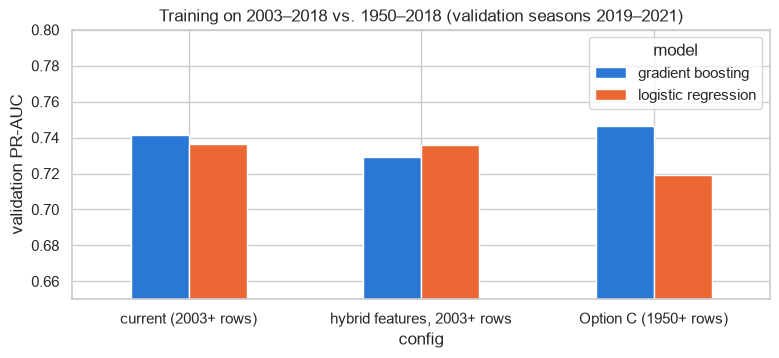

,config,model,training rows,validation ROC-AUC,validation PR-AUC
0,current (2003+ rows),logistic regression,6362,0.939,0.736
1,current (2003+ rows),gradient boosting,6362,0.936,0.741
2,"hybrid features, 2003+ rows",logistic regression,6362,0.939,0.736
3,"hybrid features, 2003+ rows",gradient boosting,6362,0.936,0.729
4,Option C (1950+ rows),logistic regression,22403,0.936,0.719
5,Option C (1950+ rows),gradient boosting,22403,0.938,0.746


,model,config,PR-AUC difference,95% interval,resamples where better
0,logistic regression,"hybrid features, 2003+ rows",-0.000,"[-0.000, +0.000]",10%
1,logistic regression,Option C (1950+ rows),-0.017,"[-0.046, +0.019]",19%
2,gradient boosting,"hybrid features, 2003+ rows",-0.012,"[-0.033, +0.011]",16%
3,gradient boosting,Option C (1950+ rows),0.005,"[-0.024, +0.031]",66%


In [ ]:
HISTORY_CONFIGS = {   # name: (rows, features, preprocessor)
    "current (2003+ rows)": (modeling_table, FEATURES, make_preprocessor),
    "hybrid features, 2003+ rows": (all_seasons[all_seasons["year"] >= FIRST_YEAR], HYBRID_FEATURES, make_hybrid_preprocessor),
    "Option C (1950+ rows)": (all_seasons, HYBRID_FEATURES, make_hybrid_preprocessor),
}
HISTORY_MODELS = {
    "logistic regression": lambda: LogisticRegression(max_iter=1000),
    "gradient boosting": lambda: HistGradientBoostingClassifier(random_state=0, early_stopping=False),
}

# Same 1,193 validation rows, in the same order, for every configuration (the test seasons are not used)
validation_keys = modeling_table.loc[modeling_table["split"] == "validation", ["raceId", "driverId", "podium"]]
y_val_history = validation_keys["podium"].values
races_of_val = {race: np.flatnonzero(validation_keys["raceId"].values == race) for race in validation_keys["raceId"].unique()}
history_probs, history_rows = {}, []
for config, (rows, feature_list, preprocessor) in HISTORY_CONFIGS.items():
    fit_rows = rows[rows["split"] == "train"]
    val_rows = validation_keys[["raceId", "driverId"]].merge(rows, on=["raceId", "driverId"], how="left")
    for model_name, make_model in HISTORY_MODELS.items():
        model = make_pipeline(preprocessor(), make_model()).fit(fit_rows[feature_list], fit_rows["podium"])
        p = model.predict_proba(val_rows[feature_list])[:, 1]
        history_probs[config, model_name] = p
        history_rows.append({"config": config, "model": model_name, "training rows": len(fit_rows),
                             "validation ROC-AUC": roc_auc_score(y_val_history, p),
                             "validation PR-AUC": average_precision_score(y_val_history, p)})
history_results = pd.DataFrame(history_rows)

# Paired bootstrap over the 60 validation races: PR-AUC difference to the current implementation
rng = np.random.default_rng(0)
resamples = [np.concatenate([races_of_val[race] for race in rng.choice(list(races_of_val), size=len(races_of_val))])
             for _ in range(1000)]
differences = []
for model_name in HISTORY_MODELS:
    base = history_probs["current (2003+ rows)", model_name]
    for config in list(HISTORY_CONFIGS)[1:]:
        p = history_probs[config, model_name]
        d = np.array([average_precision_score(y_val_history[r], p[r]) - average_precision_score(y_val_history[r], base[r])
                      for r in resamples])
        differences.append({"model": model_name, "config": config,
                            "PR-AUC difference": average_precision_score(y_val_history, p) - average_precision_score(y_val_history, base),
                            "95% interval": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]",
                            "resamples where better": f"{np.mean(d > 0):.0%}"})

ax = history_results.pivot(index="config", columns="model", values="validation PR-AUC").loc[list(HISTORY_CONFIGS)].plot.bar(
    figsize=(9, 3.5), rot=0, color=["#2a78d6", "#eb6834"])
ax.set_ylim(0.65, 0.80)
ax.set_ylabel("validation PR-AUC")
ax.set_title("Training on 2003–2018 vs. 1950–2018 (validation seasons 2019–2021)")
plt.show()
display(history_results.round(3))
pd.DataFrame(differences).round(3)

**Results (validation seasons 2019–2021):**

| Configuration | Model | Validation PR-AUC | Difference to current | 95% interval | Resamples where better |
|---|---|---|---|---|---|
| current | logistic regression | 0.736 | | | |
| hybrid features, 2003+ rows | logistic regression | 0.736 | −0.000 | [−0.000, +0.000] | 10% |
| Option C (1950+ rows) | logistic regression | 0.719 | −0.017 | [−0.046, +0.019] | 19% |
| current | gradient boosting | 0.741 | | | |
| hybrid features, 2003+ rows | gradient boosting | 0.729 | −0.012 | [−0.033, +0.011] | 16% |
| Option C (1950+ rows) | gradient boosting | 0.746 | +0.005 | [−0.024, +0.031] | 66% |

- **The feature change alone costs nothing for the linear model** (0.736 → 0.736): `grid_position` is exactly
  `quali_position + grid_penalty`, so logistic regression can rebuild one from the other. Gradient boosting loses
  0.012, within noise.
- **Adding 16,041 rows from 1950–2002 does not help clearly.** For logistic regression PR-AUC drops by 0.017: one
  linear rule has to fit 70 years in which reliability, field sizes and the meaning of a grid slot changed a lot
  (the era drift seen in 3.6.3). For gradient boosting it rises by 0.005: trees can separate the eras (for example
  through the missing-qualifying flags) and still use the extra rows.
- **Neither change is distinguishable from noise:** both 95% intervals include 0, and the differences are much
  smaller than the standard error of the validation PR-AUC (≈ 0.05, 3.5.5). Tripling the training data moved the
  score by less than one standard error.

**Decision: keep the current implementation** (modelling rows from 2003, older seasons as history only). Option C
adds complexity (a second feature set, two-thirds of the training rows without qualifying information, the 1950s
data issues from 1.4) without a measurable gain, and its effect even changes sign between the two models. The result
is a limitation for the report: the models never learn from pre-2003 races directly, and whether more history helps
depends on the model type.

### 5.5 Experiment Comparison and Interpretation

## 6. Model Explainability (XAI)

### 6.1 Global Permutation Importance

### 6.2 Global SHAP Explanations

### 6.3 Local Prediction Explanation: LIME and/or SHAP

### 6.4 Interpretation and Non-Causal Limitations

## 7. Inference Function

### 7.1 Inference Pipeline

### 7.2 Demonstration with a Complete Record

### 7.3 Demonstration with a Partially Missing Record